# Profiling dan Cleaning Data Kegiatan Usaha Surabaya 2021-2025

## 1. Pendahuluan

**Tujuan notebook:** Menggabungkan data kegiatan usaha tahun 2021-2025, memprofile kualitas data, melakukan cleaning yang terdokumentasi, dan menyiapkan dua dataset yang siap untuk analisis LQ pada tahap berikutnya.

**Deskripsi dataset:** Dataset berisi informasi proyek/usaha Surabaya, termasuk KBLI, judul kegiatan, sektor pembina, lokasi usaha, skala usaha, dan tahun. Data asli tidak dimodifikasi; semua proses cleaning diterapkan pada salinan DataFrame. Notebook ini berhenti pada tahap penyediaan data untuk analisis dan tidak menghitung LQ.

## 2. Penggabungan Data

Dataset sumber merupakan satu workbook dengan lembar terpisah untuk tahun 2021 sampai 2025. Setiap lembar dibaca tanpa mengubah isinya, ditambahkan kolom `Tahun` berdasarkan nama lembar, lalu digabung menjadi satu DataFrame dengan indeks baru.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

candidates = [
    Path.cwd() / "data_raw" / "DETIL PROYEK 2021-2025 ver2.xlsx",
    Path.cwd().parent / "data_raw" / "DETIL PROYEK 2021-2025 ver2.xlsx",
    Path("../data_raw/DETIL PROYEK 2021-2025 ver2.xlsx"),
]
file_path = next((candidate.resolve() for candidate in candidates if candidate.exists()), None)

if file_path is None:
    raise FileNotFoundError("Workbook data_raw tidak ditemukan pada lokasi yang diharapkan.")

print("Sumber data:", file_path)

sheets = pd.read_excel(file_path, sheet_name=None)

data_list = []
for tahun, sheet_data in sheets.items():
    sheet_copy = sheet_data.copy()
    sheet_copy["Tahun"] = int(tahun)
    data_list.append(sheet_copy)

data = pd.concat(data_list, ignore_index=True)

print("Tahun pada data:", sorted(data["Tahun"].dropna().unique().tolist()))
print("Ukuran data gabungan:", data.shape)
print("Daftar kolom:", data.columns.tolist())
display(data.head())

Sumber data: D:\DPMPTSP\Project_Akhir\data_raw\DETIL PROYEK 2021-2025 ver2.xlsx


Tahun pada data: [2021, 2022, 2023, 2024, 2025]
Ukuran data gabungan: (520502, 11)
Daftar kolom: ['NO', 'Id Proyek', 'Kbli', 'Judul Kbli', 'nama_proyek', 'KL/Sektor Pembina', 'Alamat Usaha', 'kecamatan_usaha', 'kelurahan_usaha', 'Uraian Skala Usaha', 'Tahun']


,NO,Id Proyek,Kbli,Judul Kbli,nama_proyek,KL/Sektor Pembina,Alamat Usaha,kecamatan_usaha,kelurahan_usaha,Uraian Skala Usaha,Tahun
0,1,R-201912162122278037713,20232.0,"Industri Kosmetik Untuk Manusia, Termasuk Past...",UD HALIMAA,Kementerian Perindustrian,"UD. Halimaa , Jalan Perintis 3/9",Wonokromo,Ngagel Rejo,Usaha Mikro,2021
1,2,R-201912162200557667598,56101.0,Restoran,FRANGIPANI,Kementerian Pariwisata,KOMP. PLAZA GRAHA FAMILY (LOOP) STAND NO. 32.3...,Dukuh Pakis,Pradah Kalikendal,Usaha Mikro,2021
2,3,R-201912162215113027162,20232.0,"Industri Kosmetik Untuk Manusia, Termasuk Past...",UD. MELANI SUPER COSMETICS,Kementerian Perindustrian,(UD. MELANI SUPER COSMETICS) JL. KEMLATEN BARU...,Karang Pilang,Kebraon,Usaha Mikro,2021
3,4,R-201912162215113154387,20232.0,"Industri Kosmetik Untuk Manusia, Termasuk Past...",UD. MELANI SUPER COSMETICS,Kementerian Perindustrian,(UD. MELANI SUPER COSMETICS) Jl. Mastrip Kedur...,Karang Pilang,Kedurus,Usaha Mikro,2021
4,5,R-201912162315510012548,10710.0,Industri Produk Roti Dan Kue,ROTI ERLIE,Kementerian Perindustrian,"ROTI ERLIE, \nJl. Darmo Kali No 29-31",Wonokromo,Darmo,Usaha Kecil,2021


## 3. Profiling Data

Profiling dilakukan pada data gabungan mentah untuk memahami tipe data, missing values, duplikasi, konsistensi KBLI, kategori utama, dan cakupan wilayah sebelum pengambilan keputusan cleaning.

### 3.1 Informasi dan tipe data

In [2]:
print("Informasi dataset mentah:")
data.info()

tipe_data = data.dtypes.astype(str).rename("Tipe Data")
missing_values = data.isna().sum().rename("Jumlah Kosong")
missing_persen = (data.isna().mean() * 100).round(2).rename("Persentase Kosong (%)")

ringkasan_kolom = pd.concat([tipe_data, missing_values, missing_persen], axis=1)
display(ringkasan_kolom)

Informasi dataset mentah:


<class 'pandas.DataFrame'>
RangeIndex: 520502 entries, 0 to 520501
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   NO                  520502 non-null  int64 
 1   Id Proyek           520502 non-null  str   
 2   Kbli                520485 non-null  object
 3   Judul Kbli          520485 non-null  str   
 4   nama_proyek         486304 non-null  str   
 5   KL/Sektor Pembina   520362 non-null  str   
 6   Alamat Usaha        520430 non-null  str   
 7   kecamatan_usaha     520093 non-null  str   
 8   kelurahan_usaha     518746 non-null  str   
 9   Uraian Skala Usaha  520454 non-null  str   
 10  Tahun               520502 non-null  int64 
dtypes: int64(2), object(1), str(8)
memory usage: 131.9+ MB


,Tipe Data,Jumlah Kosong,Persentase Kosong (%)
NO,int64,0,0.00
Id Proyek,str,0,0.00
Kbli,object,17,0.00
Judul Kbli,str,17,0.00
nama_proyek,str,34198,6.57
KL/Sektor Pembina,str,140,0.03
Alamat Usaha,str,72,0.01
kecamatan_usaha,str,409,0.08
kelurahan_usaha,str,1756,0.34
Uraian Skala Usaha,str,48,0.01


### 3.2 Pemeriksaan missing values dan duplikasi

In [3]:
print("Ringkasan missing values:")
display(ringkasan_kolom[ringkasan_kolom["Jumlah Kosong"] > 0])

print("Duplikasi baris identik:", data.duplicated().sum())

kolom_tanpa_no = [kolom for kolom in data.columns if kolom != "NO"]
print("Duplikasi berdasarkan atribut selain NO:", data.duplicated(subset=kolom_tanpa_no).sum())

duplikat_id_tahun = data[data.duplicated(subset=["Tahun", "Id Proyek"], keep=False)].copy()
print("Baris pada ID yang berulang dalam tahun yang sama:", len(duplikat_id_tahun))

Ringkasan missing values:


,Tipe Data,Jumlah Kosong,Persentase Kosong (%)
Kbli,object,17,0.00
Judul Kbli,str,17,0.00
nama_proyek,str,34198,6.57
KL/Sektor Pembina,str,140,0.03
Alamat Usaha,str,72,0.01
kecamatan_usaha,str,409,0.08
kelurahan_usaha,str,1756,0.34
Uraian Skala Usaha,str,48,0.01


Duplikasi baris identik: 0


Duplikasi berdasarkan atribut selain NO: 2


Baris pada ID yang berulang dalam tahun yang sama: 51


### 3.3 Pemeriksaan konsistensi KBLI

In [4]:
kbli_sumber = data["Kbli"]

kbli_normal_preview = (
    kbli_sumber.astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

print("Jumlah KBLI kosong:", kbli_sumber.isna().sum())
print("Jumlah nilai KBLI unik pada data mentah:", kbli_sumber.nunique(dropna=True))
print("Jumlah nilai KBLI unik setelah normalisasi preview:", kbli_normal_preview.nunique(dropna=True))
print("Contoh sebelum dan sesudah normalisasi:")
display(pd.DataFrame({"Kbli_Mentah": kbli_sumber.head(10), "Kbli_Normal_Preview": kbli_normal_preview.head(10)}))

Jumlah KBLI kosong: 17
Jumlah nilai KBLI unik pada data mentah: 3139
Jumlah nilai KBLI unik setelah normalisasi preview: 1700
Contoh sebelum dan sesudah normalisasi:


,Kbli_Mentah,Kbli_Normal_Preview
0,20232.0,20232
1,56101.0,56101
2,20232.0,20232
3,20232.0,20232
4,10710.0,10710
5,23939.0,23939
6,1497.0,01497
7,14111.0,14111
8,14120.0,14120
9,14131.0,14131


### 3.4 Pemeriksaan kategori sektor, skala usaha, dan wilayah

In [5]:
for kolom in ["KL/Sektor Pembina", "Uraian Skala Usaha"]:
    print(f"\n{kolom}")
    display(data[kolom].value_counts(dropna=False).head(20).to_frame("jumlah_baris"))

for kolom in ["kecamatan_usaha", "kelurahan_usaha"]:
    print(f"\nRingkasan {kolom}")
    print("Jumlah nilai unik:", data[kolom].nunique(dropna=True))
    print("Jumlah missing:", data[kolom].isna().sum())

missing_wilayah = pd.crosstab(
    data["kecamatan_usaha"].isna(),
    data["kelurahan_usaha"].isna(),
    rownames=["kecamatan_kosong"],
    colnames=["kelurahan_kosong"]
)
print("Pola missing wilayah:")
display(missing_wilayah)


KL/Sektor Pembina


,jumlah_baris
KL/Sektor Pembina,
Kementerian Perdagangan,233287
Kementerian Perindustrian,111789
Kementerian Pariwisata,73113
Kementerian Pekerjaan Umum,41562
Kementerian Kesehatan,10317
Kementerian Energi dan Sumber Daya Mineral,8969
Kementerian Perhubungan,8958
Kementerian Kelautan dan Perikanan,5520
Kementerian Pertanian,4873



Uraian Skala Usaha


,jumlah_baris
Uraian Skala Usaha,
Usaha Mikro,390415
Usaha Kecil,90253
Usaha Besar,28582
Usaha Menengah,11204
NaN,48



Ringkasan kecamatan_usaha


Jumlah nilai unik: 31
Jumlah missing: 409

Ringkasan kelurahan_usaha


Jumlah nilai unik: 154
Jumlah missing: 1756


Pola missing wilayah:


kelurahan_kosong,False,True
kecamatan_kosong,,
False,518746,1347
True,0,409


### 3.5 Ringkasan hasil profiling

In [6]:
profiling_ringkas = pd.DataFrame({
    "Metrik": [
        "Jumlah baris mentah",
        "Jumlah kolom",
        "Jumlah tahun",
        "Baris duplikat identik",
        "Duplikat selain kolom NO",
        "KBLI kosong",
        "Kecamatan kosong",
        "Kelurahan kosong",
    ],
    "Nilai": [
        len(data),
        data.shape[1],
        data["Tahun"].nunique(),
        data.duplicated().sum(),
        data.duplicated(subset=kolom_tanpa_no).sum(),
        data["Kbli"].isna().sum(),
        data["kecamatan_usaha"].isna().sum(),
        data["kelurahan_usaha"].isna().sum(),
    ]
})
display(profiling_ringkas)

,Metrik,Nilai
0,Jumlah baris mentah,520502
1,Jumlah kolom,11
2,Jumlah tahun,5
3,Baris duplikat identik,0
4,Duplikat selain kolom NO,2
5,KBLI kosong,17
6,Kecamatan kosong,409
7,Kelurahan kosong,1756


## 4. Data Cleaning

Cleaning diterapkan pada salinan data sehingga `data` tetap merupakan dataset gabungan mentah. Keputusan yang diterapkan:

1. Konversi dan normalisasi KBLI menjadi teks lima digit serta menambahkan kode sektor dua digit.
2. Menghapus baris yang tidak memiliki KBLI atau kecamatan, karena kedua informasi penting untuk analisis sektor dan wilayah.
3. Mengisi kelurahan kosong dengan label eksplisit `Tidak Teridentifikasi`.
4. Membersihkan spasi serta menstandardisasi kapitalisasi nama kecamatan dan kelurahan.
5. Tidak menghapus duplikasi lengkap maupun duplikasi atribut karena pemeriksaan awal tidak menunjukkan duplikasi identik dan perbedaan `Id Proyek` lintas waktu dapat mewakili proses bisnis yang sah.

Hasil akhir cleaning disimpan sebagai CSV di `output/data_clean.csv` untuk digunakan kembali tanpa mengulang proses cleaning.


In [7]:
jumlah_baris_sebelum_cleaning = len(data)

data_clean = data.copy()

# Penanganan tipe dan normalisasi KBLI
import re

def normalisasi_kbli(nilai):
    if pd.isna(nilai):
        return pd.NA
    teks = str(nilai).strip().split(".")[0]
    match = re.search(r"\d{5}", teks)
    if match is not None:
        return match.group(0)
    if teks.isdigit():
        return teks.zfill(5)
    return pd.NA

data_clean["Kbli_Clean"] = data_clean["Kbli"].map(normalisasi_kbli).astype("string")
data_clean["KBLI_2digit"] = data_clean["Kbli_Clean"].str[:2]

# Penanganan missing values penting
data_clean = data_clean.dropna(subset=["Kbli_Clean", "kecamatan_usaha"]).copy()
data_clean["kelurahan_usaha"] = data_clean["kelurahan_usaha"].fillna("Tidak Teridentifikasi")

# Standarisasi inkonsistensi teks pada wilayah dan kategori penting
data_clean["kecamatan_usaha"] = data_clean["kecamatan_usaha"].astype("string").str.strip().str.title()
data_clean["kelurahan_usaha"] = data_clean["kelurahan_usaha"].astype("string").str.strip().str.title()
data_clean["KL/Sektor Pembina"] = data_clean["KL/Sektor Pembina"].astype("string").str.strip()
data_clean["Uraian Skala Usaha"] = data_clean["Uraian Skala Usaha"].astype("string").str.strip()

# Alias lama dipertahankan agar kompatibel dengan alur analisis berikutnya
df_clean = data_clean.copy()

print("Jumlah baris sebelum cleaning:", jumlah_baris_sebelum_cleaning)
print("Jumlah baris sesudah cleaning:", len(data_clean))
print("Baris yang dihapus:", jumlah_baris_sebelum_cleaning - len(data_clean))
display(data_clean[["Kbli", "Kbli_Clean", "KBLI_2digit", "Judul Kbli"]].head())

# Simpan dataset hasil cleaning untuk digunakan kembali pada analisis berikutnya.
cleaned_project_dir = Path.cwd().parent if Path.cwd().name.casefold() == "notebooks" else Path.cwd()
cleaned_output_dir = cleaned_project_dir / "output"
cleaned_output_dir.mkdir(parents=True, exist_ok=True)
cleaned_data_path = cleaned_output_dir / "data_clean.csv"
data_clean.to_csv(cleaned_data_path, index=False, encoding="utf-8-sig")
print("Dataset hasil cleaning disimpan:", cleaned_data_path.resolve())
print("Ukuran dataset CSV:", data_clean.shape)


Jumlah baris sebelum cleaning: 520502
Jumlah baris sesudah cleaning: 520077
Baris yang dihapus: 425


,Kbli,Kbli_Clean,KBLI_2digit,Judul Kbli
0,20232.0,20232,20,"Industri Kosmetik Untuk Manusia, Termasuk Past..."
1,56101.0,56101,56,Restoran
2,20232.0,20232,20,"Industri Kosmetik Untuk Manusia, Termasuk Past..."
3,20232.0,20232,20,"Industri Kosmetik Untuk Manusia, Termasuk Past..."
4,10710.0,10710,10,Industri Produk Roti Dan Kue


Dataset hasil cleaning disimpan: D:\DPMPTSP\Project_Akhir\output\data_clean.csv
Ukuran dataset CSV: (520077, 13)


## 5. Validasi Hasil Cleaning

Validasi memastikan aturan cleaning menghasilkan tipe data, missing values, dan konsistensi yang sesuai tanpa menghapus duplikasi yang masih dapat memiliki makna operasional.

In [8]:
missing_setelah_cleaning = data_clean.isna().sum()
missing_utama = missing_setelah_cleaning[[
    "Id Proyek", "Kbli_Clean", "KBLI_2digit", "Tahun",
    "kecamatan_usaha", "kelurahan_usaha", "Uraian Skala Usaha"
]].to_frame("Jumlah Kosong")

validasi = pd.DataFrame({
    "Tahap": ["Data mentah", "Data cleaning"],
    "Jumlah baris": [jumlah_baris_sebelum_cleaning, len(data_clean)],
    "Jumlah kolom": [data.shape[1], data_clean.shape[1]],
    "KBLI unik": [data["Kbli"].nunique(dropna=True), data_clean["Kbli_Clean"].nunique(dropna=True)],
    "Kecamatan unik": [data["kecamatan_usaha"].nunique(dropna=True), data_clean["kecamatan_usaha"].nunique(dropna=True)],
})

print("Perbandingan data sebelum dan sesudah cleaning:")
display(validasi)

print("Missing pada kolom penting setelah cleaning:")
display(missing_utama)

print("Panjang Kbli_Clean bukan lima digit:", data_clean["Kbli_Clean"].dropna().str.len().ne(5).sum())
print("Kode KBLI 2-digit yang kosong:", data_clean["KBLI_2digit"].isna().sum())
print("Baris duplikat identik pada data_clean:", data_clean.duplicated().sum())
print("Kecamatan kosong pada data_clean:", data_clean["kecamatan_usaha"].isna().sum())


Perbandingan data sebelum dan sesudah cleaning:


,Tahap,Jumlah baris,Jumlah kolom,KBLI unik,Kecamatan unik
0,Data mentah,520502,11,3139,31
1,Data cleaning,520077,13,1640,31


Missing pada kolom penting setelah cleaning:


,Jumlah Kosong
Id Proyek,0
Kbli_Clean,0
KBLI_2digit,0
Tahun,0
kecamatan_usaha,0
kelurahan_usaha,0
Uraian Skala Usaha,48


Panjang Kbli_Clean bukan lima digit: 0
Kode KBLI 2-digit yang kosong: 0


Baris duplikat identik pada data_clean: 0
Kecamatan kosong pada data_clean: 0


## 6. Dataset untuk Analisis

**`data_clean` / `df_clean`** adalah dataset utama hasil cleaning dan digunakan untuk analisis yang tidak memerlukan kelengkapan kecamatan.

**`data_wilayah`** merupakan subset khusus analisis wilayah: semua baris kecamatan kosong sudah dikecualikan. Data wilayah juga turun dari dataset cleaning, sehingga normalisasi KBLI dan teks yang sama tetap berlaku.

Dataset asli `data` tidak diubah. Tahap berikutnya dapat melanjutkan analisis LQ tanpa menghitung atau mengubah kedua dataset pada notebook ini.

In [9]:
data_wilayah = data_clean.dropna(subset=["kecamatan_usaha"]).copy()

ringkasan_dataset_akhir = pd.DataFrame({
    "Nama dataset": ["data_clean / df_clean", "data_wilayah"],
    "Jumlah baris": [len(data_clean), len(data_wilayah)],
    "Jumlah kolom": [data_clean.shape[1], data_wilayah.shape[1]],
    "Keterangan": [
        "Dataset utama hasil cleaning; tetap memuat data dengan kelurahan yang belum teridentifikasi",
        "Subset cleaning untuk analisis wilayah; kecamatan kosong telah dikecualikan",
    ]
})

display(ringkasan_dataset_akhir)

print("Dataset siap untuk analisis LQ:")
print("- data_clean / df_clean:", data_clean.shape)
print("- data_wilayah:", data_wilayah.shape)

,Nama dataset,Jumlah baris,Jumlah kolom,Keterangan
0,data_clean / df_clean,520077,13,Dataset utama hasil cleaning; tetap memuat dat...
1,data_wilayah,520077,13,Subset cleaning untuk analisis wilayah; kecama...


Dataset siap untuk analisis LQ:
- data_clean / df_clean: (520077, 13)
- data_wilayah: (520077, 13)


# Analisis Deskriptif dan Pertumbuhan Kegiatan Usaha

Tahap ini melengkapi distribusi kegiatan usaha menurut sektor KBLI 2 digit dan kecamatan. Analisis pertumbuhan YoY dan perbandingan yang sudah tersedia pada notebook serta CSV di `output` digunakan kembali, bukan dihitung ulang. Unit hitung adalah `Id Proyek` unik di setiap tahun dan kelompok analisis.

### Persiapan Analisis Deskriptif (9 Oktober)

Gunakan dataset hasil cleaning `data_wilayah` yang sudah tersedia. Jika kernel belum memuat variabel tersebut, baca `output/data_clean.csv` (bukan data mentah) dan gunakan baris berkecamatan untuk analisis wilayah. Pemeriksaan mengelompokkan data menurut tahun, KBLI 2 digit, dan kecamatan; nama kecamatan hasil standardisasi cleaning tidak dinormalisasi ulang.

In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_dir / "output"
clean_data_path = output_dir / "data_clean.csv"
output_dir.mkdir(parents=True, exist_ok=True)

if "data_wilayah" in globals():
    data_analisis_sumber = data_wilayah
    sumber_analisis = "data_wilayah hasil cleaning yang sudah ada"
else:
    if not clean_data_path.exists():
        raise FileNotFoundError(f"Dataset hasil cleaning tidak ditemukan: {clean_data_path}")
    data_clean_tersimpan = pd.read_csv(clean_data_path, low_memory=False)
    kolom_wajib = ["Id Proyek", "KBLI_2digit", "kecamatan_usaha", "Tahun"]
    kolom_hilang = [kolom for kolom in kolom_wajib if kolom not in data_clean_tersimpan.columns]
    if kolom_hilang:
        raise KeyError(f"Kolom wajib tidak tersedia pada data_clean.csv: {kolom_hilang}")
    data_analisis_sumber = data_clean_tersimpan.loc[
        data_clean_tersimpan["kecamatan_usaha"].notna()
    ].copy()
    sumber_analisis = str(clean_data_path)

kolom_wajib = ["Id Proyek", "KBLI_2digit", "kecamatan_usaha", "Tahun"]
kolom_hilang = [kolom for kolom in kolom_wajib if kolom not in data_analisis_sumber.columns]
if kolom_hilang:
    raise KeyError(f"Kolom wajib tidak tersedia pada dataset hasil cleaning: {kolom_hilang}")
if data_analisis_sumber[kolom_wajib].isna().any().any():
    raise ValueError("Data hasil cleaning masih memiliki nilai kosong pada kolom analisis utama.")

tahun_analisis = list(range(2021, 2026))
data_analisis = data_analisis_sumber.copy()
data_analisis["_tahun_analisis"] = pd.to_numeric(
    data_analisis["Tahun"], errors="raise"
).astype(int)
data_analisis = data_analisis.loc[
    data_analisis["_tahun_analisis"].isin(tahun_analisis)
].copy()
data_analisis["_sektor_kbli"] = (
    data_analisis["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
)
if sorted(data_analisis["_tahun_analisis"].unique().tolist()) != tahun_analisis:
    raise ValueError("Dataset hasil cleaning tidak mencakup seluruh tahun 2021?2025.")

struktur_tahun_sektor_kecamatan = (
    data_analisis.groupby(
        ["_tahun_analisis", "_sektor_kbli", "kecamatan_usaha"],
        as_index=False,
        observed=True,
    )["Id Proyek"]
    .nunique()
    .rename(columns={"_tahun_analisis": "Tahun", "_sektor_kbli": "KBLI_2digit",
                     "Id Proyek": "jumlah_kegiatan_usaha"})
)
jumlah_kombinasi_unik = len(
    data_analisis[["Id Proyek", "_tahun_analisis", "_sektor_kbli", "kecamatan_usaha"]]
    .drop_duplicates()
)
if int(struktur_tahun_sektor_kecamatan["jumlah_kegiatan_usaha"].sum()) != jumlah_kombinasi_unik:
    raise AssertionError("Agregasi tahun-sektor-kecamatan tidak konsisten dengan kombinasi Id Proyek unik.")

ringkasan_struktur = pd.DataFrame([
    {"Metrik": "Sumber data", "Nilai": sumber_analisis},
    {"Metrik": "Baris sumber berkecamatan", "Nilai": len(data_analisis_sumber)},
    {"Metrik": "Baris periode 2021-2025", "Nilai": len(data_analisis)},
    {"Metrik": "Tahun tersedia", "Nilai": ", ".join(map(str, tahun_analisis))},
    {"Metrik": "Jumlah sektor KBLI 2 digit", "Nilai": data_analisis["_sektor_kbli"].nunique()},
    {"Metrik": "Jumlah kecamatan", "Nilai": data_analisis["kecamatan_usaha"].nunique()},
    {"Metrik": "Kombinasi Id Proyek-tahun-sektor-kecamatan unik", "Nilai": jumlah_kombinasi_unik},
    {"Metrik": "Baris berulang pada kombinasi tersebut", "Nilai": len(data_analisis) - jumlah_kombinasi_unik},
])
print("Ringkasan struktur data yang digunakan:")
display(ringkasan_struktur)
print("Contoh agregasi unik per tahun, KBLI 2 digit, dan kecamatan:")
display(struktur_tahun_sektor_kecamatan.head(10))
print("Validasi lulus: jumlah agregasi sama dengan jumlah kombinasi Id Proyek unik.")

Ringkasan struktur data yang digunakan:


,Metrik,Nilai
0,Sumber data,data_wilayah hasil cleaning yang sudah ada
1,Baris sumber berkecamatan,520077
2,Baris periode 2021-2025,520077
3,Tahun tersedia,"2021, 2022, 2023, 2024, 2025"
4,Jumlah sektor KBLI 2 digit,83
5,Jumlah kecamatan,31
6,Kombinasi Id Proyek-tahun-sektor-kecamatan unik,520051
7,Baris berulang pada kombinasi tersebut,26


Contoh agregasi unik per tahun, KBLI 2 digit, dan kecamatan:


,Tahun,KBLI_2digit,kecamatan_usaha,jumlah_kegiatan_usaha
0,2021,01,Asem Rowo,3
1,2021,01,Benowo,10
2,2021,01,Bubutan,5
3,2021,01,Bulak,1
4,2021,01,Dukuh Pakis,9
5,2021,01,Gayungan,8
6,2021,01,Genteng,13
7,2021,01,Gubeng,37
8,2021,01,Gunung Anyar,94
9,2021,01,Jambangan,1


Validasi lulus: jumlah agregasi sama dengan jumlah kombinasi Id Proyek unik.


### Distribusi Kegiatan Usaha Berdasarkan Sektor (12 Oktober)

Sektor direpresentasikan oleh KBLI 2 digit agar sejalan dengan klasifikasi yang telah dipakai pada LQ dan analisis pertumbuhan. Tabel menampilkan jumlah unik per sektor dan tahun serta total periode (penjumlahan hitungan unik tahunan); proyek yang muncul pada beberapa tahun dihitung pada masing-masing tahun. Kolom `Judul_KBLI_5_digit_terbanyak` berisi judul KBLI 5 digit yang paling sering ditemukan pada proyek unik di kelompok tersebut; ini label representatif, bukan nama resmi divisi KBLI 2 digit.

Distribusi kegiatan usaha per sektor KBLI 2 digit (2021-2025):


,KBLI_2digit,2021,2022,2023,2024,2025,Total_kegiatan_2021_2025,Proporsi_total_periode_persen,Judul_KBLI_5_digit_terbanyak
0,47,7143,28631,30196,28848,26984,121802,23.42,Perdagangan Eceran Berbagai Macam Barang Yang ...
1,46,7913,24226,21121,21187,17055,91502,17.59,Perdagangan Besar Berbagai Macam Barang
2,10,1437,7633,16790,24154,8588,58602,11.27,Industri Produk Makanan Lainnya
3,56,1764,9046,14493,16033,13730,55066,10.59,Kedai Makanan
4,41,845,4246,4011,3065,2630,14797,2.85,Konstruksi Gedung Hunian
...,...,...,...,...,...,...,...,...,...
78,65,2,19,17,15,6,59,0.01,Asuransi Umum Konvensional
79,06,5,13,3,7,1,29,0.01,Pertambangan Minyak Bumi
80,87,6,10,0,0,0,16,0.00,Aktivitas Panti Asuhan Swasta
81,88,6,7,0,2,0,15,0.00,Aktivitas Sosial Swasta Tanpa Akomodasi Lainny...


Lima kelompok KBLI dengan jumlah kegiatan-tahun tertinggi dan terendah:


,KBLI_2digit,2021,2022,2023,2024,2025,Total_kegiatan_2021_2025,Proporsi_total_periode_persen,Judul_KBLI_5_digit_terbanyak,Kelompok
0,47,7143,28631,30196,28848,26984,121802,23.42,Perdagangan Eceran Berbagai Macam Barang Yang ...,Jumlah tertinggi
1,46,7913,24226,21121,21187,17055,91502,17.59,Perdagangan Besar Berbagai Macam Barang,Jumlah tertinggi
2,10,1437,7633,16790,24154,8588,58602,11.27,Industri Produk Makanan Lainnya,Jumlah tertinggi
3,56,1764,9046,14493,16033,13730,55066,10.59,Kedai Makanan,Jumlah tertinggi
4,41,845,4246,4011,3065,2630,14797,2.85,Konstruksi Gedung Hunian,Jumlah tertinggi
5,39,7,1,0,0,0,8,0.00,Aktivitas Remediasi dan Pengelolaan Limbah dan...,Jumlah terendah
6,88,6,7,0,2,0,15,0.00,Aktivitas Sosial Swasta Tanpa Akomodasi Lainny...,Jumlah terendah
7,87,6,10,0,0,0,16,0.00,Aktivitas Panti Asuhan Swasta,Jumlah terendah
8,06,5,13,3,7,1,29,0.01,Pertambangan Minyak Bumi,Jumlah terendah
9,65,2,19,17,15,6,59,0.01,Asuransi Umum Konvensional,Jumlah terendah


Tertinggi: KBLI 47 - Perdagangan Eceran Berbagai Macam Barang Yang Utamanya Makanan, Minuman Atau Tembakau Bukan Di Minimarket/Supermarket/Hypermarket (Tradisional) (121,802 kegiatan-tahun).
Terendah: KBLI 39 - Aktivitas Remediasi dan Pengelolaan Limbah dan Sampah Lainnya (8 kegiatan-tahun).


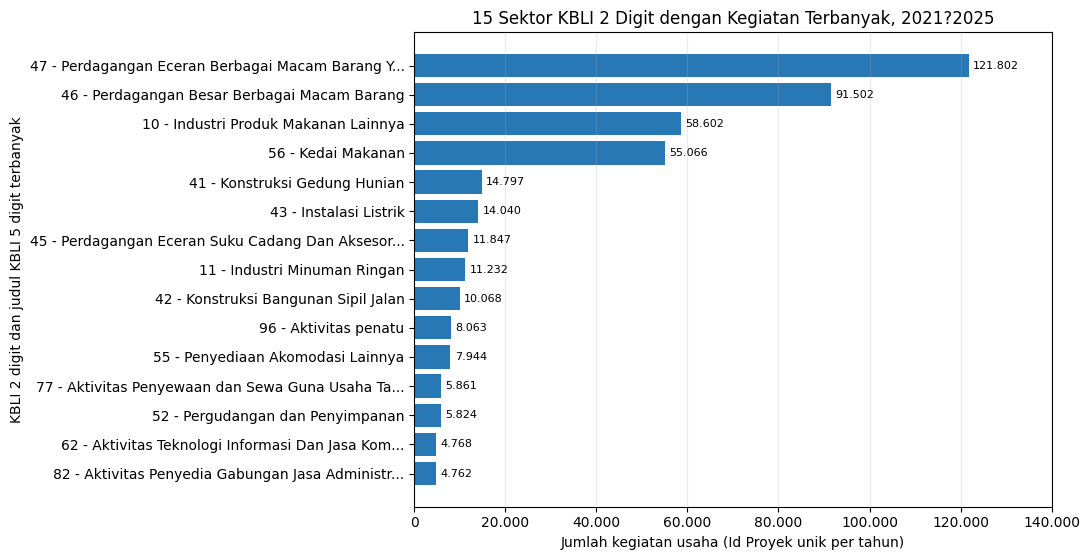

Grafik disimpan: distribusi_kegiatan_usaha_sektor.png


In [11]:
jumlah_sektor_tahunan = (
    data_analisis.groupby(["_sektor_kbli", "_tahun_analisis"], observed=True)["Id Proyek"]
    .nunique()
    .unstack("_tahun_analisis")
    .reindex(columns=tahun_analisis, fill_value=0)
    .fillna(0)
    .astype(int)
)
jumlah_sektor_tahunan.index.name = "KBLI_2digit"
distribusi_sektor = jumlah_sektor_tahunan.copy()
distribusi_sektor["Total_kegiatan_2021_2025"] = distribusi_sektor[tahun_analisis].sum(axis=1)
total_sektor_periode = distribusi_sektor["Total_kegiatan_2021_2025"].sum()
distribusi_sektor["Proporsi_total_periode_persen"] = (
    distribusi_sektor["Total_kegiatan_2021_2025"] / total_sektor_periode * 100
    if total_sektor_periode else np.nan
).round(2)
distribusi_sektor = distribusi_sektor.sort_values(
    "Total_kegiatan_2021_2025", ascending=False
).reset_index()
judul_kbli_per_proyek = data_analisis[["Id Proyek", "_sektor_kbli", "Judul Kbli"]].copy()
judul_kbli_per_proyek["Judul_KBLI_5_digit"] = (
    judul_kbli_per_proyek["Judul Kbli"].astype("string").str.strip()
)
judul_kbli_per_proyek = judul_kbli_per_proyek.dropna(subset=["Judul_KBLI_5_digit"])
judul_kbli_per_proyek = judul_kbli_per_proyek.loc[
    judul_kbli_per_proyek["Judul_KBLI_5_digit"].ne("")
].drop_duplicates(["Id Proyek", "_sektor_kbli", "Judul_KBLI_5_digit"])
judul_kbli_sektor = (
    judul_kbli_per_proyek.groupby(
        ["_sektor_kbli", "Judul_KBLI_5_digit"], as_index=False, observed=True
    )["Id Proyek"]
    .nunique()
    .rename(columns={"Id Proyek": "jumlah_id_proyek"})
    .sort_values(
        ["_sektor_kbli", "jumlah_id_proyek", "Judul_KBLI_5_digit"],
        ascending=[True, False, True],
        kind="stable",
    )
    .drop_duplicates("_sektor_kbli")
    .rename(columns={
        "_sektor_kbli": "KBLI_2digit",
        "Judul_KBLI_5_digit": "Judul_KBLI_5_digit_terbanyak",
    })[["KBLI_2digit", "Judul_KBLI_5_digit_terbanyak"]]
)
distribusi_sektor = distribusi_sektor.merge(
    judul_kbli_sektor, on="KBLI_2digit", how="left", validate="one_to_one"
)
distribusi_sektor["Judul_KBLI_5_digit_terbanyak"] = (
    distribusi_sektor["Judul_KBLI_5_digit_terbanyak"].fillna("Judul KBLI tidak tersedia")
)

sektor_tertinggi = distribusi_sektor.iloc[0]
sektor_terendah = distribusi_sektor.iloc[-1]
print("Distribusi kegiatan usaha per sektor KBLI 2 digit (2021-2025):")
display(distribusi_sektor)
sektor_lima_tertinggi = distribusi_sektor.head(5).assign(Kelompok="Jumlah tertinggi")
sektor_lima_terendah = distribusi_sektor.tail(5).sort_values(
    "Total_kegiatan_2021_2025"
).assign(Kelompok="Jumlah terendah")
print("Lima kelompok KBLI dengan jumlah kegiatan-tahun tertinggi dan terendah:")
display(pd.concat([sektor_lima_tertinggi, sektor_lima_terendah], ignore_index=True))
print(f"Tertinggi: KBLI {sektor_tertinggi['KBLI_2digit']} - {sektor_tertinggi['Judul_KBLI_5_digit_terbanyak']} ({sektor_tertinggi['Total_kegiatan_2021_2025']:,} kegiatan-tahun).")
print(f"Terendah: KBLI {sektor_terendah['KBLI_2digit']} - {sektor_terendah['Judul_KBLI_5_digit_terbanyak']} ({sektor_terendah['Total_kegiatan_2021_2025']:,} kegiatan-tahun).")

jumlah_batang = min(15, len(distribusi_sektor))
plot_sektor = distribusi_sektor.nlargest(jumlah_batang, "Total_kegiatan_2021_2025").sort_values(
    "Total_kegiatan_2021_2025"
)
plot_sektor["Label_sektor"] = plot_sektor.apply(
    lambda baris: (
        f"{baris['KBLI_2digit']} - "
        f"{baris['Judul_KBLI_5_digit_terbanyak'][:42]}"
        f"{'...' if len(baris['Judul_KBLI_5_digit_terbanyak']) > 42 else ''}"
    ),
    axis=1,
)
fig, ax = plt.subplots(figsize=(11, max(5, jumlah_batang * 0.38)))
bars = ax.barh(plot_sektor["Label_sektor"], plot_sektor["Total_kegiatan_2021_2025"], color="#2878B5")
ax.bar_label(bars, labels=[f"{int(value):,}".replace(",", ".") for value in plot_sektor["Total_kegiatan_2021_2025"]], padding=3, fontsize=8)
ax.set_title(f"{jumlah_batang} Sektor KBLI 2 Digit dengan Kegiatan Terbanyak, 2021?2025")
ax.set_xlabel("Jumlah kegiatan usaha (Id Proyek unik per tahun)")
ax.set_ylabel("KBLI 2 digit dan judul KBLI 5 digit terbanyak")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", ".")))
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)
fig.tight_layout()
fig.savefig(output_dir / "distribusi_kegiatan_usaha_sektor.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Grafik disimpan: distribusi_kegiatan_usaha_sektor.png")

### Interpretasi distribusi sektor

Jumlah kegiatan-tahun terkonsentrasi pada beberapa kelompok: tabel dan grafik menampilkan kelompok yang paling banyak beserta jumlahnya, lalu membandingkannya dengan kelompok berjumlah paling sedikit. Judul KBLI 5 digit yang ditampilkan adalah judul paling sering muncul dalam setiap kode dua digit, sehingga berfungsi sebagai contoh representatif dan bukan nama resmi seluruh divisi KBLI.

### Distribusi Kegiatan Usaha Berdasarkan Wilayah (13 Oktober)

Penghitungan wilayah memakai nama kecamatan yang sudah distandardisasi pada tahap cleaning. Setiap Id Proyek dihitung unik dalam masing-masing kecamatan dan tahun; tabel memuat jumlah tahunan dan total periode.

Distribusi kegiatan usaha per kecamatan (2021?2025):


_tahun_analisis,kecamatan_usaha,2021,2022,2023,2024,2025,Total_kegiatan_2021_2025,Proporsi_total_periode_persen
0,Rungkut,2062,7433,7062,7286,6169,30012,5.77
1,Tambaksari,1499,6080,7028,7973,5624,28204,5.42
2,Gubeng,1841,5917,6898,6766,6042,27464,5.28
3,Wonokromo,1420,5939,7452,7101,5188,27100,5.21
4,Sukolilo,2092,6056,6556,6210,5554,26468,5.09
5,Sawahan,1028,4861,6186,7429,4507,24011,4.62
6,Sukomanunggal,1242,4445,6083,4943,3978,20691,3.98
7,Mulyorejo,1279,4181,4289,4964,4290,19003,3.65
8,Kenjeran,635,3088,4339,6311,4254,18627,3.58
9,Wonocolo,981,4123,4938,3788,4283,18113,3.48


Lima kecamatan dengan jumlah kegiatan-tahun tertinggi dan terendah:


_tahun_analisis,kecamatan_usaha,2021,2022,2023,2024,2025,Total_kegiatan_2021_2025,Proporsi_total_periode_persen,Kelompok
0,Rungkut,2062,7433,7062,7286,6169,30012,5.77,Jumlah tertinggi
1,Tambaksari,1499,6080,7028,7973,5624,28204,5.42,Jumlah tertinggi
2,Gubeng,1841,5917,6898,6766,6042,27464,5.28,Jumlah tertinggi
3,Wonokromo,1420,5939,7452,7101,5188,27100,5.21,Jumlah tertinggi
4,Sukolilo,2092,6056,6556,6210,5554,26468,5.09,Jumlah tertinggi
5,Bulak,237,1499,1763,1553,1374,6426,1.24,Jumlah terendah
6,Simokerto,409,1801,2511,2807,1810,9338,1.80,Jumlah terendah
7,Pakal,675,2090,2825,3006,2281,10877,2.09,Jumlah terendah
8,Asem Rowo,663,3101,2575,2783,2459,11581,2.23,Jumlah terendah
9,Benowo,626,2604,2594,3139,2734,11697,2.25,Jumlah terendah


Tertinggi: Rungkut (30,012 kegiatan-tahun).
Terendah: Bulak (6,426 kegiatan-tahun).


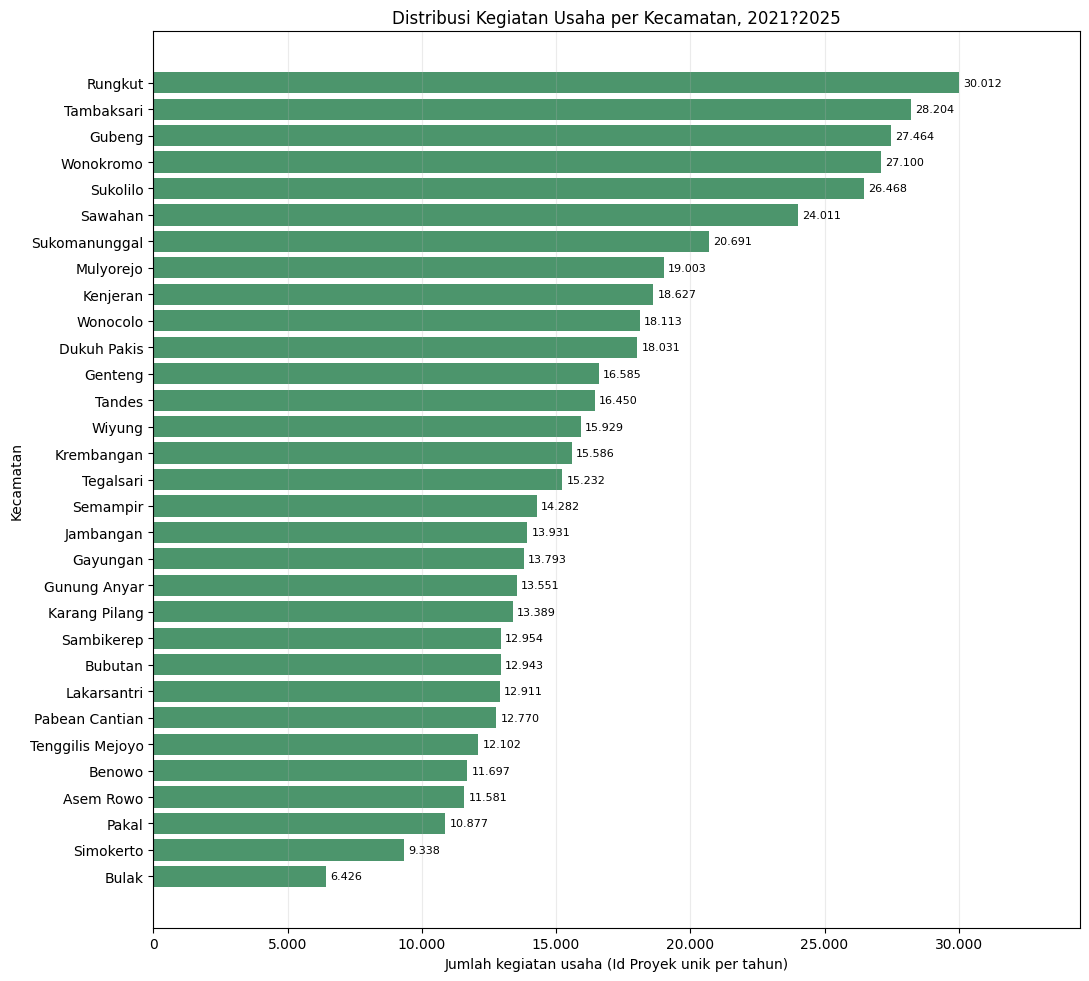

Grafik disimpan: distribusi_kegiatan_usaha_kecamatan.png


In [12]:
jumlah_kecamatan_tahunan = (
    data_analisis.groupby(["kecamatan_usaha", "_tahun_analisis"], observed=True)["Id Proyek"]
    .nunique()
    .unstack("_tahun_analisis")
    .reindex(columns=tahun_analisis, fill_value=0)
    .fillna(0)
    .astype(int)
)
jumlah_kecamatan_tahunan.index.name = "kecamatan_usaha"
distribusi_kecamatan = jumlah_kecamatan_tahunan.copy()
distribusi_kecamatan["Total_kegiatan_2021_2025"] = distribusi_kecamatan[tahun_analisis].sum(axis=1)
total_kecamatan_periode = distribusi_kecamatan["Total_kegiatan_2021_2025"].sum()
distribusi_kecamatan["Proporsi_total_periode_persen"] = (
    distribusi_kecamatan["Total_kegiatan_2021_2025"] / total_kecamatan_periode * 100
    if total_kecamatan_periode else np.nan
).round(2)
distribusi_kecamatan = distribusi_kecamatan.sort_values(
    "Total_kegiatan_2021_2025", ascending=False
).reset_index()

kecamatan_tertinggi = distribusi_kecamatan.iloc[0]
kecamatan_terendah = distribusi_kecamatan.iloc[-1]
print("Distribusi kegiatan usaha per kecamatan (2021?2025):")
display(distribusi_kecamatan)
kecamatan_lima_tertinggi = distribusi_kecamatan.head(5).assign(Kelompok="Jumlah tertinggi")
kecamatan_lima_terendah = distribusi_kecamatan.tail(5).sort_values(
    "Total_kegiatan_2021_2025"
).assign(Kelompok="Jumlah terendah")
print("Lima kecamatan dengan jumlah kegiatan-tahun tertinggi dan terendah:")
display(pd.concat([kecamatan_lima_tertinggi, kecamatan_lima_terendah], ignore_index=True))
print(f"Tertinggi: {kecamatan_tertinggi['kecamatan_usaha']} ({kecamatan_tertinggi['Total_kegiatan_2021_2025']:,} kegiatan-tahun).")
print(f"Terendah: {kecamatan_terendah['kecamatan_usaha']} ({kecamatan_terendah['Total_kegiatan_2021_2025']:,} kegiatan-tahun).")

plot_kecamatan = distribusi_kecamatan.sort_values("Total_kegiatan_2021_2025")
fig, ax = plt.subplots(figsize=(11, max(8, len(plot_kecamatan) * 0.32)))
bars = ax.barh(plot_kecamatan["kecamatan_usaha"], plot_kecamatan["Total_kegiatan_2021_2025"], color="#4C956C")
ax.bar_label(bars, labels=[f"{int(value):,}".replace(",", ".") for value in plot_kecamatan["Total_kegiatan_2021_2025"]], padding=3, fontsize=8)
ax.set_title("Distribusi Kegiatan Usaha per Kecamatan, 2021?2025")
ax.set_xlabel("Jumlah kegiatan usaha (Id Proyek unik per tahun)")
ax.set_ylabel("Kecamatan")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", ".")))
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)
fig.tight_layout()
fig.savefig(output_dir / "distribusi_kegiatan_usaha_kecamatan.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Grafik disimpan: distribusi_kegiatan_usaha_kecamatan.png")

### Interpretasi distribusi wilayah

Distribusi kecamatan dibandingkan memakai jumlah kegiatan-tahun selama 2021-2025. Kecamatan pada lima posisi teratas memiliki jumlah terakumulasi tertinggi, sedangkan lima posisi terbawah menunjukkan jumlah terendah; perbedaan ini bersifat deskriptif dan tidak menjelaskan penyebabnya.

### Analisis Pertumbuhan Kegiatan Usaha (14 Oktober)

Tabel pertumbuhan ditampilkan inline dari cache pendukung agar tetap mengikuti urutan notebook; setelah perhitungan ulang dari dataset cleaning pada Bagian 8, nilainya divalidasi terhadap cache ini. Tahun 2021 tetap NaN karena tidak tersedia pembanding 2020.

### Perbandingan Pertumbuhan Sektor dan Kecamatan (15 Oktober)

Tabel perbandingan menyajikan jumlah setiap tahun, perubahan absolut 2021-2025, dan persentase perubahan. Grafik membandingkan perubahan absolut; persentase tetap tersedia pada tabel agar entitas dengan basis awal kecil tidak ditafsirkan hanya dari persentasenya.

YoY sektor tersimpan (2021?2025):


,KBLI_2digit,Tahun,jumlah_kegiatan_usaha,pertumbuhan_yoy_jumlah,pertumbuhan_yoy_persen,Judul_KBLI_5_digit_terbanyak
0,01,2021,529,NaN,NaN,Pembibitan dan Budidaya Burung Walet
1,01,2022,946,417.0,78.83,Pembibitan dan Budidaya Burung Walet
2,01,2023,809,-137.0,-14.48,Pembibitan dan Budidaya Burung Walet
3,01,2024,730,-79.0,-9.77,Pembibitan dan Budidaya Burung Walet
4,01,2025,775,45.0,6.16,Pembibitan dan Budidaya Burung Walet
...,...,...,...,...,...,...
410,97,2021,16,NaN,NaN,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...
411,97,2022,31,15.0,93.75,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...
412,97,2023,27,-4.0,-12.90,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...
413,97,2024,38,11.0,40.74,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...


YoY kecamatan tersimpan (2021?2025):


,kecamatan_usaha,Tahun,jumlah_kegiatan_usaha,pertumbuhan_yoy_jumlah,pertumbuhan_yoy_persen
0,Asem Rowo,2021,663,NaN,NaN
1,Asem Rowo,2022,3101,2438.0,367.72
2,Asem Rowo,2023,2575,-526.0,-16.96
3,Asem Rowo,2024,2783,208.0,8.08
4,Asem Rowo,2025,2459,-324.0,-11.64
...,...,...,...,...,...
150,Wonokromo,2021,1420,NaN,NaN
151,Wonokromo,2022,5939,4519.0,318.24
152,Wonokromo,2023,7452,1513.0,25.48
153,Wonokromo,2024,7101,-351.0,-4.71


Perbandingan pertumbuhan: jumlah per tahun, perubahan absolut, dan persentase:


,jenis_entitas,nama_entitas,2021,2022,2023,2024,2025,perubahan_2021_2025_jumlah,pertumbuhan_2021_2025_persen,tren
0,KBLI 2 digit,01,529,946,809,730,775,246,46.50,Fluktuatif/tidak konsisten
1,KBLI 2 digit,02,26,131,118,71,53,27,103.85,Fluktuatif/tidak konsisten
2,KBLI 2 digit,03,90,306,316,292,293,203,225.56,Fluktuatif/tidak konsisten
3,KBLI 2 digit,05,10,37,10,9,9,-1,-10.00,Fluktuatif/tidak konsisten
4,KBLI 2 digit,06,5,13,3,7,1,-4,-80.00,Fluktuatif/tidak konsisten
...,...,...,...,...,...,...,...,...,...,...
109,Kecamatan,Tegalsari,712,3156,4061,3850,3453,2741,384.97,Fluktuatif/tidak konsisten
110,Kecamatan,Tenggilis Mejoyo,723,2985,3118,2987,2289,1566,216.60,Fluktuatif/tidak konsisten
111,Kecamatan,Wiyung,1050,3150,3725,4250,3754,2704,257.52,Fluktuatif/tidak konsisten
112,Kecamatan,Wonocolo,981,4123,4938,3788,4283,3302,336.60,Fluktuatif/tidak konsisten


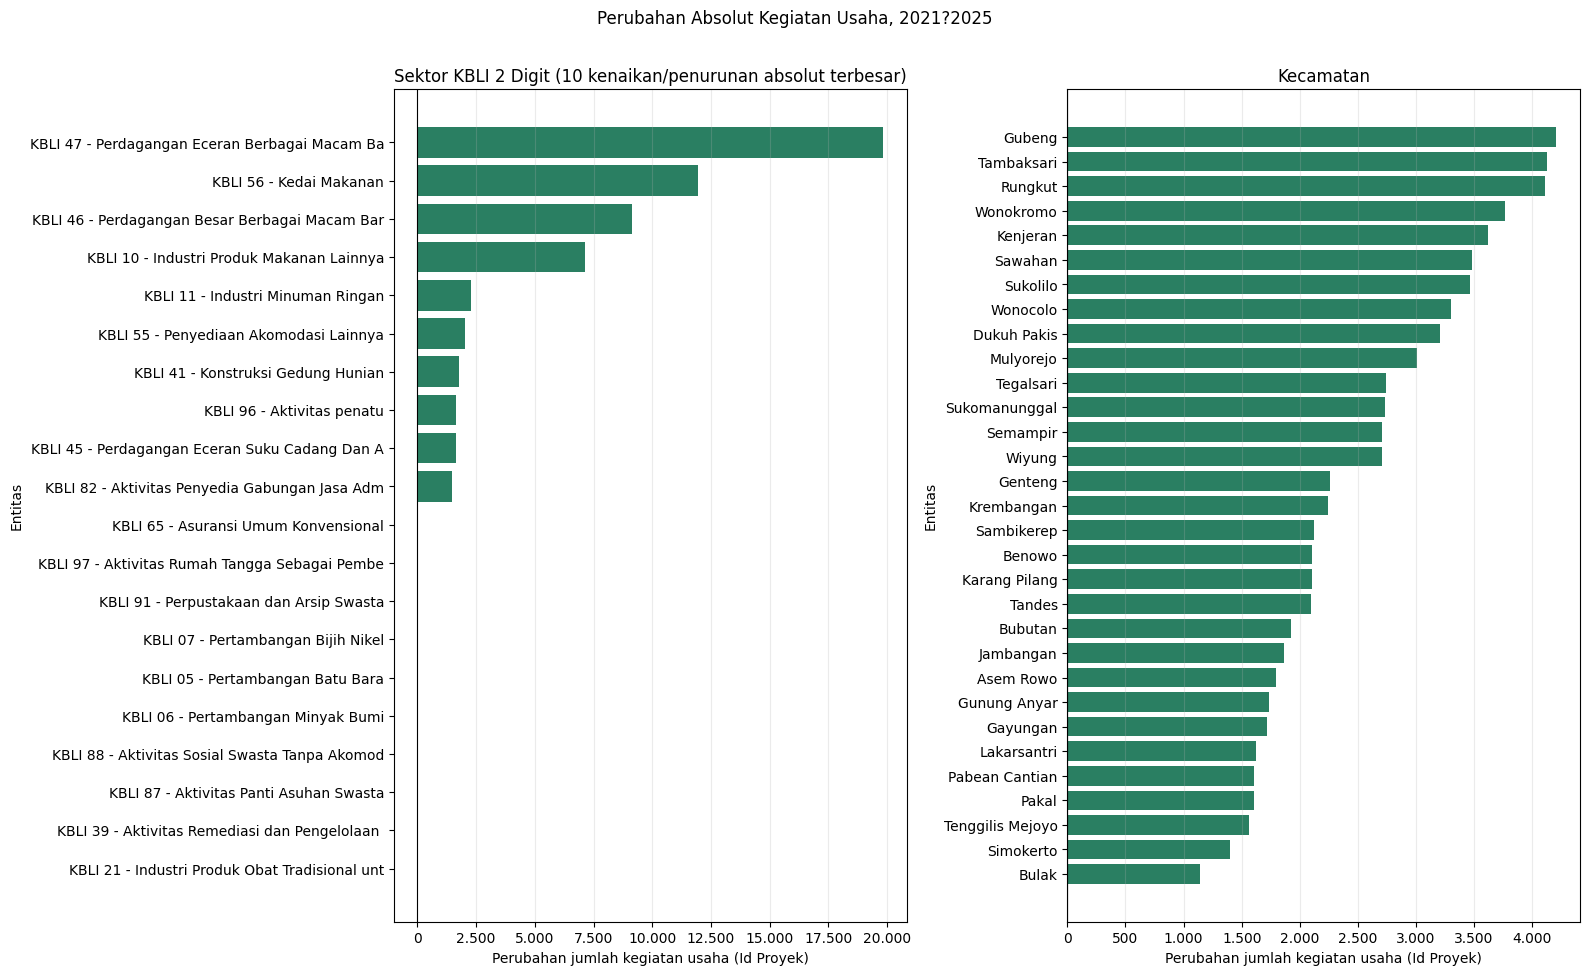

YoY 2021 tervalidasi NaN; tabel pertumbuhan yang ada digunakan tanpa dihitung ulang.
Grafik disimpan: pertumbuhan_kegiatan_usaha_perbandingan.png


In [13]:
file_pertumbuhan_sektor = output_dir / "pertumbuhan_kegiatan_usaha_sektor_yoy.csv"
file_pertumbuhan_kecamatan = output_dir / "pertumbuhan_kegiatan_usaha_wilayah_yoy.csv"
file_perbandingan_pertumbuhan = output_dir / "perbandingan_pertumbuhan_sektor_wilayah.csv"
for path in [file_pertumbuhan_sektor, file_pertumbuhan_kecamatan, file_perbandingan_pertumbuhan]:
    if not path.exists():
        raise FileNotFoundError(f"Hasil pertumbuhan yang sudah ada tidak ditemukan: {path}")
pertumbuhan_sektor_tersimpan = pd.read_csv(file_pertumbuhan_sektor)
pertumbuhan_kecamatan_tersimpan = pd.read_csv(file_pertumbuhan_kecamatan)
perbandingan_pertumbuhan_tersimpan = pd.read_csv(file_perbandingan_pertumbuhan)
pertumbuhan_sektor_tersimpan["KBLI_2digit"] = pertumbuhan_sektor_tersimpan["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
pertumbuhan_sektor_tersimpan = pertumbuhan_sektor_tersimpan.merge(
    judul_kbli_sektor, on="KBLI_2digit", how="left", validate="many_to_one"
)
for nama, tabel in [("sektor", pertumbuhan_sektor_tersimpan), ("kecamatan", pertumbuhan_kecamatan_tersimpan)]:
    kolom = {"Tahun", "jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"}
    if not kolom.issubset(tabel.columns):
        raise KeyError(f"Kolom tabel YoY {nama} tidak lengkap: {sorted(kolom - set(tabel.columns))}")
    baseline = tabel.loc[tabel["Tahun"].eq(2021), "pertumbuhan_yoy_persen"]
    if baseline.empty or baseline.notna().any():
        raise AssertionError(f"YoY tahun 2021 pada tabel {nama} seharusnya NaN.")
kolom_perbandingan = {
    "jenis_entitas", "nama_entitas", "2021", "2022", "2023", "2024", "2025",
    "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen",
}
if not kolom_perbandingan.issubset(perbandingan_pertumbuhan_tersimpan.columns):
    raise KeyError("Tabel perbandingan pertumbuhan tidak memiliki kolom yang diharapkan.")
print("YoY sektor tersimpan (2021?2025):")
display(pertumbuhan_sektor_tersimpan)
print("YoY kecamatan tersimpan (2021?2025):")
display(pertumbuhan_kecamatan_tersimpan)
print("Perbandingan pertumbuhan: jumlah per tahun, perubahan absolut, dan persentase:")
display(perbandingan_pertumbuhan_tersimpan)

perbandingan_pertumbuhan_tersimpan["perubahan_2021_2025_jumlah"] = pd.to_numeric(
    perbandingan_pertumbuhan_tersimpan["perubahan_2021_2025_jumlah"], errors="raise"
)
perbandingan_pertumbuhan_tersimpan["pertumbuhan_2021_2025_persen"] = pd.to_numeric(
    perbandingan_pertumbuhan_tersimpan["pertumbuhan_2021_2025_persen"], errors="coerce"
)
sektor_banding = perbandingan_pertumbuhan_tersimpan.loc[
    perbandingan_pertumbuhan_tersimpan["jenis_entitas"].eq("KBLI 2 digit")
].copy()
sektor_banding["KBLI_2digit"] = sektor_banding["nama_entitas"].astype("string").str.strip().str.zfill(2)
sektor_banding = sektor_banding.merge(judul_kbli_sektor, on="KBLI_2digit", how="left", validate="many_to_one")
sektor_banding["label_grafik"] = sektor_banding.apply(
    lambda row: f"KBLI {row['KBLI_2digit']} - {row['Judul_KBLI_5_digit_terbanyak'][:36]}", axis=1
)
sektor_banding = pd.concat([
    sektor_banding.nlargest(10, "perubahan_2021_2025_jumlah"),
    sektor_banding.nsmallest(10, "perubahan_2021_2025_jumlah"),
]).drop_duplicates("nama_entitas").sort_values("perubahan_2021_2025_jumlah")
kecamatan_banding = perbandingan_pertumbuhan_tersimpan.loc[
    perbandingan_pertumbuhan_tersimpan["jenis_entitas"].eq("Kecamatan")
].sort_values("perubahan_2021_2025_jumlah")

fig, axes = plt.subplots(1, 2, figsize=(16, max(8, len(kecamatan_banding) * 0.31)))
for ax, tabel, label, judul in [
    (axes[0], sektor_banding, "label_grafik", "Sektor KBLI 2 Digit (10 kenaikan/penurunan absolut terbesar)"),
    (axes[1], kecamatan_banding, "nama_entitas", "Kecamatan"),
]:
    perubahan = tabel["perubahan_2021_2025_jumlah"]
    warna = ["#2A7F62" if nilai >= 0 else "#B23A48" for nilai in perubahan]
    ax.barh(tabel[label], perubahan, color=warna)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(judul)
    ax.set_xlabel("Perubahan jumlah kegiatan usaha (Id Proyek)")
    ax.set_ylabel("Entitas")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", ".")))
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Perubahan Absolut Kegiatan Usaha, 2021?2025", y=1.01)
fig.tight_layout()
fig.savefig(output_dir / "pertumbuhan_kegiatan_usaha_perbandingan.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("YoY 2021 tervalidasi NaN; tabel pertumbuhan yang ada digunakan tanpa dihitung ulang.")
print("Grafik disimpan: pertumbuhan_kegiatan_usaha_perbandingan.png")

### Ringkasan Analisis Deskriptif

Ringkasan berikut disusun otomatis dari tabel distribusi dan hasil pertumbuhan yang tersedia. Cache pertumbuhan divalidasi terhadap perhitungan pada Bagian 8; temuan dibatasi pada deskripsi jumlah dan perubahan. LQ tidak dihitung ulang pada ringkasan ini.

In [ ]:
def format_jumlah(nilai):
    return f"{int(nilai):,}".replace(",", ".")

def format_kbli(kode):
    return str(kode).strip().zfill(2)

def format_sektor(sektor):
    return (
        f"KBLI {format_kbli(sektor['KBLI_2digit'])} "
        f"({sektor['Judul_KBLI_5_digit_terbanyak']})"
    )

sektor_puncak = distribusi_sektor.iloc[0]
sektor_bawah = distribusi_sektor.iloc[-1]
kecamatan_puncak = distribusi_kecamatan.iloc[0]
kecamatan_bawah = distribusi_kecamatan.iloc[-1]

def ringkas_pertumbuhan(jenis, tertinggi=True):
    tabel = perbandingan_pertumbuhan_tersimpan.loc[
        perbandingan_pertumbuhan_tersimpan["jenis_entitas"].eq(jenis)
    ].dropna(subset=["pertumbuhan_2021_2025_persen"])
    if tabel.empty:
        return "Data pertumbuhan tidak memadai untuk menentukan perbandingan."
    baris = tabel.loc[tabel["pertumbuhan_2021_2025_persen"].idxmax() if tertinggi else tabel["pertumbuhan_2021_2025_persen"].idxmin()]
    nama = f"KBLI {format_kbli(baris['nama_entitas'])}" if jenis == "KBLI 2 digit" else str(baris["nama_entitas"])
    return (
        f"{nama}: perubahan {int(baris['perubahan_2021_2025_jumlah']):+,} kegiatan "
        f"({baris['pertumbuhan_2021_2025_persen']:+.2f}%), "
        f"dari {format_jumlah(baris['2021'])} pada 2021 menjadi {format_jumlah(baris['2025'])} pada 2025"
    )

ringkasan_analisis = f"""# Ringkasan Analisis Deskriptif dan Pertumbuhan Kegiatan Usaha

Periode analisis: 2021-2025. Unit hitung adalah `Id Proyek` unik dalam setiap tahun dan kelompok sektor/wilayah. Sektor menggunakan KBLI 2 digit; kecamatan mengikuti nama yang telah distandardisasi pada cleaning.

## Temuan distribusi

- Sektor dengan jumlah kegiatan-tahun tertinggi: **{format_sektor(sektor_puncak)}**, {format_jumlah(sektor_puncak['Total_kegiatan_2021_2025'])}.
- Sektor dengan jumlah kegiatan-tahun terendah: **{format_sektor(sektor_bawah)}**, {format_jumlah(sektor_bawah['Total_kegiatan_2021_2025'])}.
- Kecamatan dengan jumlah kegiatan-tahun tertinggi: **{kecamatan_puncak['kecamatan_usaha']}**, {format_jumlah(kecamatan_puncak['Total_kegiatan_2021_2025'])}.
- Kecamatan dengan jumlah kegiatan-tahun terendah: **{kecamatan_bawah['kecamatan_usaha']}**, {format_jumlah(kecamatan_bawah['Total_kegiatan_2021_2025'])}.

## Temuan pertumbuhan 2021-2025

- Pertumbuhan persentase sektor tertinggi: {ringkas_pertumbuhan('KBLI 2 digit', True)}.
- Pertumbuhan persentase sektor terendah: {ringkas_pertumbuhan('KBLI 2 digit', False)}.
- Pertumbuhan persentase kecamatan tertinggi: {ringkas_pertumbuhan('Kecamatan', True)}.
- Pertumbuhan persentase kecamatan terendah: {ringkas_pertumbuhan('Kecamatan', False)}.

Persentase dapat tampak besar bila jumlah awal kecil; karena itu perubahan absolut dan jumlah awal/akhir ditampilkan bersama dan persentase tidak ditafsirkan sendiri. YoY 2021 tidak tersedia karena data 2020 tidak digunakan, sehingga nilainya tetap NaN.

## Pengantar menuju LQ

Distribusi dan pertumbuhan di atas menggambarkan jumlah kegiatan usaha, belum menunjukkan apakah suatu sektor relatif terkonsentrasi pada kecamatan tertentu. Analisis Location Quotient (LQ) yang sudah tersedia digunakan untuk menilai konsentrasi relatif tersebut; LQ tidak dihitung ulang pada tahap ringkasan ini.
"""
from IPython.display import Markdown, display
display(Markdown(ringkasan_analisis))

# Ringkasan Analisis Deskriptif dan Pertumbuhan Kegiatan Usaha

Periode analisis: 2021?2025. Unit hitung adalah `Id Proyek` unik dalam setiap tahun dan kelompok sektor/wilayah. Sektor menggunakan KBLI 2 digit; kecamatan mengikuti nama yang telah distandardisasi pada cleaning.

## Temuan distribusi

- Sektor dengan jumlah kegiatan-tahun tertinggi: **KBLI 47 (Perdagangan Eceran Berbagai Macam Barang Yang Utamanya Makanan, Minuman Atau Tembakau Bukan Di Minimarket/Supermarket/Hypermarket (Tradisional))**, 121.802.
- Sektor dengan jumlah kegiatan-tahun terendah: **KBLI 39 (Aktivitas Remediasi dan Pengelolaan Limbah dan Sampah Lainnya)**, 8.
- Kecamatan dengan jumlah kegiatan-tahun tertinggi: **Rungkut**, 30.012.
- Kecamatan dengan jumlah kegiatan-tahun terendah: **Bulak**, 6.426.

## Temuan pertumbuhan 2021?2025

- Pertumbuhan persentase sektor tertinggi: KBLI 11: perubahan +2,263 kegiatan (+1191.05%), dari 190 pada 2021 menjadi 2.453 pada 2025.
- Pertumbuhan persentase sektor terendah: KBLI 39: perubahan -7 kegiatan (-100.00%), dari 7 pada 2021 menjadi 0 pada 2025.
- Pertumbuhan persentase kecamatan tertinggi: Semampir: perubahan +2,704 kegiatan (+728.84%), dari 371 pada 2021 menjadi 3.075 pada 2025.
- Pertumbuhan persentase kecamatan terendah: Gunung Anyar: perubahan +1,733 kegiatan (+162.57%), dari 1.066 pada 2021 menjadi 2.799 pada 2025.

Persentase dapat tampak besar bila jumlah awal kecil; karena itu perubahan absolut dan jumlah awal/akhir ditampilkan bersama dan persentase tidak ditafsirkan sendiri. YoY 2021 tidak tersedia karena data 2020 tidak digunakan, sehingga nilainya tetap NaN.

## Pengantar menuju LQ

Distribusi dan pertumbuhan di atas menggambarkan jumlah kegiatan usaha, belum menunjukkan apakah suatu sektor relatif terkonsentrasi pada kecamatan tertentu. Analisis Location Quotient (LQ) yang sudah tersedia digunakan untuk menilai konsentrasi relatif tersebut; LQ tidak dihitung ulang pada tahap ringkasan ini.


# 7. Analisis Location Quotient (LQ)

Tahap ini menggunakan dataset `data_wilayah` hasil cleaning. Tidak dilakukan profiling atau cleaning ulang. Unit hitung adalah `Id Proyek` yang dihitung unik (`nunique`) dalam setiap kombinasi sektor-kecamatan-tahun.

## 7.1 Pemeriksaan variabel dan agregasi data

Sebelum dihitung, variabel hasil cleaning dicek untuk memastikan tersedia dan kolom penting tidak kosong.

In [15]:
required_columns = ["Id Proyek", "KBLI_2digit", "kecamatan_usaha", "Tahun"]
missing_columns = [column for column in required_columns if column not in data_wilayah.columns]

if missing_columns:
    raise KeyError(f"Kolom wajib tidak tersedia: {missing_columns}")

print("Data yang digunakan: data_wilayah")
print("Ukuran data:", data_wilayah.shape)
print("Jumlah tahun:", sorted(data_wilayah["Tahun"].unique().tolist()))
print("Jumlah kecamatan:", data_wilayah["kecamatan_usaha"].nunique())
print("Jumlah kode KBLI 2 digit:", data_wilayah["KBLI_2digit"].nunique())

Data yang digunakan: data_wilayah
Ukuran data: (520077, 13)
Jumlah tahun: [2021, 2022, 2023, 2024, 2025]


Jumlah kecamatan: 31
Jumlah kode KBLI 2 digit: 83


## 7.2 Pemeriksaan KBLI 2 digit

Kode yang tidak memiliki dua digit angka atau tidak termasuk klasifikasi KBLI 2020 yang dikenal ditampilkan untuk diperiksa. Tidak ada baris yang dihapus pada tahap ini.

In [16]:
known_kbli_2digit = {
    "01", "02", "03", "05", "06", "07", "08", "09", "10", "11", "12",
    "13", "14", "15", "16", "17", "18", "19", "20", "21", "22", "23",
    "24", "25", "26", "27", "28", "29", "30", "31", "32", "33", "35",
    "36", "37", "38", "39", "41", "42", "43", "45", "46", "47", "49",
    "50", "51", "52", "53", "55", "56", "58", "59", "60", "61", "62",
    "63", "64", "65", "66", "68", "69", "70", "71", "72", "73", "74",
    "75", "77", "78", "79", "80", "81", "82", "84", "85", "86", "87",
    "88", "90", "91", "92", "93", "94", "95", "96", "97", "98", "99"
}

kbli_2digit_unik = (
    data_wilayah["KBLI_2digit"]
    .dropna()
    .astype("string")
    .str.strip()
    .str.zfill(2)
    .unique()
)

kbli_tidak_dikenal = sorted(
    code for code in kbli_2digit_unik
    if code not in known_kbli_2digit
)

print("KBLI 2 digit tidak dikenal:", kbli_tidak_dikenal)

if kbli_tidak_dikenal:
    display(
        data_wilayah[data_wilayah["KBLI_2digit"].isin(kbli_tidak_dikenal)][
            ["Kbli_Clean", "Judul Kbli", "KBLI_2digit", "Tahun"]
        ].drop_duplicates().head(50)
    )

KBLI 2 digit tidak dikenal: []


## 7.3 Agregasi kegiatan usaha

Jumlah kegiatan dihitung sebagai `Id Proyek` unik untuk setiap sektor dua digit, kecamatan, dan tahun. Total kecamatan dan kota dihitung dari agregasi sektor yang sama agar pembilang dan penyebut konsisten.

In [17]:
data_lq = data_wilayah.copy()
data_lq["KBLI_2digit"] = data_lq["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
unit_analisis_kecamatan = (
    data_lq.groupby(["kecamatan_usaha", "KBLI_2digit", "Tahun"], as_index=False)["Id Proyek"]
    .nunique()
    .rename(columns={"Id Proyek": "jumlah_kegiatan_usaha"})
)

unit_analisis_kecamatan["total_kegiatan_kecamatan_tahun"] = (
    unit_analisis_kecamatan.groupby(["kecamatan_usaha", "Tahun"])["jumlah_kegiatan_usaha"]
    .transform("sum")
)

unit_analisis_kecamatan["total_kegiatan_sektor_kota_tahun"] = (
    unit_analisis_kecamatan.groupby(["KBLI_2digit", "Tahun"])["jumlah_kegiatan_usaha"]
    .transform("sum")
)

unit_analisis_kecamatan["total_kegiatan_kota_tahun"] = (
    unit_analisis_kecamatan.groupby("Tahun")["jumlah_kegiatan_usaha"]
    .transform("sum")
)

print("Ukuran tabel agregasi:", unit_analisis_kecamatan.shape)
print("Tahun:", sorted(unit_analisis_kecamatan["Tahun"].unique().tolist()))
display(unit_analisis_kecamatan.head())

Ukuran tabel agregasi: (10280, 7)
Tahun: [2021, 2022, 2023, 2024, 2025]


,kecamatan_usaha,KBLI_2digit,Tahun,jumlah_kegiatan_usaha,total_kegiatan_kecamatan_tahun,total_kegiatan_sektor_kota_tahun,total_kegiatan_kota_tahun
0,Asem Rowo,01,2021,3,663,529,30252
1,Asem Rowo,01,2022,19,3101,946,114972
2,Asem Rowo,01,2023,33,2575,809,129053
3,Asem Rowo,01,2024,15,2783,730,137450
4,Asem Rowo,01,2025,10,2459,775,108324


## 7.4 Perhitungan LQ

Rumus yang digunakan adalah `(jumlah sektor i di kecamatan j / total kegiatan kecamatan j) / (jumlah sektor i di Kota Surabaya / total kegiatan Kota Surabaya)`.

In [18]:
unit_analisis_kecamatan["proporsi_kecamatan"] = (
    unit_analisis_kecamatan["jumlah_kegiatan_usaha"] /
    unit_analisis_kecamatan["total_kegiatan_kecamatan_tahun"]
)
unit_analisis_kecamatan["proporsi_kota"] = (
    unit_analisis_kecamatan["total_kegiatan_sektor_kota_tahun"] /
    unit_analisis_kecamatan["total_kegiatan_kota_tahun"]
)

unit_analisis_kecamatan["LQ"] = (
    unit_analisis_kecamatan["proporsi_kecamatan"] /
    unit_analisis_kecamatan["proporsi_kota"]
).round(4)

unit_analisis_kecamatan["Kategori_LQ"] = unit_analisis_kecamatan["LQ"].apply(
    lambda nilai: "Basis (Konsentrasi Tinggi)" if nilai > 1 else
                  "Setara dengan Kota" if abs(nilai - 1) < 1e-9 else
                  "Non-Basis (Konsentrasi Rendah)"
)

lq_results = unit_analisis_kecamatan.copy()
lq_results["Judul_KBLI_5_digit_terbanyak"] = lq_results["KBLI_2digit"].astype("string").str.zfill(2).map(
    judul_kbli_sektor.set_index("KBLI_2digit")["Judul_KBLI_5_digit_terbanyak"]
)
lq_results["Judul_KBLI_5_digit_terbanyak"] = lq_results["Judul_KBLI_5_digit_terbanyak"].fillna(
    "Judul KBLI tidak tersedia"
)

print("Ukuran tabel hasil LQ:", lq_results.shape)
print("Jumlah LQ dengan nilai tak terbatas:", lq_results["LQ"].isin([float("inf")]).sum())
print("Jumlah LQ kosong:", lq_results["LQ"].isna().sum())
display(lq_results.loc[lq_results["Tahun"].eq(2025), [
    "Tahun", "kecamatan_usaha", "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak",
    "jumlah_kegiatan_usaha", "total_kegiatan_kecamatan_tahun", "LQ", "Kategori_LQ"
]].sort_values("LQ", ascending=False).head(30))

Ukuran tabel hasil LQ: (10280, 12)
Jumlah LQ dengan nilai tak terbatas: 0
Jumlah LQ kosong: 0


,Tahun,kecamatan_usaha,KBLI_2digit,Judul_KBLI_5_digit_terbanyak,jumlah_kegiatan_usaha,total_kegiatan_kecamatan_tahun,LQ,Kategori_LQ
9590,2025,Wonocolo,06,Pertambangan Minyak Bumi,1,4283,25.2916,Basis (Konsentrasi Tinggi)
527,2025,Benowo,65,Asuransi Umum Konvensional,2,2734,13.2070,Basis (Konsentrasi Tinggi)
479,2025,Benowo,51,Angkutan Udara Niaga Berjadwal Dalam Negeri un...,4,2734,12.1911,Basis (Konsentrasi Tinggi)
8550,2025,Tandes,91,Perpustakaan dan Arsip Swasta,3,3152,8.5917,Basis (Konsentrasi Tinggi)
5089,2025,Pabean Cantian,50,Angkutan Laut Dalam Negeri untuk Barang Umum,47,2409,8.3866,Basis (Konsentrasi Tinggi)
9592,2025,Wonocolo,07,Pertambangan Bijih Nikel,4,4283,7.7820,Basis (Konsentrasi Tinggi)
182,2025,Asem Rowo,52,Pergudangan dan Penyimpanan,269,2459,7.5526,Basis (Konsentrasi Tinggi)
6277,2025,Sawahan,07,Pertambangan Bijih Nikel,4,4507,7.3953,Basis (Konsentrasi Tinggi)
1896,2025,Genteng,05,Pertambangan Batu Bara,2,3278,7.3435,Basis (Konsentrasi Tinggi)
4091,2025,Krembangan,53,Aktivitas Agen Kurir,73,2952,7.3190,Basis (Konsentrasi Tinggi)


## 7.5 Ringkasan kategori LQ

Jumlah kombinasi kecamatan-KBLI dan jumlah kegiatan aktual menurut kategori LQ per tahun:


,Tahun,Kategori_LQ,jumlah_kombinasi_kecamatan_sektor,jumlah_kegiatan_usaha
0,2021,Basis (Konsentrasi Tinggi),916,17979
1,2021,Non-Basis (Konsentrasi Rendah),822,12273
2,2022,Basis (Konsentrasi Tinggi),1007,62045
3,2022,Non-Basis (Konsentrasi Rendah),1160,52927
4,2023,Basis (Konsentrasi Tinggi),962,68711
5,2023,Non-Basis (Konsentrasi Rendah),1164,60342
6,2024,Basis (Konsentrasi Tinggi),1031,81019
7,2024,Non-Basis (Konsentrasi Rendah),1100,56431
8,2025,Basis (Konsentrasi Tinggi),968,59543
9,2025,Non-Basis (Konsentrasi Rendah),1148,48053


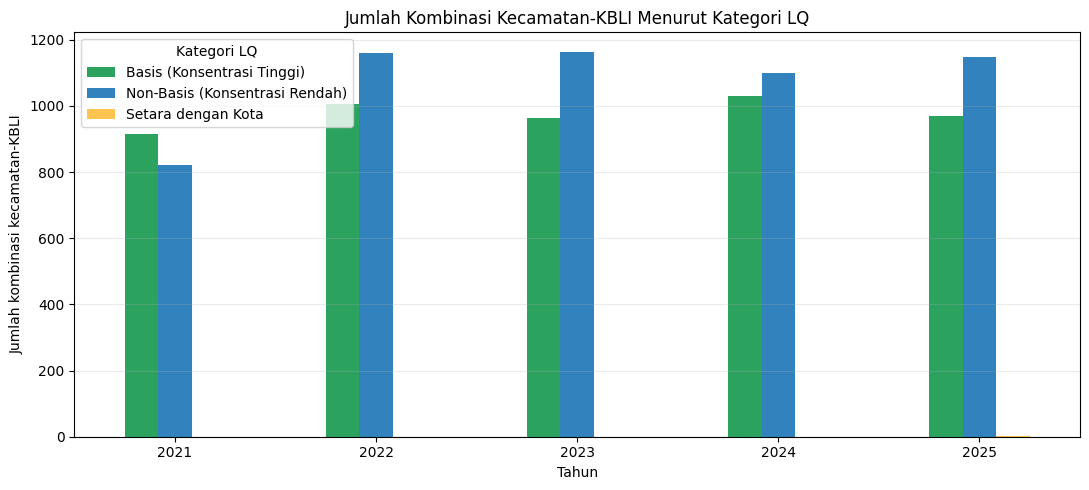

In [19]:
ringkasan_kategori_lq = (
    lq_results.groupby(["Tahun", "Kategori_LQ"], as_index=False)
    .agg(
        jumlah_kombinasi_kecamatan_sektor=("LQ", "size"),
        jumlah_kegiatan_usaha=("jumlah_kegiatan_usaha", "sum"),
    )
    .sort_values(["Tahun", "Kategori_LQ"])
)

print("Jumlah kombinasi kecamatan-KBLI dan jumlah kegiatan aktual menurut kategori LQ per tahun:")
display(ringkasan_kategori_lq)
kategori_lq_plot = ringkasan_kategori_lq.pivot(
    index="Tahun", columns="Kategori_LQ", values="jumlah_kombinasi_kecamatan_sektor"
)
kategori_lq_plot.plot(kind="bar", figsize=(11, 5), color=["#2ca25f", "#3182bd", "#fec44f"])
plt.title("Jumlah Kombinasi Kecamatan-KBLI Menurut Kategori LQ")
plt.xlabel("Tahun")
plt.ylabel("Jumlah kombinasi kecamatan-KBLI")
plt.legend(title="Kategori LQ")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretasi kategori LQ

Nilai LQ mengukur konsentrasi relatif, bukan besarnya jumlah usaha. Karena itu tabel menyandingkan jumlah kombinasi kecamatan-KBLI dengan jumlah kegiatan aktual; kombinasi ber-LQ tinggi tetapi hanya mencakup sedikit proyek perlu dibaca sebagai konsentrasi relatif pada basis kecil, bukan sebagai skala kegiatan yang besar. Bandingkan kategori antarwaktu bersama perubahan komposisi dan jumlah aktual.

## 7.6 Ranking sektor per kecamatan

In [20]:
ranking_sektor_per_kecamatan = (
    lq_results.sort_values(["Tahun", "kecamatan_usaha", "LQ", "KBLI_2digit"],
                           ascending=[True, True, False, True])
    .assign(ranking=lambda frame: frame.groupby(["Tahun", "kecamatan_usaha"])
                                      .cumcount() + 1)
)

top_sektor_per_kecamatan = (
    ranking_sektor_per_kecamatan[ranking_sektor_per_kecamatan["ranking"] <= 5]
    [["Tahun", "kecamatan_usaha", "ranking", "KBLI_2digit", "jumlah_kegiatan_usaha", "LQ", "Kategori_LQ"]]
)
top_sektor_per_kecamatan["KBLI_2digit"] = top_sektor_per_kecamatan["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
top_sektor_per_kecamatan = top_sektor_per_kecamatan.merge(
    judul_kbli_sektor, on="KBLI_2digit", how="left", validate="many_to_one"
)

print("Lima sektor dengan LQ tertinggi pada setiap kecamatan per tahun:")
display(top_sektor_per_kecamatan.head(50))
kecamatan_terpilih_lq = [kecamatan_puncak["kecamatan_usaha"], kecamatan_bawah["kecamatan_usaha"]]
top_sektor_kecamatan_terpilih = top_sektor_per_kecamatan.loc[
    top_sektor_per_kecamatan["Tahun"].eq(2025)
    & top_sektor_per_kecamatan["kecamatan_usaha"].isin(kecamatan_terpilih_lq)
].copy()
top_sektor_kecamatan_terpilih["KBLI_2digit"] = (
    top_sektor_kecamatan_terpilih["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
)
print("Lima sektor LQ tertinggi di kecamatan dengan jumlah kegiatan periode tertinggi dan terendah (2025):")
display(top_sektor_kecamatan_terpilih)
print("20 kombinasi LQ tertinggi tahun 2025 beserta jumlah kegiatan aktual untuk menilai basis yang bertumpu pada jumlah kecil:")
display(lq_results.loc[lq_results["Tahun"].eq(2025)].nlargest(20, "LQ")[[
    "kecamatan_usaha", "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak",
    "jumlah_kegiatan_usaha", "total_kegiatan_kecamatan_tahun", "LQ", "Kategori_LQ"
]])

Lima sektor dengan LQ tertinggi pada setiap kecamatan per tahun:


,Tahun,kecamatan_usaha,ranking,KBLI_2digit,jumlah_kegiatan_usaha,LQ,Kategori_LQ,Judul_KBLI_5_digit_terbanyak
0,2021,Asem Rowo,1,24,7,11.8297,Basis (Konsentrasi Tinggi),Industri Besi Dan Baja Dasar (Iron And Steel M...
1,2021,Asem Rowo,2,52,53,5.0173,Basis (Konsentrasi Tinggi),Pergudangan dan Penyimpanan
2,2021,Asem Rowo,3,11,19,4.5629,Basis (Konsentrasi Tinggi),Industri Minuman Ringan
3,2021,Asem Rowo,4,29,1,3.8024,Basis (Konsentrasi Tinggi),Industri Karoseri Kendaraan Bermotor Roda Empa...
4,2021,Asem Rowo,5,28,5,3.4567,Basis (Konsentrasi Tinggi),Industri Mesin dan Perkakas Mesin Untuk Pengel...
5,2021,Benowo,1,60,1,8.0543,Basis (Konsentrasi Tinggi),Penyiaran Radio Oleh Swasta
6,2021,Benowo,2,22,10,5.0339,Basis (Konsentrasi Tinggi),Industri Perlengkapan Dan Peralatan Rumah Tang...
7,2021,Benowo,3,16,8,4.3439,Basis (Konsentrasi Tinggi),Industri barang Anyaman Dari Tanaman Bukan Rot...
8,2021,Benowo,4,02,2,3.7174,Basis (Konsentrasi Tinggi),Usaha Kehutanan Lainnya
9,2021,Benowo,5,07,1,3.4518,Basis (Konsentrasi Tinggi),Pertambangan Bijih Nikel


Lima sektor LQ tertinggi di kecamatan dengan jumlah kegiatan periode tertinggi dan terendah (2025):


,Tahun,kecamatan_usaha,ranking,KBLI_2digit,jumlah_kegiatan_usaha,LQ,Kategori_LQ,Judul_KBLI_5_digit_terbanyak
635,2025,Bulak,1,31,11,2.8716,Basis (Konsentrasi Tinggi),Industri Furnitur Dari Kayu
636,2025,Bulak,2,25,10,2.6367,Basis (Konsentrasi Tinggi),Industri Barang Dari Logam Aluminium Siap Pasa...
637,2025,Bulak,3,23,3,2.4896,Basis (Konsentrasi Tinggi),Industri Bahan Bangunan Dari Tanah Liat/Kerami...
638,2025,Bulak,4,75,1,2.4637,Basis (Konsentrasi Tinggi),Aktivitas Kesehatan Hewan
639,2025,Bulak,5,03,9,2.4217,Basis (Konsentrasi Tinggi),Pembesaran Ikan Air Tawar Di Kolam
705,2025,Rungkut,1,08,22,4.1538,Basis (Konsentrasi Tinggi),Penggalian Pasir
706,2025,Rungkut,2,37,9,3.3624,Basis (Konsentrasi Tinggi),Treatment dan Pembuangan Air Limbah Tidak Berb...
707,2025,Rungkut,3,12,7,3.1517,Basis (Konsentrasi Tinggi),Industri Bumbu Rokok Serta Kelengkapan Rokok L...
708,2025,Rungkut,4,91,2,2.9266,Basis (Konsentrasi Tinggi),Perpustakaan dan Arsip Swasta
709,2025,Rungkut,5,60,5,2.8322,Basis (Konsentrasi Tinggi),Penyiaran Radio Oleh Swasta


20 kombinasi LQ tertinggi tahun 2025 beserta jumlah kegiatan aktual untuk menilai basis yang bertumpu pada jumlah kecil:


,kecamatan_usaha,KBLI_2digit,Judul_KBLI_5_digit_terbanyak,jumlah_kegiatan_usaha,total_kegiatan_kecamatan_tahun,LQ,Kategori_LQ
9590,Wonocolo,06,Pertambangan Minyak Bumi,1,4283,25.2916,Basis (Konsentrasi Tinggi)
527,Benowo,65,Asuransi Umum Konvensional,2,2734,13.2070,Basis (Konsentrasi Tinggi)
479,Benowo,51,Angkutan Udara Niaga Berjadwal Dalam Negeri un...,4,2734,12.1911,Basis (Konsentrasi Tinggi)
8550,Tandes,91,Perpustakaan dan Arsip Swasta,3,3152,8.5917,Basis (Konsentrasi Tinggi)
5089,Pabean Cantian,50,Angkutan Laut Dalam Negeri untuk Barang Umum,47,2409,8.3866,Basis (Konsentrasi Tinggi)
9592,Wonocolo,07,Pertambangan Bijih Nikel,4,4283,7.7820,Basis (Konsentrasi Tinggi)
182,Asem Rowo,52,Pergudangan dan Penyimpanan,269,2459,7.5526,Basis (Konsentrasi Tinggi)
6277,Sawahan,07,Pertambangan Bijih Nikel,4,4507,7.3953,Basis (Konsentrasi Tinggi)
1896,Genteng,05,Pertambangan Batu Bara,2,3278,7.3435,Basis (Konsentrasi Tinggi)
4091,Krembangan,53,Aktivitas Agen Kurir,73,2952,7.3190,Basis (Konsentrasi Tinggi)


## 7.7 Ranking kecamatan per sektor

In [21]:
ranking_kecamatan_per_sektor = (
    lq_results.sort_values(["Tahun", "KBLI_2digit", "LQ", "kecamatan_usaha"],
                           ascending=[True, True, False, True])
    .assign(ranking=lambda frame: frame.groupby(["Tahun", "KBLI_2digit"])
                                      .cumcount() + 1)
)

top_kecamatan_per_sektor = (
    ranking_kecamatan_per_sektor[ranking_kecamatan_per_sektor["ranking"] <= 5]
    [["Tahun", "KBLI_2digit", "ranking", "kecamatan_usaha", "jumlah_kegiatan_usaha", "LQ", "Kategori_LQ"]]
)
top_kecamatan_per_sektor["KBLI_2digit"] = top_kecamatan_per_sektor["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
top_kecamatan_per_sektor = top_kecamatan_per_sektor.merge(
    judul_kbli_sektor, on="KBLI_2digit", how="left", validate="many_to_one"
)

print("Lima kecamatan dengan LQ tertinggi untuk setiap sektor per tahun:")
display(top_kecamatan_per_sektor.head(50))

Lima kecamatan dengan LQ tertinggi untuk setiap sektor per tahun:


,Tahun,KBLI_2digit,ranking,kecamatan_usaha,jumlah_kegiatan_usaha,LQ,Kategori_LQ,Judul_KBLI_5_digit_terbanyak
0,2021,01,1,Gunung Anyar,94,5.0428,Basis (Konsentrasi Tinggi),Pembibitan dan Budidaya Burung Walet
1,2021,01,2,Wonokromo,81,3.2621,Basis (Konsentrasi Tinggi),Pembibitan dan Budidaya Burung Walet
2,2021,01,3,Sukolilo,97,2.6516,Basis (Konsentrasi Tinggi),Pembibitan dan Budidaya Burung Walet
3,2021,01,4,Wonocolo,34,1.9820,Basis (Konsentrasi Tinggi),Pembibitan dan Budidaya Burung Walet
4,2021,01,5,Gubeng,37,1.1493,Basis (Konsentrasi Tinggi),Pembibitan dan Budidaya Burung Walet
5,2021,02,1,Gayungan,4,5.0534,Basis (Konsentrasi Tinggi),Usaha Kehutanan Lainnya
6,2021,02,2,Benowo,2,3.7174,Basis (Konsentrasi Tinggi),Usaha Kehutanan Lainnya
7,2021,02,3,Pakal,2,3.4475,Basis (Konsentrasi Tinggi),Usaha Kehutanan Lainnya
8,2021,02,4,Semampir,1,3.1362,Basis (Konsentrasi Tinggi),Usaha Kehutanan Lainnya
9,2021,02,5,Tambaksari,4,3.1048,Basis (Konsentrasi Tinggi),Usaha Kehutanan Lainnya


## 7.8 Perbandingan LQ antar tahun 2021-2025

In [22]:
perbandingan_lq_tahunan = (
    lq_results.pivot_table(
        index=["kecamatan_usaha", "KBLI_2digit"],
        columns="Tahun",
        values="LQ",
        aggfunc="first"
    )
    .reset_index()
)

tahun_terururut = [tahun for tahun in range(2021, 2026) if tahun in perbandingan_lq_tahunan.columns]
perbandingan_lq_tahunan["Perubahan_2021_2025"] = (
    perbandingan_lq_tahunan.get(2025) - perbandingan_lq_tahunan.get(2021)
)

print("Perbandingan LQ lintas tahun:")
display(perbandingan_lq_tahunan.head(50))

Perbandingan LQ lintas tahun:


Tahun,kecamatan_usaha,KBLI_2digit,2021,2022,2023,2024,2025,Perubahan_2021_2025
0,Asem Rowo,01,0.2588,0.7447,2.0444,1.0148,0.5684,0.3096
1,Asem Rowo,02,NaN,0.2830,1.2742,4.8694,1.6623,NaN
2,Asem Rowo,03,1.0140,0.6058,1.2688,0.6766,0.7517,-0.2623
3,Asem Rowo,08,NaN,2.3416,9.0302,NaN,NaN,NaN
4,Asem Rowo,09,2.0740,1.0299,2.0882,2.1474,2.0024,-0.0716
5,Asem Rowo,10,2.0639,0.7966,0.9224,0.9304,1.0977,-0.9662
6,Asem Rowo,11,4.5629,1.5368,0.5366,0.9299,1.2212,-3.3417
7,Asem Rowo,13,0.8860,0.6930,0.4728,0.5066,0.8929,0.0069
8,Asem Rowo,14,0.8903,1.1392,0.5050,0.5894,0.6410,-0.2493
9,Asem Rowo,15,3.3799,2.0598,3.2787,1.9560,1.6520,-1.7279


## 7.9 Penyimpanan hasil

In [23]:
from pathlib import Path

output_dir = Path.cwd().parent / "output" if Path.cwd().name == "notebooks" else Path.cwd() / "output"
output_dir.mkdir(parents=True, exist_ok=True)

print("Tabel LQ, ranking, dan perbandingan ditampilkan langsung di notebook.")

Tabel LQ, ranking, dan perbandingan ditampilkan langsung di notebook.


## 7.10 Pemetaan Choropleth Location Quotient (LQ) Kecamatan Kota Surabaya

Peta ini menggunakan hasil LQ yang dihitung dari dataset cleaning dan tersimpan di variabel `lq_results`, serta batas kecamatan dari GeoJSON. Nama kecamatan dinormalisasi untuk pencocokan; nilai LQ yang tidak tersedia tetap ditampilkan sebagai data tidak tersedia.

In [24]:
from pathlib import Path
import json
import re
import unicodedata

import folium
import pandas as pd
from branca.element import MacroElement, Template
from IPython.display import display

project_dir = Path.cwd().parent if Path.cwd().name.casefold() == "notebooks" else Path.cwd()
geojson_candidates = [
    project_dir / "data_processed" / "geojson_kecamatan_surabaya_merged.geojson",
    project_dir / "data_raw" / "geojson_kecamatan_surabaya_merged.geojson",
]
geojson_path = next((path for path in geojson_candidates if path.is_file()), None)
if geojson_path is None:
    raise FileNotFoundError(
        "GeoJSON kecamatan tidak ditemukan. Lokasi yang diperiksa: "
        + ", ".join(str(path) for path in geojson_candidates)
    )
if "lq_results" not in globals():
    raise RuntimeError("Jalankan tahapan perhitungan LQ sebelum membuat peta.")

with geojson_path.open(encoding="utf-8") as file:
    geojson_data = json.load(file)
lq_df = lq_results.copy()

geojson_features = geojson_data.get("features", [])
if not geojson_features:
    raise ValueError(f"GeoJSON tidak berisi features: {geojson_path}")
geojson_property_keys = sorted({
    key
    for feature in geojson_features
    for key in feature.get("properties", {}).keys()
})
print("Kolom hasil LQ:", lq_df.columns.tolist())
print("Properties GeoJSON:", geojson_property_keys)
print("Jumlah feature kecamatan GeoJSON:", len(geojson_features))
print("GeoJSON digunakan:", geojson_path)

required_lq_columns = {"kecamatan_usaha", "KBLI_2digit", "Tahun", "LQ"}
missing_lq_columns = required_lq_columns.difference(lq_df.columns)
if missing_lq_columns:
    raise KeyError(f"Kolom wajib hasil LQ tidak ditemukan: {sorted(missing_lq_columns)}")
if "K" not in geojson_property_keys:
    raise KeyError("Property nama kecamatan 'K' tidak ditemukan pada GeoJSON.")
if len(geojson_features) != 31:
    raise ValueError(f"Diharapkan 31 kecamatan, tetapi GeoJSON berisi {len(geojson_features)} feature.")

def normalize_district_name(name):
    ascii_name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "", ascii_name.casefold())

geo_names_by_key = {}
for feature in geojson_features:
    geo_name = feature.get("properties", {}).get("K")
    if not geo_name:
        raise ValueError("Terdapat feature GeoJSON tanpa nama kecamatan pada property 'K'.")
    name_key = normalize_district_name(geo_name)
    if name_key in geo_names_by_key:
        raise ValueError(f"Nama kecamatan GeoJSON duplikat setelah normalisasi: {geo_name}")
    geo_names_by_key[name_key] = geo_name

lq_df["_nama_kecamatan_norm"] = lq_df["kecamatan_usaha"].map(normalize_district_name)
lq_df["Tahun"] = pd.to_numeric(lq_df["Tahun"], errors="raise").astype(int)
lq_df["KBLI_2digit"] = lq_df["KBLI_2digit"].astype(str).str.strip().str.zfill(2)
lq_df["LQ"] = pd.to_numeric(lq_df["LQ"], errors="coerce")
unknown_districts = sorted(lq_df.loc[
    ~lq_df["_nama_kecamatan_norm"].isin(geo_names_by_key), "kecamatan_usaha"
].unique().tolist())
if unknown_districts:
    raise ValueError(f"Nama kecamatan hasil LQ tidak cocok dengan GeoJSON: {unknown_districts}")
if lq_df.duplicated(["_nama_kecamatan_norm", "Tahun", "KBLI_2digit"]).any():
    raise ValueError("Ditemukan kombinasi kecamatan-tahun-KBLI duplikat pada hasil LQ.")

normalized_column_position = list(lq_df.columns).index("_nama_kecamatan_norm")
lq_lookup = {}
for values in lq_df.itertuples(index=False, name=None):
    name_key = values[normalized_column_position]
    sector = values[list(lq_df.columns).index("KBLI_2digit")]
    year = str(values[list(lq_df.columns).index("Tahun")])
    lq_value = values[list(lq_df.columns).index("LQ")]
    lq_lookup.setdefault(name_key, {}).setdefault(year, {})[sector] = (
        float(lq_value) if pd.notna(lq_value) else None
    )

for feature in geojson_features:
    name_key = normalize_district_name(feature["properties"]["K"])
    feature["properties"]["lq_values"] = lq_lookup.get(name_key, {})

matched_districts = sum(
    normalize_district_name(feature["properties"]["K"]) in lq_lookup
    for feature in geojson_features
)
missing_lq_rows = int(lq_df["LQ"].isna().sum())
years = list(range(2021, 2026))
sectors = sorted(lq_df["KBLI_2digit"].dropna().unique().tolist())
if not sectors:
    raise ValueError("Tidak ada kode KBLI 2 digit pada file hasil LQ.")
print(f"Kecamatan yang terhubung: {matched_districts}/31")
print(f"Jumlah sektor KBLI 2 digit: {len(sectors)}")
print(f"Nilai LQ kosong/tidak numerik di CSV: {missing_lq_rows}")

colors = {
    "basis": "#2ca25f",
    "seimbang": "#fec44f",
    "non_basis": "#3182bd",
    "unavailable": "#bdbdbd",
}
def lq_value_for(feature, year, sector):
    value = feature["properties"].get("lq_values", {}).get(str(year), {}).get(sector)
    return float(value) if value is not None else None

def lq_style(value):
    if value is None:
        color = colors["unavailable"]
    elif value > 1:
        color = colors["basis"]
    elif value == 1:
        color = colors["seimbang"]
    else:
        color = colors["non_basis"]
    return {"fillColor": color, "color": "#333333", "weight": 1, "fillOpacity": 0.78}

selected_year = 2021
selected_sector = "01" if "01" in sectors else sectors[0]
lq_map = folium.Map(
    location=[-7.2575, 112.7521],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True,
)
geojson_layer = folium.GeoJson(
    data=geojson_data,
    name="LQ per kecamatan",
    style_function=lambda feature: lq_style(lq_value_for(feature, selected_year, selected_sector)),
    highlight_function=lambda feature: {"weight": 3, "color": "#222222", "fillOpacity": 0.9},
    smooth_factor=0.5,
).add_to(lq_map)

controls = MacroElement()
controls.years = years
controls.sectors = sectors
controls.sector_labels = {
    str(row.KBLI_2digit): f"KBLI {row.KBLI_2digit} - {row.Judul_KBLI_5_digit_terbanyak[:55]}"
    for row in lq_df[["KBLI_2digit", "Judul_KBLI_5_digit_terbanyak"]].drop_duplicates().itertuples(index=False)
}
controls.geojson_layer_name = geojson_layer.get_name()
controls._template = Template(r"""
{% macro script(this, kwargs) %}
(function() {
    const map = {{ this._parent.get_name() }};
    const geojsonLayer = {{ this.geojson_layer_name }};
    const years = {{ this.years|tojson }};
    const sectors = {{ this.sectors|tojson }};
    const sectorLabels = {{ this.sector_labels|tojson }};
    const colors = {basis: "#2ca25f", seimbang: "#fec44f", nonBasis: "#3182bd", unavailable: "#bdbdbd"};
    const controlId = "lq-filter-" + map._leaflet_id;

    function escapeHtml(value) {
        const element = document.createElement("span");
        element.textContent = value;
        return element.innerHTML;
    }
    function selectionValue(feature, year, sector) {
        const values = feature.properties.lq_values || {};
        const value = values[String(year)] && values[String(year)][sector];
        return value === undefined || value === null || !Number.isFinite(Number(value)) ? null : Number(value);
    }
    function category(value) {
        if (value === null) return "Data tidak tersedia";
        if (value > 1) return "Sektor basis";
        if (value === 1) return "Sektor seimbang";
        return "Sektor non-basis";
    }
    function colorFor(value) {
        if (value === null) return colors.unavailable;
        if (value > 1) return colors.basis;
        if (value === 1) return colors.seimbang;
        return colors.nonBasis;
    }
    function tooltipContent(feature, year, sector, value) {
        const name = escapeHtml(feature.properties.K || "Tidak diketahui");
        const shownValue = value === null ? "Data tidak tersedia" : value.toFixed(4);
        return "<b>Kecamatan:</b> " + name + "<br><b>KBLI:</b> " + escapeHtml(sectorLabels[sector] || sector) +
            "<br><b>Tahun:</b> " + escapeHtml(String(year)) + "<br><b>Nilai LQ:</b> " + shownValue +
            "<br><b>Kategori:</b> " + category(value);
    }
    function applySelection() {
        const year = document.getElementById(controlId + "-year").value;
        const sector = document.getElementById(controlId + "-sector").value;
        let available = 0;
        let unavailable = 0;
        geojsonLayer.eachLayer(function(layer) {
            const feature = layer.feature;
            const value = selectionValue(feature, year, sector);
            if (value === null) unavailable += 1; else available += 1;
            layer.setStyle({fillColor: colorFor(value), color: "#333333", weight: 1, fillOpacity: 0.78});
            const content = tooltipContent(feature, year, sector, value);
            if (layer.getTooltip()) layer.setTooltipContent(content);
            else layer.bindTooltip(content, {sticky: true, direction: "top", opacity: 0.95});
        });
        document.getElementById(controlId + "-coverage").textContent =
            available + " kecamatan tersedia; " + unavailable + " data tidak tersedia (dari 31)";
    }

    const filterControl = L.control({position: "topright"});
    filterControl.onAdd = function() {
        const container = L.DomUtil.create("div", "leaflet-bar lq-filter-control");
        container.id = controlId;
        container.style.cssText = "background:#fff;padding:10px 12px;min-width:210px;font:13px Arial,sans-serif;line-height:1.6";
        container.innerHTML = "<strong>Filter LQ Kecamatan</strong><br><label for='" + controlId + "-year'>Tahun: </label>" +
            "<select id='" + controlId + "-year'></select><br><label for='" + controlId + "-sector'>KBLI 2 digit: </label>" +
            "<select id='" + controlId + "-sector'></select><div id='" + controlId + "-coverage' style='margin-top:5px;font-size:11px'></div>";
        L.DomEvent.disableClickPropagation(container);
        L.DomEvent.disableScrollPropagation(container);
        return container;
    };
    filterControl.addTo(map);
    const yearSelect = document.getElementById(controlId + "-year");
    years.forEach(function(year) {
        const option = document.createElement("option"); option.value = year; option.textContent = year;
        yearSelect.appendChild(option);
    });
    yearSelect.value = "2021";
    const sectorSelect = document.getElementById(controlId + "-sector");
    sectors.forEach(function(sector) {
        const option = document.createElement("option"); option.value = sector; option.textContent = sectorLabels[sector] || sector;
        sectorSelect.appendChild(option);
    });
    sectorSelect.value = sectors.indexOf("01") >= 0 ? "01" : sectors[0];
    yearSelect.addEventListener("change", applySelection);
    sectorSelect.addEventListener("change", applySelection);

    const legend = L.control({position: "bottomright"});
    legend.onAdd = function() {
        const container = L.DomUtil.create("div", "leaflet-bar lq-legend");
        container.style.cssText = "background:#fff;padding:8px 10px;font:12px Arial,sans-serif;line-height:1.7";
        container.innerHTML = "<strong>Kategori LQ</strong><br>" +
            "<span style='color:" + colors.basis + "'>?</span> LQ &gt; 1: Sektor basis<br>" +
            "<span style='color:" + colors.seimbang + "'>?</span> LQ = 1: Sektor seimbang<br>" +
            "<span style='color:" + colors.nonBasis + "'>?</span> LQ &lt; 1: Sektor non-basis<br>" +
            "<span style='color:" + colors.unavailable + "'>?</span> Data tidak tersedia";
        return container;
    };
    legend.addTo(map);
    applySelection();
})();
{% endmacro %}
""")
controls.add_to(lq_map)

html_path = project_dir / "output" / "peta_choropleth_lq_surabaya.html"
html_path.parent.mkdir(parents=True, exist_ok=True)
lq_map.save(str(html_path))
print(f"Peta HTML interaktif disimpan: {html_path.resolve()}")
print(f"Pilihan tahun: {years[0]}-{years[-1]} | jumlah pilihan KBLI: {len(sectors)}")
display(lq_map)


Kolom hasil LQ: ['kecamatan_usaha', 'KBLI_2digit', 'Tahun', 'jumlah_kegiatan_usaha', 'total_kegiatan_kecamatan_tahun', 'total_kegiatan_sektor_kota_tahun', 'total_kegiatan_kota_tahun', 'proporsi_kecamatan', 'proporsi_kota', 'LQ', 'Kategori_LQ', 'Judul_KBLI_5_digit_terbanyak']
Properties GeoJSON: ['K', 'KODE', 'Keterangan', 'LUAS_HA', 'LUAS_KM']
Jumlah feature kecamatan GeoJSON: 31
GeoJSON digunakan: D:\DPMPTSP\Project_Akhir\data_raw\geojson_kecamatan_surabaya_merged.geojson


Kecamatan yang terhubung: 31/31
Jumlah sektor KBLI 2 digit: 83
Nilai LQ kosong/tidak numerik di CSV: 0


Peta HTML interaktif disimpan: D:\DPMPTSP\Project_Akhir\output\peta_choropleth_lq_surabaya.html
Pilihan tahun: 2021-2025 | jumlah pilihan KBLI: 83


In [ ]:
from pathlib import Path
import runpy
from IPython.display import Image, display

project_dir = Path.cwd().parent if Path.cwd().name.casefold() == "notebooks" else Path.cwd()
panel_generator = runpy.run_path(str(project_dir / "scripts" / "generate_lq_map_panels.py"))
candidate_table, selected_sectors, alternatives = panel_generator["select_lq_map_sectors"](
    project_dir, min_activities_2025=20
)

candidate_columns = [
    "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "kategori_gabungan",
    "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "cagr_2021_2025_persen",
    "rata_rata_lq_2021_2025", "jumlah_tahun_lq_tersedia", "status_data",
    "alasan_kelayakan", "skor_representatif", "terpilih", "alasan_pemilihan",
]
print("Kandidat sektor hasil klasifikasi aktual (minimal 20 kegiatan pada 2025):")
display(candidate_table[candidate_columns].rename(columns={
    "KBLI_2digit": "KBLI 2 digit",
    "Judul_KBLI_5_digit_terbanyak": "Judul KBLI 5 digit representatif",
    "kategori_gabungan": "Kategori gabungan",
    "jumlah_kegiatan_2021": "Kegiatan 2021",
    "jumlah_kegiatan_2025": "Kegiatan 2025",
    "cagr_2021_2025_persen": "CAGR (%)",
    "rata_rata_lq_2021_2025": "Rata-rata LQ sektor",
    "jumlah_tahun_lq_tersedia": "Tahun LQ tersedia",
    "status_data": "Status data",
    "alasan_kelayakan": "Pemeriksaan kriteria",
    "skor_representatif": "Skor representatif",
    "terpilih": "Terpilih",
    "alasan_pemilihan": "Alasan pemilihan",
}).style.format({
    "Kegiatan 2021": "{:,.0f}", "Kegiatan 2025": "{:,.0f}",
    "CAGR (%)": "{:+.2f}%", "Rata-rata LQ sektor": "{:.4f}",
    "Tahun LQ tersedia": "{:.0f}/5", "Skor representatif": "{:.3f}",
}))

if not alternatives.empty:
    print("Kategori tanpa kandidat layak; alternatif berikut tidak dipaksakan:")
    display(alternatives[[
        "kategori_diminta", "KBLI_2digit", "jumlah_kegiatan_2021", "jumlah_kegiatan_2025",
        "cagr_2021_2025_persen", "jumlah_tahun_lq_tersedia", "status_data", "alasan_alternatif",
    ]])

if len(selected_sectors) != 3:
    print("Peta tiga panel tidak dibuat karena tidak semua kategori memenuhi kriteria.")
else:
    svg_path, png_path, pdf_path, panel_info = panel_generator["generate_lq_map_panels"](
        project_dir, selected_sectors=selected_sectors, min_activities_2025=20
    )
    coverage = panel_info["district_coverage"]
    summary = selected_sectors[[
        "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "kategori_gabungan",
        "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "cagr_2021_2025_persen",
        "rata_rata_lq_2021_2025", "jumlah_tahun_lq_tersedia",
    ]].rename(columns={
        "KBLI_2digit": "KBLI 2 digit",
        "Judul_KBLI_5_digit_terbanyak": "Judul KBLI 5 digit representatif",
        "kategori_gabungan": "Kategori gabungan",
        "jumlah_kegiatan_2021": "Kegiatan 2021",
        "jumlah_kegiatan_2025": "Kegiatan 2025",
        "cagr_2021_2025_persen": "CAGR (%)",
        "rata_rata_lq_2021_2025": "Rata-rata LQ sektor",
        "jumlah_tahun_lq_tersedia": "Tahun LQ sektor",
    })
    spatial = coverage.groupby("KBLI_2digit").agg(
        kecamatan_dengan_lq=("rata_rata_lq_2021_2025", "count"),
        tahun_min_per_kecamatan=("jumlah_tahun_lq_tersedia", lambda x: x[x.gt(0)].min()),
        tahun_maks_per_kecamatan=("jumlah_tahun_lq_tersedia", "max"),
    ).reset_index()
    summary = summary.merge(spatial, left_on="KBLI 2 digit", right_on="KBLI_2digit").drop(columns="KBLI_2digit")
    print("Ringkasan sektor yang dipetakan:")
    display(summary.style.format({
        "Kegiatan 2021": "{:,.0f}", "Kegiatan 2025": "{:,.0f}",
        "CAGR (%)": "{:+.2f}%", "Rata-rata LQ sektor": "{:.4f}",
        "Tahun LQ sektor": "{:.0f}/5", "kecamatan_dengan_lq": "{:.0f}/31",
        "tahun_min_per_kecamatan": "{:.0f}/5", "tahun_maks_per_kecamatan": "{:.0f}/5",
    }))
    print("Cakupan tahun LQ dan rata-rata per kecamatan; nilai kosong tidak diisi nol:")
    display(coverage.rename(columns={
        "KBLI_2digit": "KBLI 2 digit", "kecamatan_usaha": "Kecamatan",
        "rata_rata_lq_2021_2025": "Rata-rata LQ 2021?2025",
        "jumlah_tahun_lq_tersedia": "Tahun tersedia", "tahun_pengamatan": "Periode",
    }).style.format({"Rata-rata LQ 2021?2025": "{:.4f}", "Tahun tersedia": "{:.0f}/5"}))
    print("Interpretasi ringkas berdasarkan hasil aktual:")
    for sector in selected_sectors.itertuples(index=False):
        lq_position = "di atas 1 (konsentrasi relatif lebih tinggi)" if sector.rata_rata_lq_2021_2025 > 1 else "di bawah 1 (konsentrasi relatif lebih rendah)" if sector.rata_rata_lq_2021_2025 < 1 else "setara dengan 1"
        growth_direction = "meningkat" if sector.cagr_2021_2025_persen > 0 else "menurun/tidak tumbuh"
        print(
            f"KBLI {sector.KBLI_2digit}: rata-rata LQ {sector.rata_rata_lq_2021_2025:.4f} "
            f"({lq_position}); kegiatan {int(sector.jumlah_kegiatan_2021):,} ke "
            f"{int(sector.jumlah_kegiatan_2025):,}, CAGR {sector.cagr_2021_2025_persen:+.2f}% "
            f"({growth_direction}); kategori {sector.kategori_gabungan}."
        )
    print("Pemilihan menyeimbangkan persentil kegiatan 2025 dan CAGR (bobot sama), setelah status Lengkap, LQ lima tahun, CAGR tersedia, dan jumlah minimal terpenuhi.")
    print(f"Kecamatan cocok: {panel_info['matched_district_count']}/{panel_info['district_count']}")
    print(f"Tabel cakupan: {panel_info['coverage_csv'].resolve()}")
    print(f"PNG 350 dpi {panel_info['png_dpi']}: {png_path.resolve()}")
    print(f"SVG: {svg_path.resolve()}")
    print(f"PDF: {pdf_path.resolve()}")
    display(Image(filename=str(png_path), alt="Peta rata-rata LQ 2021?2025 untuk tiga sektor KBLI terpilih di Surabaya"))


**Peta LQ interaktif pada cell 51 tetap menyediakan filter tahun dan KBLI 2 digit.** Cell ini menghasilkan satu gambar statis tiga panel dari hasil LQ tersimpan dan klasifikasi LQ-CAGR yang sudah ada; LQ tidak dihitung ulang. Kandidat wajib berstatus lengkap, memiliki LQ lima tahun dan CAGR, serta sekurang-kurangnya 20 kegiatan pada 2025. Pemilihan menyeimbangkan persentil kegiatan 2025 dan CAGR dengan bobot sama. Jika suatu kategori tidak memiliki kandidat, alternatif ditampilkan tanpa dipaksakan ke peta.

Setiap panel memakai skala warna bersama yang berpusat pada LQ = 1. Rata-rata kecamatan dihitung dari nilai LQ tahunan yang tersedia; cakupan tahun tiap kecamatan ditampilkan dalam tabel dan disimpan sebagai CSV. Data yang tidak tersedia tetap missing dan berwarna abu-abu. Label nama berasal dari judul KBLI 5 digit terbanyak dan merupakan label representatif, bukan nama resmi KBLI 2 digit.

## 8. Analisis Pertumbuhan Kegiatan Usaha Periode 2021-2025

Analisis menggunakan `data_wilayah` hasil cleaning yang sudah tersedia. Unit hitung adalah `Id Proyek` unik (`nunique`) dalam setiap kelompok. Pada analisis sektor, satu proyek dengan beberapa KBLI dapat dihitung pada masing-masing sektor terkait; karena itu jumlah lintas sektor tidak dijumlahkan sebagai total proyek unik kota. Tidak dilakukan cleaning atau profiling ulang.


### 8.1 Validasi kolom dan pertumbuhan tahunan Kota Surabaya


In [25]:
required_growth_columns = ["Id Proyek", "KBLI_2digit", "kecamatan_usaha", "Tahun"]
missing_growth_columns = [column for column in required_growth_columns if column not in data_wilayah.columns]
if missing_growth_columns:
    raise KeyError(f"Kolom wajib tidak tersedia pada data_wilayah: {missing_growth_columns}")

print("Kolom data_wilayah:", data_wilayah.columns.tolist())
print("Ukuran data_wilayah:", data_wilayah.shape)
print("Tahun tersedia:", sorted(pd.to_numeric(data_wilayah["Tahun"], errors="raise").unique().tolist()))

tahun_analisis = list(range(2021, 2026))
data_pertumbuhan = data_wilayah.loc[
    pd.to_numeric(data_wilayah["Tahun"], errors="raise").isin(tahun_analisis)
].copy()
if data_pertumbuhan.empty:
    raise ValueError("Tidak ada baris data_wilayah untuk periode 2021?2025.")
data_pertumbuhan["Tahun"] = pd.to_numeric(data_pertumbuhan["Tahun"], errors="raise").astype(int)
print("Tahun yang dianalisis:", sorted(data_pertumbuhan["Tahun"].unique().tolist()))

jumlah_tahunan = (
    data_pertumbuhan.groupby("Tahun")["Id Proyek"]
    .nunique()
    .reindex(tahun_analisis, fill_value=0)
)
pertumbuhan_tahunan = jumlah_tahunan.rename("jumlah_kegiatan_usaha").rename_axis("Tahun").reset_index()
pertumbuhan_tahunan["pertumbuhan_yoy_jumlah"] = pertumbuhan_tahunan["jumlah_kegiatan_usaha"].diff()
jumlah_sebelumnya = pertumbuhan_tahunan["jumlah_kegiatan_usaha"].shift(1)
pertumbuhan_tahunan["pertumbuhan_yoy_persen"] = (
    pertumbuhan_tahunan["pertumbuhan_yoy_jumlah"] / jumlah_sebelumnya.where(jumlah_sebelumnya.ne(0)) * 100
).round(2)
pertumbuhan_tahunan["perubahan_dari_2021_jumlah"] = (
    pertumbuhan_tahunan["jumlah_kegiatan_usaha"] - pertumbuhan_tahunan["jumlah_kegiatan_usaha"].iloc[0]
)
jumlah_baseline_kota = pertumbuhan_tahunan["jumlah_kegiatan_usaha"].iloc[0]
pertumbuhan_tahunan["perubahan_dari_2021_persen"] = (
    pertumbuhan_tahunan["perubahan_dari_2021_jumlah"] / jumlah_baseline_kota * 100
    if jumlah_baseline_kota != 0 else float("nan")
)
pertumbuhan_tahunan["perubahan_dari_2021_persen"] = pertumbuhan_tahunan["perubahan_dari_2021_persen"].round(2)
print("Pertumbuhan kegiatan usaha tahunan (2021 sebagai baseline; YoY 2021 tidak dihitung):")
display(pertumbuhan_tahunan)


Kolom data_wilayah: ['NO', 'Id Proyek', 'Kbli', 'Judul Kbli', 'nama_proyek', 'KL/Sektor Pembina', 'Alamat Usaha', 'kecamatan_usaha', 'kelurahan_usaha', 'Uraian Skala Usaha', 'Tahun', 'Kbli_Clean', 'KBLI_2digit']
Ukuran data_wilayah: (520077, 13)
Tahun tersedia: [2021, 2022, 2023, 2024, 2025]
Tahun yang dianalisis: [2021, 2022, 2023, 2024, 2025]


Pertumbuhan kegiatan usaha tahunan (2021 sebagai baseline; YoY 2021 tidak dihitung):


,Tahun,jumlah_kegiatan_usaha,pertumbuhan_yoy_jumlah,pertumbuhan_yoy_persen,perubahan_dari_2021_jumlah,perubahan_dari_2021_persen
0,2021,30252,NaN,NaN,0,0.00
1,2022,114972,84720.0,280.05,84720,280.05
2,2023,129053,14081.0,12.25,98801,326.59
3,2024,137449,8396.0,6.51,107197,354.35
4,2025,108324,-29125.0,-21.19,78072,258.07


### 8.2 Pertumbuhan sektor KBLI 2 digit dan kecamatan


In [26]:
# Lengkapi setiap sektor dengan semua tahun pengamatan; kombinasi tanpa catatan memiliki jumlah 0.
data_pertumbuhan["_kbli_2digit"] = data_pertumbuhan["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
sektor_teramati = sorted(data_pertumbuhan["_kbli_2digit"].dropna().unique().tolist())
jumlah_sektor = (
    data_pertumbuhan.dropna(subset=["_kbli_2digit"])
    .groupby(["_kbli_2digit", "Tahun"])["Id Proyek"]
    .nunique()
    .unstack("Tahun")
    .reindex(index=sektor_teramati, columns=tahun_analisis, fill_value=0)
    .fillna(0)
    .astype(int)
)
jumlah_sektor.index.name = "KBLI_2digit"
pertumbuhan_sektor = jumlah_sektor.rename_axis(columns="Tahun").reset_index().melt(
    id_vars="KBLI_2digit", var_name="Tahun", value_name="jumlah_kegiatan_usaha"
)
pertumbuhan_sektor["Tahun"] = pertumbuhan_sektor["Tahun"].astype(int)
pertumbuhan_sektor = pertumbuhan_sektor.sort_values(["KBLI_2digit", "Tahun"]).reset_index(drop=True)
pertumbuhan_sektor["pertumbuhan_yoy_jumlah"] = (
    pertumbuhan_sektor.groupby("KBLI_2digit")["jumlah_kegiatan_usaha"].diff()
)
jumlah_sektor_sebelumnya = pertumbuhan_sektor.groupby("KBLI_2digit")["jumlah_kegiatan_usaha"].shift(1)
pertumbuhan_sektor["pertumbuhan_yoy_persen"] = (
    pertumbuhan_sektor["pertumbuhan_yoy_jumlah"] /
    jumlah_sektor_sebelumnya.where(jumlah_sektor_sebelumnya.ne(0)) * 100
).round(2)
jumlah_sektor["perubahan_2021_2025_jumlah"] = jumlah_sektor[2025] - jumlah_sektor[2021]
jumlah_sektor["pertumbuhan_2021_2025_persen"] = (
    jumlah_sektor["perubahan_2021_2025_jumlah"] /
    jumlah_sektor[2021].replace(0, float("nan")) * 100
).round(2)
perubahan_sektor_tahunan = jumlah_sektor[tahun_analisis].diff(axis=1).iloc[:, 1:]
jumlah_sektor["tren"] = "Fluktuatif/tidak konsisten"
jumlah_sektor.loc[perubahan_sektor_tahunan.gt(0).all(axis=1), "tren"] = "Meningkat konsisten"
jumlah_sektor.loc[perubahan_sektor_tahunan.lt(0).all(axis=1), "tren"] = "Menurun konsisten"
jumlah_sektor.loc[perubahan_sektor_tahunan.eq(0).all(axis=1), "tren"] = "Tidak berubah"
pertumbuhan_sektor_pivot = jumlah_sektor.copy()

# Hitung jumlah proyek unik per kecamatan-tahun, dengan panel 31 kecamatan x 5 tahun.
kecamatan_teramati = sorted(data_pertumbuhan["kecamatan_usaha"].dropna().astype(str).str.strip().unique().tolist())
jumlah_kecamatan = (
    data_pertumbuhan.assign(_kecamatan=data_pertumbuhan["kecamatan_usaha"].astype("string").str.strip())
    .dropna(subset=["_kecamatan"])
    .groupby(["_kecamatan", "Tahun"])["Id Proyek"]
    .nunique()
    .unstack("Tahun")
    .reindex(index=kecamatan_teramati, columns=tahun_analisis, fill_value=0)
    .fillna(0)
    .astype(int)
)
jumlah_kecamatan.index.name = "kecamatan_usaha"
pertumbuhan_wilayah = jumlah_kecamatan.rename_axis(columns="Tahun").reset_index().melt(
    id_vars="kecamatan_usaha", var_name="Tahun", value_name="jumlah_kegiatan_usaha"
)
pertumbuhan_wilayah["Tahun"] = pertumbuhan_wilayah["Tahun"].astype(int)
pertumbuhan_wilayah = pertumbuhan_wilayah.sort_values(["kecamatan_usaha", "Tahun"]).reset_index(drop=True)
pertumbuhan_wilayah["pertumbuhan_yoy_jumlah"] = (
    pertumbuhan_wilayah.groupby("kecamatan_usaha")["jumlah_kegiatan_usaha"].diff()
)
jumlah_kecamatan_sebelumnya = pertumbuhan_wilayah.groupby("kecamatan_usaha")["jumlah_kegiatan_usaha"].shift(1)
pertumbuhan_wilayah["pertumbuhan_yoy_persen"] = (
    pertumbuhan_wilayah["pertumbuhan_yoy_jumlah"] /
    jumlah_kecamatan_sebelumnya.where(jumlah_kecamatan_sebelumnya.ne(0)) * 100
).round(2)
jumlah_kecamatan["perubahan_2021_2025_jumlah"] = jumlah_kecamatan[2025] - jumlah_kecamatan[2021]
jumlah_kecamatan["pertumbuhan_2021_2025_persen"] = (
    jumlah_kecamatan["perubahan_2021_2025_jumlah"] /
    jumlah_kecamatan[2021].replace(0, float("nan")) * 100
).round(2)
perubahan_kecamatan_tahunan = jumlah_kecamatan[tahun_analisis].diff(axis=1).iloc[:, 1:]
jumlah_kecamatan["tren"] = "Fluktuatif/tidak konsisten"
jumlah_kecamatan.loc[perubahan_kecamatan_tahunan.gt(0).all(axis=1), "tren"] = "Meningkat konsisten"
jumlah_kecamatan.loc[perubahan_kecamatan_tahunan.lt(0).all(axis=1), "tren"] = "Menurun konsisten"
jumlah_kecamatan.loc[perubahan_kecamatan_tahunan.eq(0).all(axis=1), "tren"] = "Tidak berubah"
pertumbuhan_wilayah_pivot = jumlah_kecamatan.copy()

print("Jumlah kombinasi sektor-tahun:", len(pertumbuhan_sektor), "| jumlah sektor:", len(sektor_teramati))
print("Jumlah kombinasi kecamatan-tahun:", len(pertumbuhan_wilayah), "| jumlah kecamatan:", len(kecamatan_teramati))
label_kbli = judul_kbli_sektor.set_index("KBLI_2digit")["Judul_KBLI_5_digit_terbanyak"]
pertumbuhan_sektor_tampil = pertumbuhan_sektor.copy()
pertumbuhan_sektor_tampil["Judul_KBLI_5_digit_terbanyak"] = pertumbuhan_sektor_tampil["KBLI_2digit"].map(label_kbli)
print("Pertumbuhan YoY kegiatan usaha berdasarkan KBLI 2 digit:")
display(pertumbuhan_sektor_tampil[["KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "Tahun", "jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"]])
print("Pertumbuhan YoY kegiatan usaha berdasarkan kecamatan:")
display(pertumbuhan_wilayah[["kecamatan_usaha", "Tahun", "jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"]])
print("Ringkasan absolut 2021-2025 per sektor:")
display(pertumbuhan_sektor_pivot.reset_index().merge(judul_kbli_sektor, on="KBLI_2digit", how="left", validate="one_to_one"))
print("Ringkasan absolut 2021-2025 per kecamatan:")
display(pertumbuhan_wilayah_pivot.reset_index())


Jumlah kombinasi sektor-tahun: 415 | jumlah sektor: 83
Jumlah kombinasi kecamatan-tahun: 155 | jumlah kecamatan: 31
Pertumbuhan YoY kegiatan usaha berdasarkan KBLI 2 digit:


,KBLI_2digit,Judul_KBLI_5_digit_terbanyak,Tahun,jumlah_kegiatan_usaha,pertumbuhan_yoy_jumlah,pertumbuhan_yoy_persen
0,01,Pembibitan dan Budidaya Burung Walet,2021,529,NaN,NaN
1,01,Pembibitan dan Budidaya Burung Walet,2022,946,417.0,78.83
2,01,Pembibitan dan Budidaya Burung Walet,2023,809,-137.0,-14.48
3,01,Pembibitan dan Budidaya Burung Walet,2024,730,-79.0,-9.77
4,01,Pembibitan dan Budidaya Burung Walet,2025,775,45.0,6.16
...,...,...,...,...,...,...
410,97,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...,2021,16,NaN,NaN
411,97,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...,2022,31,15.0,93.75
412,97,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...,2023,27,-4.0,-12.90
413,97,Aktivitas Rumah Tangga Sebagai Pemberi Kerja D...,2024,38,11.0,40.74


Pertumbuhan YoY kegiatan usaha berdasarkan kecamatan:


,kecamatan_usaha,Tahun,jumlah_kegiatan_usaha,pertumbuhan_yoy_jumlah,pertumbuhan_yoy_persen
0,Asem Rowo,2021,663,NaN,NaN
1,Asem Rowo,2022,3101,2438.0,367.72
2,Asem Rowo,2023,2575,-526.0,-16.96
3,Asem Rowo,2024,2783,208.0,8.08
4,Asem Rowo,2025,2459,-324.0,-11.64
...,...,...,...,...,...
150,Wonokromo,2021,1420,NaN,NaN
151,Wonokromo,2022,5939,4519.0,318.24
152,Wonokromo,2023,7452,1513.0,25.48
153,Wonokromo,2024,7101,-351.0,-4.71


Ringkasan absolut 2021-2025 per sektor:


,KBLI_2digit,2021,2022,2023,2024,2025,perubahan_2021_2025_jumlah,pertumbuhan_2021_2025_persen,tren,Judul_KBLI_5_digit_terbanyak
0,01,529,946,809,730,775,246,46.50,Fluktuatif/tidak konsisten,Pembibitan dan Budidaya Burung Walet
1,02,26,131,118,71,53,27,103.85,Fluktuatif/tidak konsisten,Usaha Kehutanan Lainnya
2,03,90,306,316,292,293,203,225.56,Fluktuatif/tidak konsisten,Pembesaran Ikan Air Tawar Di Kolam
3,05,10,37,10,9,9,-1,-10.00,Fluktuatif/tidak konsisten,Pertambangan Batu Bara
4,06,5,13,3,7,1,-4,-80.00,Fluktuatif/tidak konsisten,Pertambangan Minyak Bumi
...,...,...,...,...,...,...,...,...,...,...
78,91,11,12,12,12,12,1,9.09,Fluktuatif/tidak konsisten,Perpustakaan dan Arsip Swasta
79,93,90,197,175,247,411,321,356.67,Fluktuatif/tidak konsisten,Pengelolaan Fasilitas Olah raga Lainnya
80,95,162,667,900,784,692,530,327.16,Fluktuatif/tidak konsisten,Reparasi Komputer dan Peralatan Sejenisnya
81,96,252,1369,2160,2381,1901,1649,654.37,Fluktuatif/tidak konsisten,Aktivitas penatu


Ringkasan absolut 2021-2025 per kecamatan:


Tahun,kecamatan_usaha,2021,2022,2023,2024,2025,perubahan_2021_2025_jumlah,pertumbuhan_2021_2025_persen,tren
0,Asem Rowo,663,3101,2575,2783,2459,1796,270.89,Fluktuatif/tidak konsisten
1,Benowo,626,2604,2594,3139,2734,2108,336.74,Fluktuatif/tidak konsisten
2,Bubutan,819,2955,2941,3483,2745,1926,235.16,Fluktuatif/tidak konsisten
3,Bulak,237,1499,1763,1553,1374,1137,479.75,Fluktuatif/tidak konsisten
4,Dukuh Pakis,1015,4299,4279,4215,4223,3208,316.06,Fluktuatif/tidak konsisten
5,Gayungan,921,3274,3863,3099,2636,1715,186.21,Fluktuatif/tidak konsisten
6,Genteng,1019,4391,4068,3829,3278,2259,221.69,Fluktuatif/tidak konsisten
7,Gubeng,1841,5917,6898,6766,6042,4201,228.19,Fluktuatif/tidak konsisten
8,Gunung Anyar,1066,3062,3454,3170,2799,1733,162.57,Fluktuatif/tidak konsisten
9,Jambangan,914,3252,3583,3405,2777,1863,203.83,Fluktuatif/tidak konsisten


### 8.3 Sektor dan kecamatan dengan pertumbuhan tertinggi, terendah, dan konsistensi tren


In [27]:
sektor_ringkas = pertumbuhan_sektor_pivot.reset_index().rename(columns={"KBLI_2digit": "nama_entitas"})
sektor_ringkas.insert(0, "jenis_entitas", "KBLI 2 digit")
wilayah_ringkas = pertumbuhan_wilayah_pivot.reset_index().rename(columns={"kecamatan_usaha": "nama_entitas"})
wilayah_ringkas.insert(0, "jenis_entitas", "Kecamatan")
kolom_perbandingan = [
    "jenis_entitas", "nama_entitas", *tahun_analisis,
    "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen", "tren"
]
perbandingan_pertumbuhan = pd.concat(
    [sektor_ringkas, wilayah_ringkas], ignore_index=True, sort=False
).loc[:, kolom_perbandingan]

sektor_valid = pertumbuhan_sektor_pivot.dropna(subset=["pertumbuhan_2021_2025_persen"])
wilayah_valid = pertumbuhan_wilayah_pivot.dropna(subset=["pertumbuhan_2021_2025_persen"])
if sektor_valid.empty or wilayah_valid.empty:
    raise ValueError("Pertumbuhan kumulatif tidak dapat dibandingkan: seluruh nilai baseline entitas adalah nol.")

entitas_tertinggi_sektor = sektor_valid["pertumbuhan_2021_2025_persen"].idxmax()
entitas_terendah_sektor = sektor_valid["pertumbuhan_2021_2025_persen"].idxmin()
entitas_tertinggi_wilayah = wilayah_valid["pertumbuhan_2021_2025_persen"].idxmax()
entitas_terendah_wilayah = wilayah_valid["pertumbuhan_2021_2025_persen"].idxmin()
ringkasan_pertumbuhan = pd.DataFrame([
    {"kategori": "Sektor tertinggi", "entitas": entitas_tertinggi_sektor,
     "perubahan_2021_2025_jumlah": int(sektor_valid.loc[entitas_tertinggi_sektor, "perubahan_2021_2025_jumlah"]),
     "pertumbuhan_2021_2025_persen": float(sektor_valid.loc[entitas_tertinggi_sektor, "pertumbuhan_2021_2025_persen"])},
    {"kategori": "Sektor terendah", "entitas": entitas_terendah_sektor,
     "perubahan_2021_2025_jumlah": int(sektor_valid.loc[entitas_terendah_sektor, "perubahan_2021_2025_jumlah"]),
     "pertumbuhan_2021_2025_persen": float(sektor_valid.loc[entitas_terendah_sektor, "pertumbuhan_2021_2025_persen"])},
    {"kategori": "Kecamatan tertinggi", "entitas": entitas_tertinggi_wilayah,
     "perubahan_2021_2025_jumlah": int(wilayah_valid.loc[entitas_tertinggi_wilayah, "perubahan_2021_2025_jumlah"]),
     "pertumbuhan_2021_2025_persen": float(wilayah_valid.loc[entitas_tertinggi_wilayah, "pertumbuhan_2021_2025_persen"])},
    {"kategori": "Kecamatan terendah", "entitas": entitas_terendah_wilayah,
     "perubahan_2021_2025_jumlah": int(wilayah_valid.loc[entitas_terendah_wilayah, "perubahan_2021_2025_jumlah"]),
     "pertumbuhan_2021_2025_persen": float(wilayah_valid.loc[entitas_terendah_wilayah, "pertumbuhan_2021_2025_persen"])},
])

ringkasan_tren_sektor = pertumbuhan_sektor_pivot.reset_index().loc[
    :, ["KBLI_2digit", *tahun_analisis, "tren"]
]
ringkasan_tren_kecamatan = pertumbuhan_wilayah_pivot.reset_index().loc[
    :, ["kecamatan_usaha", *tahun_analisis, "tren"]
]
print("Pertumbuhan kumulatif tertinggi/terendah 2021-2025:")
display(ringkasan_pertumbuhan)
print("Jumlah sektor dengan tren meningkat/menurun konsisten:",
      int(pertumbuhan_sektor_pivot["tren"].eq("Meningkat konsisten").sum()), "/",
      int(pertumbuhan_sektor_pivot["tren"].eq("Menurun konsisten").sum()))
print("Rincian sektor dengan tren konsisten:")
display(ringkasan_tren_sektor[ringkasan_tren_sektor["tren"].isin(["Meningkat konsisten", "Menurun konsisten"])])

jumlah_awal = int(pertumbuhan_tahunan.loc[pertumbuhan_tahunan["Tahun"].eq(2021), "jumlah_kegiatan_usaha"].iloc[0])
jumlah_akhir = int(pertumbuhan_tahunan.loc[pertumbuhan_tahunan["Tahun"].eq(2025), "jumlah_kegiatan_usaha"].iloc[0])
print(f"Interpretasi kota: jumlah proyek unik berubah dari {jumlah_awal:,} (2021) menjadi {jumlah_akhir:,} (2025), "
      f"dengan perubahan {jumlah_akhir - jumlah_awal:+,} atau "
      f"{pertumbuhan_tahunan['perubahan_dari_2021_persen'].iloc[-1]:+.2f}% terhadap 2021.")
print(f"Interpretasi sektor: pertumbuhan persentase tertinggi KBLI {entitas_tertinggi_sektor} "
      f"({sektor_valid.loc[entitas_tertinggi_sektor, 'pertumbuhan_2021_2025_persen']:+.2f}%) dan terendah "
      f"KBLI {entitas_terendah_sektor} ({sektor_valid.loc[entitas_terendah_sektor, 'pertumbuhan_2021_2025_persen']:+.2f}%).")
print(f"Interpretasi wilayah: pertumbuhan persentase tertinggi di {entitas_tertinggi_wilayah} "
      f"({wilayah_valid.loc[entitas_tertinggi_wilayah, 'pertumbuhan_2021_2025_persen']:+.2f}%) dan terendah "
      f"di {entitas_terendah_wilayah} ({wilayah_valid.loc[entitas_terendah_wilayah, 'pertumbuhan_2021_2025_persen']:+.2f}%).")
from IPython.display import Markdown, display
display(Markdown(
    f"### Interpretasi pertumbuhan berdasarkan hasil aktual\n\n"
    f"Jumlah kegiatan usaha unik Kota Surabaya berubah dari **{jumlah_awal:,}** pada 2021 menjadi **{jumlah_akhir:,}** pada 2025 "
    f"(perubahan {jumlah_akhir - jumlah_awal:+,}; {pertumbuhan_tahunan['perubahan_dari_2021_persen'].iloc[-1]:+.2f}%). "
    f"Pertumbuhan persentase tertinggi terdapat pada **KBLI {entitas_tertinggi_sektor}** "
    f"({label_kbli.get(entitas_tertinggi_sektor, 'judul tidak tersedia')}; "
    f"{sektor_valid.loc[entitas_tertinggi_sektor, 'pertumbuhan_2021_2025_persen']:+.2f}%), sedangkan terendah pada "
    f"**KBLI {entitas_terendah_sektor}** ({label_kbli.get(entitas_terendah_sektor, 'judul tidak tersedia')}; "
    f"{sektor_valid.loc[entitas_terendah_sektor, 'pertumbuhan_2021_2025_persen']:+.2f}%). "
    f"Pada kecamatan, nilai tertinggi ada di **{entitas_tertinggi_wilayah}** "
    f"({wilayah_valid.loc[entitas_tertinggi_wilayah, 'pertumbuhan_2021_2025_persen']:+.2f}%) dan terendah di "
    f"**{entitas_terendah_wilayah}** ({wilayah_valid.loc[entitas_terendah_wilayah, 'pertumbuhan_2021_2025_persen']:+.2f}%). "
    "Persentase perlu dibaca bersama jumlah awal dan perubahan absolut; hasil ini tidak mengidentifikasi penyebab perubahan."
))


Pertumbuhan kumulatif tertinggi/terendah 2021-2025:


,kategori,entitas,perubahan_2021_2025_jumlah,pertumbuhan_2021_2025_persen
0,Sektor tertinggi,11,2263,1191.05
1,Sektor terendah,39,-7,-100.00
2,Kecamatan tertinggi,Semampir,2704,728.84
3,Kecamatan terendah,Gunung Anyar,1733,162.57


Jumlah sektor dengan tren meningkat/menurun konsisten: 6 / 0
Rincian sektor dengan tren konsisten:


Tahun,KBLI_2digit,2021,2022,2023,2024,2025,tren
60,69,56,138,146,201,222,Meningkat konsisten
67,77,232,1092,1436,1546,1555,Meningkat konsisten
68,78,179,866,947,1203,1463,Meningkat konsisten
72,82,269,881,884,973,1755,Meningkat konsisten
73,85,222,858,870,925,1014,Meningkat konsisten
77,90,31,197,237,249,271,Meningkat konsisten


Interpretasi kota: jumlah proyek unik berubah dari 30,252 (2021) menjadi 108,324 (2025), dengan perubahan +78,072 atau +258.07% terhadap 2021.
Interpretasi sektor: pertumbuhan persentase tertinggi KBLI 11 (+1191.05%) dan terendah KBLI 39 (-100.00%).
Interpretasi wilayah: pertumbuhan persentase tertinggi di Semampir (+728.84%) dan terendah di Gunung Anyar (+162.57%).


### Interpretasi pertumbuhan berdasarkan hasil aktual

Jumlah kegiatan usaha unik Kota Surabaya berubah dari **30,252** pada 2021 menjadi **108,324** pada 2025 (perubahan +78,072; +258.07%). Pertumbuhan persentase tertinggi terdapat pada **KBLI 11** (Industri Minuman Ringan; +1191.05%), sedangkan terendah pada **KBLI 39** (Aktivitas Remediasi dan Pengelolaan Limbah dan Sampah Lainnya; -100.00%). Pada kecamatan, nilai tertinggi ada di **Semampir** (+728.84%) dan terendah di **Gunung Anyar** (+162.57%). Persentase perlu dibaca bersama jumlah awal dan perubahan absolut; hasil ini tidak mengidentifikasi penyebab perubahan.

### 8.4 Visualisasi tren dan pertumbuhan


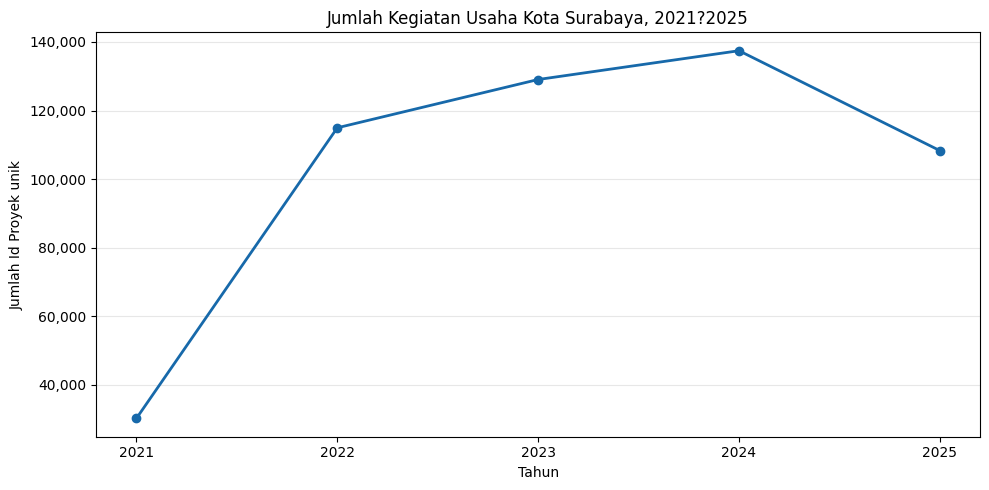

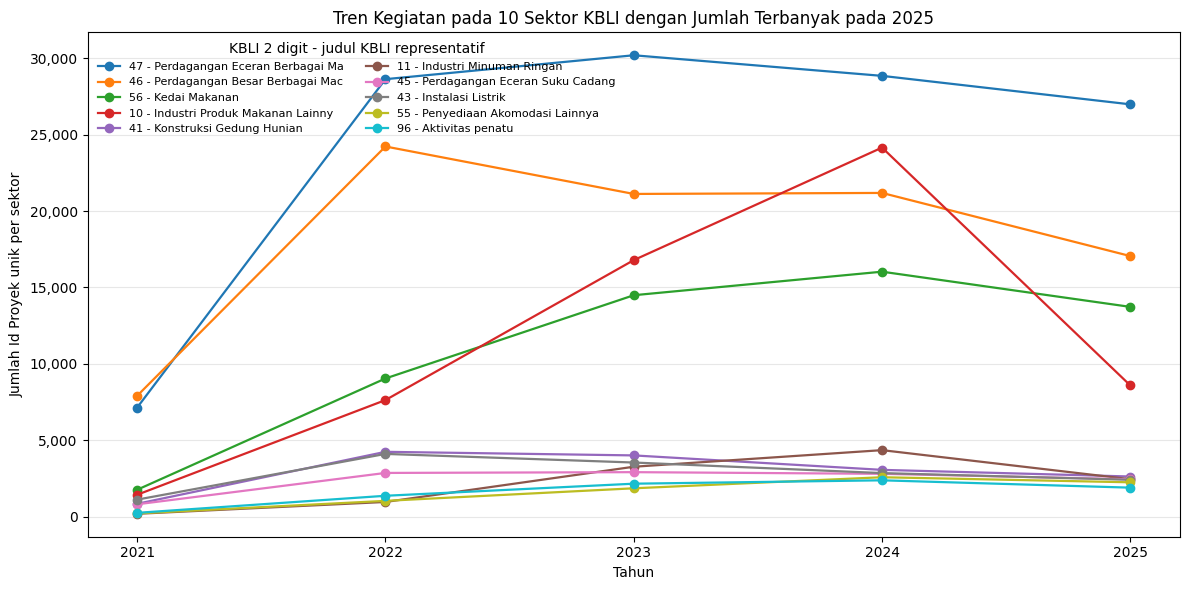

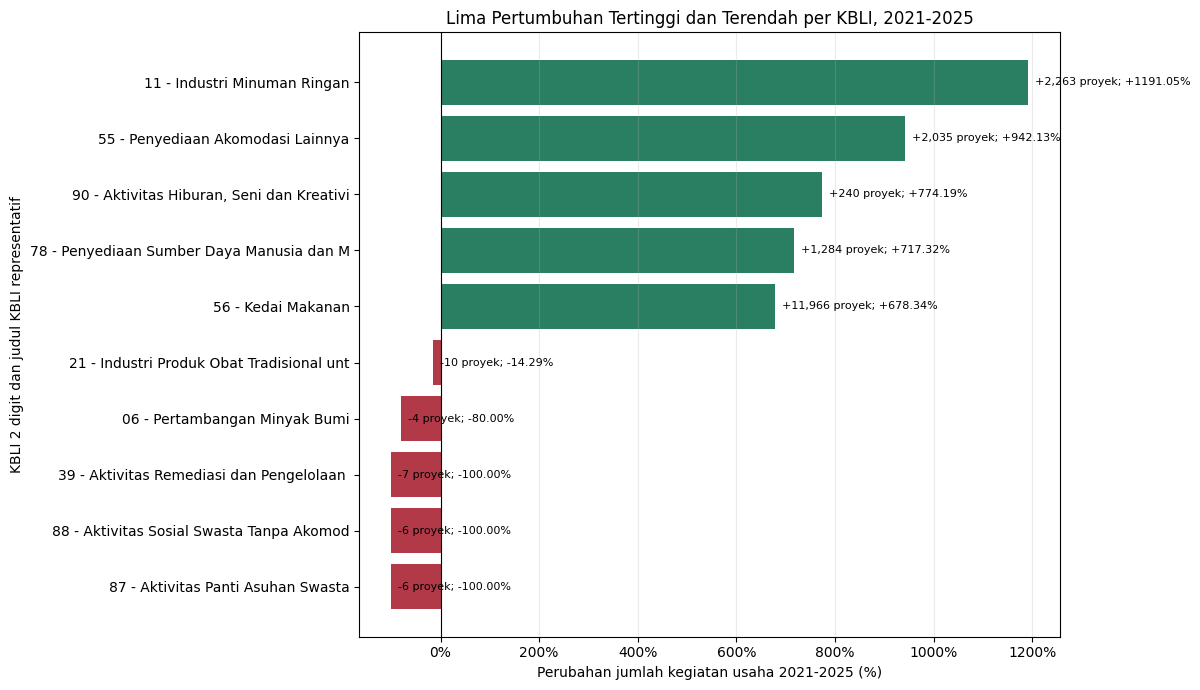

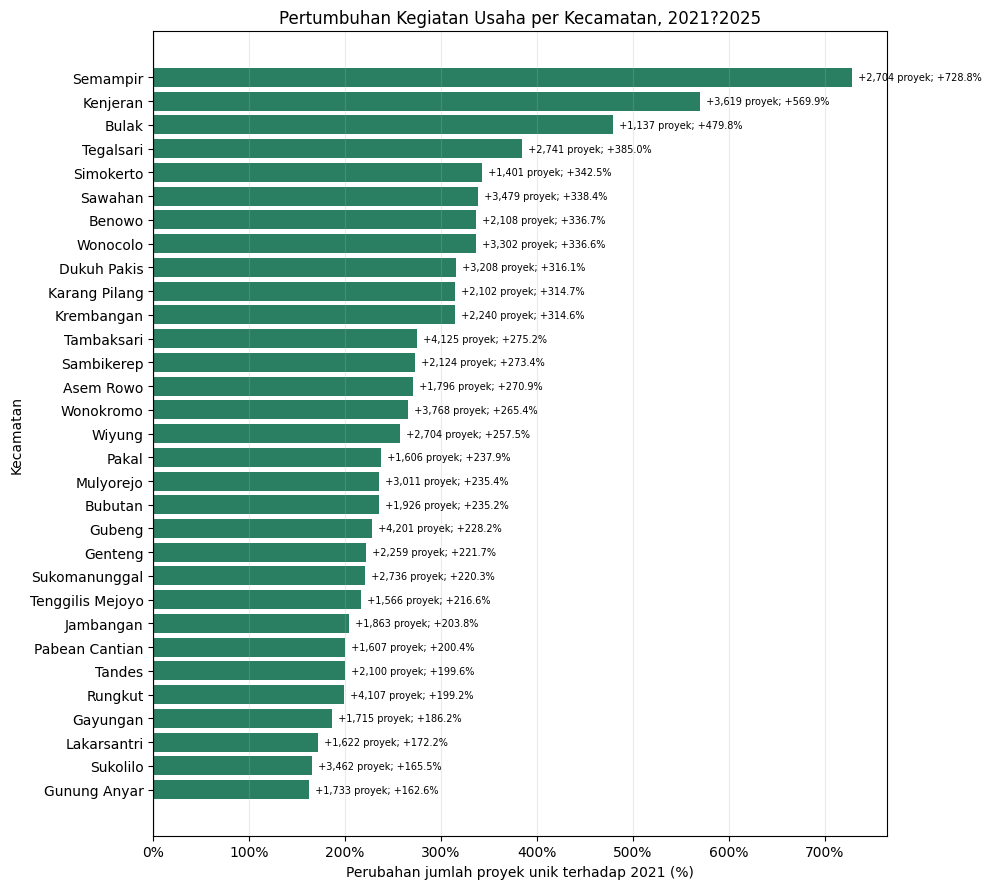

In [28]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pertumbuhan_tahunan["Tahun"], pertumbuhan_tahunan["jumlah_kegiatan_usaha"],
        marker="o", linewidth=2, color="#1769aa")
ax.set_title("Jumlah Kegiatan Usaha Kota Surabaya, 2021?2025")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah Id Proyek unik")
ax.set_xticks(tahun_analisis)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# Tampilkan tren jumlah untuk 10 sektor dengan kegiatan terbanyak pada 2025 agar grafik tetap terbaca.
sektor_utama = jumlah_sektor[2025].nlargest(min(10, len(jumlah_sektor))).index
fig, ax = plt.subplots(figsize=(12, 6))
for kode in sektor_utama:
    ax.plot(tahun_analisis, jumlah_sektor.loc[kode, tahun_analisis], marker="o", linewidth=1.6,
            label=f"{kode} - {label_kbli.get(kode, '')[:30]}")
ax.set_title("Tren Kegiatan pada 10 Sektor KBLI dengan Jumlah Terbanyak pada 2025")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah Id Proyek unik per sektor")
ax.set_xticks(tahun_analisis)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.3)
ax.legend(title="KBLI 2 digit - judul KBLI representatif", ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

sektor_berubah = pertumbuhan_sektor_pivot.reset_index().merge(
    judul_kbli_sektor, on="KBLI_2digit", how="left", validate="one_to_one"
).dropna(subset=["pertumbuhan_2021_2025_persen"])
sektor_tumbuh_tertinggi = sektor_berubah.nlargest(5, "pertumbuhan_2021_2025_persen")
sektor_tumbuh_terendah = sektor_berubah.nsmallest(5, "pertumbuhan_2021_2025_persen")
sektor_pertumbuhan_plot = pd.concat([
    sektor_tumbuh_tertinggi.assign(Kelompok="Pertumbuhan tertinggi"),
    sektor_tumbuh_terendah.assign(Kelompok="Pertumbuhan terendah"),
]).drop_duplicates("KBLI_2digit").sort_values("pertumbuhan_2021_2025_persen")
sektor_pertumbuhan_plot["Label"] = sektor_pertumbuhan_plot.apply(
    lambda row: f"{row['KBLI_2digit']} - {row['Judul_KBLI_5_digit_terbanyak'][:36]}", axis=1
)
fig, ax = plt.subplots(figsize=(12, 7))
warna = ["#2a7f62" if nilai >= 0 else "#b23a48" for nilai in sektor_pertumbuhan_plot["pertumbuhan_2021_2025_persen"]]
bars = ax.barh(sektor_pertumbuhan_plot["Label"], sektor_pertumbuhan_plot["pertumbuhan_2021_2025_persen"], color=warna)
for bar, row in zip(bars, sektor_pertumbuhan_plot.itertuples()):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  {row.perubahan_2021_2025_jumlah:+,.0f} proyek; {row.pertumbuhan_2021_2025_persen:+.2f}%",
            va="center", fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Lima Pertumbuhan Tertinggi dan Terendah per KBLI, 2021-2025")
ax.set_xlabel("Perubahan jumlah kegiatan usaha 2021-2025 (%)")
ax.set_ylabel("KBLI 2 digit dan judul KBLI representatif")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Perbandingan kumulatif antar seluruh kecamatan dari baseline 2021 ke 2025.
kecamatan_chart = wilayah_valid["pertumbuhan_2021_2025_persen"].sort_values()
fig, ax = plt.subplots(figsize=(10, 9))
warna = ["#b23a48" if nilai < 0 else "#2a7f62" for nilai in kecamatan_chart.values]
bar_kecamatan = ax.barh(kecamatan_chart.index, kecamatan_chart.values, color=warna)
perubahan_absolut_kecamatan = wilayah_valid.loc[kecamatan_chart.index, "perubahan_2021_2025_jumlah"]
for bar, nilai, absolut in zip(bar_kecamatan, kecamatan_chart.values, perubahan_absolut_kecamatan):
    ax.text(nilai, bar.get_y() + bar.get_height() / 2,
            f"  {absolut:+,.0f} proyek; {nilai:+.1f}%", va="center", fontsize=7)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Pertumbuhan Kegiatan Usaha per Kecamatan, 2021?2025")
ax.set_xlabel("Perubahan jumlah proyek unik terhadap 2021 (%)")
ax.set_ylabel("Kecamatan")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


### Interpretasi pertumbuhan kegiatan usaha

Grafik garis menunjukkan perubahan jumlah proyek unik kota per tahun; tabel YoY mengukur perubahan dari tahun sebelumnya dan tidak mengisi tahun 2021 dengan 0%. Grafik sektoral dan kecamatan membandingkan pertumbuhan persentase sambil menampilkan perubahan absolut serta jumlah aktual, sehingga laju tinggi dari basis kecil dapat dibedakan dari kenaikan berskala besar. Nilai pertumbuhan menggambarkan perubahan pencatatan proyek dan tidak dengan sendirinya menjelaskan penyebabnya.

### 8.5 Validasi dan penyimpanan hasil


In [29]:
assert pertumbuhan_tahunan["Tahun"].tolist() == tahun_analisis
jumlah_tahunan_validasi = data_pertumbuhan.groupby("Tahun")["Id Proyek"].nunique().reindex(tahun_analisis)
assert pertumbuhan_tahunan["jumlah_kegiatan_usaha"].tolist() == jumlah_tahunan_validasi.astype(int).tolist()
assert pd.isna(pertumbuhan_tahunan.loc[pertumbuhan_tahunan["Tahun"].eq(2021), "pertumbuhan_yoy_persen"]).all()
assert len(pertumbuhan_sektor) == len(sektor_teramati) * len(tahun_analisis)
assert len(pertumbuhan_wilayah) == len(kecamatan_teramati) * len(tahun_analisis)
assert pd.isna(pertumbuhan_sektor.loc[pertumbuhan_sektor["Tahun"].eq(2021), "pertumbuhan_yoy_persen"]).all()
assert pd.isna(pertumbuhan_wilayah.loc[pertumbuhan_wilayah["Tahun"].eq(2021), "pertumbuhan_yoy_persen"]).all()
for tabel in [pertumbuhan_tahunan, pertumbuhan_sektor, pertumbuhan_wilayah]:
    assert not np.isinf(tabel["pertumbuhan_yoy_persen"].dropna()).any()

def frame_pertumbuhan(frame, keys, numeric_columns):
    result = frame[keys + numeric_columns].copy()
    result.columns.name = None
    if "KBLI_2digit" in result.columns:
        result["KBLI_2digit"] = result["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
    for column in numeric_columns:
        result[column] = pd.to_numeric(result[column], errors="coerce")
    return result.sort_values(keys).reset_index(drop=True)

kolom_yoy = ["jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"]
pd.testing.assert_frame_equal(
    frame_pertumbuhan(pertumbuhan_sektor_tersimpan, ["KBLI_2digit", "Tahun"], kolom_yoy),
    frame_pertumbuhan(pertumbuhan_sektor, ["KBLI_2digit", "Tahun"], kolom_yoy),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
)
pd.testing.assert_frame_equal(
    frame_pertumbuhan(pertumbuhan_kecamatan_tersimpan, ["kecamatan_usaha", "Tahun"], kolom_yoy),
    frame_pertumbuhan(pertumbuhan_wilayah, ["kecamatan_usaha", "Tahun"], kolom_yoy),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
)
kolom_perbandingan_tabel = ["2021", "2022", "2023", "2024", "2025", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"]
perbandingan_pertumbuhan_validasi = perbandingan_pertumbuhan.rename(
    columns={year: str(year) for year in tahun_analisis}
)
pd.testing.assert_frame_equal(
    frame_pertumbuhan(perbandingan_pertumbuhan_tersimpan, ["jenis_entitas", "nama_entitas"], kolom_perbandingan_tabel),
    frame_pertumbuhan(perbandingan_pertumbuhan_validasi, ["jenis_entitas", "nama_entitas"], kolom_perbandingan_tabel),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
)

output_dir.mkdir(parents=True, exist_ok=True)
pertumbuhan_sektor.to_csv(output_dir / "pertumbuhan_kegiatan_usaha_sektor_yoy.csv", index=False)
pertumbuhan_wilayah.to_csv(output_dir / "pertumbuhan_kegiatan_usaha_wilayah_yoy.csv", index=False)
perbandingan_pertumbuhan.to_csv(output_dir / "perbandingan_pertumbuhan_sektor_wilayah.csv", index=False)

print("Validasi lulus: baseline YoY 2021 NaN; semua panel sektor/kecamatan lengkap; tanpa pembagian dengan nol.")
print("Baris hasil kota:", len(pertumbuhan_tahunan))
print("Baris hasil sektor:", len(pertumbuhan_sektor), "| jumlah sektor:", len(sektor_teramati))
print("Baris hasil kecamatan:", len(pertumbuhan_wilayah), "| jumlah kecamatan:", len(kecamatan_teramati))
print("Validasi lulus; cache pertumbuhan awal konsisten dengan perhitungan dataset cleaning dan telah diperbarui.")


Validasi lulus: baseline YoY 2021 NaN; semua panel sektor/kecamatan lengkap; tanpa pembagian dengan nol.
Baris hasil kota: 5
Baris hasil sektor: 415 | jumlah sektor: 83
Baris hasil kecamatan: 155 | jumlah kecamatan: 31
Validasi lulus; cache pertumbuhan awal konsisten dengan perhitungan dataset cleaning dan telah diperbarui.


## 9. Pemetaan Choropleth Pertumbuhan Kegiatan Usaha per Kecamatan Kota Surabaya Periode 2021-2025

Peta ini menggunakan hasil pertumbuhan agregat per kecamatan dari dataset cleaning yang sama dengan analisis tabel, serta GeoJSON kecamatan yang sama dengan peta LQ. Persentase YoY divisualisasikan untuk tahun 2022-2025; 2021 tidak memiliki pembanding sehingga ditampilkan sebagai data tidak tersedia, bukan 0%. Filter tahun, legenda, dan nama kecamatan tersedia pada peta ini; filter KBLI tersedia pada peta LQ karena peta pertumbuhan menampilkan total lintas sektor.

In [1]:
from pathlib import Path
import json
import re
import unicodedata

import folium
import numpy as np
import pandas as pd
from branca.element import MacroElement, Template
from IPython.display import display

project_dir = Path.cwd().parent if Path.cwd().name.casefold() == "notebooks" else Path.cwd()
output_dir = project_dir / "output"
geojson_candidates = [
    project_dir / "data_processed" / "geojson_kecamatan_surabaya_merged.geojson",
    project_dir / "data_raw" / "geojson_kecamatan_surabaya_merged.geojson",
]
geojson_path = next((path for path in geojson_candidates if path.is_file()), None)
if "pertumbuhan_wilayah" not in globals() or "pertumbuhan_wilayah_pivot" not in globals():
    raise RuntimeError("Jalankan analisis pertumbuhan kecamatan sebelum membuat peta.")
if geojson_path is None:
    raise FileNotFoundError(
        "GeoJSON kecamatan tidak ditemukan. Lokasi yang diperiksa: "
        + ", ".join(str(path) for path in geojson_candidates)
    )

summary_growth = pertumbuhan_wilayah_pivot.reset_index().rename(
    columns={year: str(year) for year in tahun_analisis}
)
yoy_growth = pertumbuhan_wilayah.copy()
with geojson_path.open(encoding="utf-8") as file:
    growth_geojson = json.load(file)
features = growth_geojson.get("features", [])
if not features:
    raise ValueError(f"GeoJSON tidak berisi features: {geojson_path}")
geojson_property_keys = sorted({
    key for feature in features for key in feature.get("properties", {}).keys()
})
print("Kolom ringkasan wilayah:", summary_growth.columns.tolist())
print("Kolom data YoY wilayah:", yoy_growth.columns.tolist())
print("Properties GeoJSON:", geojson_property_keys)
print("Jumlah feature GeoJSON:", len(features))
print("GeoJSON digunakan:", geojson_path)

required_summary_columns = {"kecamatan_usaha", "2021", "2022", "2023", "2024", "2025"}
required_yoy_columns = {
    "kecamatan_usaha", "Tahun", "jumlah_kegiatan_usaha",
    "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"
}
missing_summary = required_summary_columns.difference(summary_growth.columns)
missing_yoy = required_yoy_columns.difference(yoy_growth.columns)
if missing_summary:
    raise KeyError(f"Kolom ringkasan wilayah tidak ditemukan: {sorted(missing_summary)}")
if missing_yoy:
    raise KeyError(f"Kolom YoY wilayah tidak ditemukan: {sorted(missing_yoy)}")
if "K" not in geojson_property_keys:
    raise KeyError("Property nama kecamatan 'K' tidak ditemukan pada GeoJSON.")
if len(features) != 31:
    raise ValueError(f"Diharapkan 31 kecamatan, tetapi GeoJSON berisi {len(features)} feature.")

selected_years = [2022, 2023, 2024, 2025]
yoy_growth["Tahun"] = pd.to_numeric(yoy_growth["Tahun"], errors="raise").astype(int)
for column in ["jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"]:
    yoy_growth[column] = pd.to_numeric(yoy_growth[column], errors="coerce")

def normalize_district_name(name):
    ascii_name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "", ascii_name.casefold())

geo_names_by_key = {}
for feature in features:
    name = feature.get("properties", {}).get("K")
    if not name:
        raise ValueError("Terdapat feature GeoJSON tanpa nama kecamatan pada property 'K'.")
    key = normalize_district_name(name)
    if key in geo_names_by_key:
        raise ValueError(f"Nama kecamatan GeoJSON duplikat setelah normalisasi: {name}")
    geo_names_by_key[key] = name

summary_growth["nama_norm_join"] = summary_growth["kecamatan_usaha"].map(normalize_district_name)
yoy_growth["nama_norm_join"] = yoy_growth["kecamatan_usaha"].map(normalize_district_name)
geo_name_keys = set(geo_names_by_key)
unknown_summary = sorted(summary_growth.loc[~summary_growth["nama_norm_join"].isin(geo_name_keys), "kecamatan_usaha"].dropna().unique().tolist())
unknown_yoy = sorted(yoy_growth.loc[~yoy_growth["nama_norm_join"].isin(geo_name_keys), "kecamatan_usaha"].dropna().unique().tolist())
if unknown_summary or unknown_yoy:
    raise ValueError(f"Nama kecamatan tidak cocok dengan GeoJSON. Ringkasan: {unknown_summary}; YoY: {unknown_yoy}")
if summary_growth["nama_norm_join"].nunique() != 31 or yoy_growth["nama_norm_join"].nunique() != 31:
    raise ValueError("Tabel ringkasan dan YoY harus mencakup tepat 31 kecamatan.")
if summary_growth["nama_norm_join"].duplicated().any():
    raise ValueError("Ditemukan kecamatan duplikat pada ringkasan.")
if yoy_growth.duplicated(["nama_norm_join", "Tahun"]).any():
    raise ValueError("Ditemukan kombinasi kecamatan-tahun duplikat pada tabel YoY.")
if set(yoy_growth["Tahun"].unique()) != {2021, *selected_years}:
    raise ValueError(f"Tahun dalam tabel YoY tidak sesuai. Ditemukan: {sorted(yoy_growth['Tahun'].unique())}")

selected_growth = yoy_growth[yoy_growth["Tahun"].isin(selected_years)].copy()
if selected_growth.groupby("Tahun")["nama_norm_join"].nunique().reindex(selected_years).ne(31).any():
    raise ValueError("Setiap tahun 2022?2025 harus memiliki tepat 31 kecamatan.")

summary_lookup = summary_growth.set_index("nama_norm_join").to_dict(orient="index")
yoy_lookup = {
    (row.nama_norm_join, int(row.Tahun)): {
        "jumlah_kegiatan_usaha": float(row.jumlah_kegiatan_usaha) if pd.notna(row.jumlah_kegiatan_usaha) else None,
        "pertumbuhan_yoy_jumlah": float(row.pertumbuhan_yoy_jumlah) if pd.notna(row.pertumbuhan_yoy_jumlah) else None,
        "pertumbuhan_yoy_persen": float(row.pertumbuhan_yoy_persen) if pd.notna(row.pertumbuhan_yoy_persen) else None,
    }
    for row in selected_growth.itertuples(index=False)
}
for feature in features:
    key = normalize_district_name(feature["properties"]["K"])
    feature["properties"]["growth_by_year"] = {
        str(year): yoy_lookup.get((key, year)) for year in selected_years
    }

matched_districts = sum(normalize_district_name(feature["properties"]["K"]) in summary_lookup for feature in features)
if matched_districts != 31:
    raise ValueError(f"Hanya {matched_districts}/31 kecamatan GeoJSON yang cocok dengan data pertumbuhan.")
available_rates = selected_growth["pertumbuhan_yoy_persen"].dropna()
if available_rates.empty:
    raise ValueError("Tidak ada nilai persentase pertumbuhan YoY yang dapat dipetakan.")
max_abs_growth_by_year = {}
for year in selected_years:
    year_rates = selected_growth.loc[selected_growth["Tahun"].eq(year), "pertumbuhan_yoy_persen"].dropna()
    year_limit = float(year_rates.abs().max()) if not year_rates.empty else 1.0
    if not np.isfinite(year_limit):
        raise ValueError(f"Nilai batas skala pertumbuhan {year} tidak valid.")
    max_abs_growth_by_year[str(year)] = year_limit if year_limit > 0 else 1.0

missing_rate_count = int(selected_growth["pertumbuhan_yoy_persen"].isna().sum())
print(f"Kecamatan terhubung: {matched_districts}/31")
print(f"Nilai pertumbuhan tersedia 2022?2025: {len(available_rates)}/{len(selected_growth)}; tidak tersedia: {missing_rate_count}")
print("Skala warna divergen simetris per tahun: " + ", ".join(f"{year}: +/-{limit:.2f}%" for year, limit in max_abs_growth_by_year.items()))

# Palette divergen: merah untuk kontraksi, netral dekat nol, hijau untuk pertumbuhan positif.
negative_color = "#b2182b"
zero_color = "#f7f7f7"
positive_color = "#1a9850"
unavailable_color = "#bdbdbd"
def interpolate_hex(start, end, amount):
    start_rgb = tuple(int(start[index:index + 2], 16) for index in (1, 3, 5))
    end_rgb = tuple(int(end[index:index + 2], 16) for index in (1, 3, 5))
    rgb = tuple(round(a + (b - a) * amount) for a, b in zip(start_rgb, end_rgb))
    return "#" + "".join(f"{channel:02x}" for channel in rgb)

def growth_color(value, year):
    if value is None or not np.isfinite(value):
        return unavailable_color
    position = min(1.0, max(-1.0, value / max_abs_growth_by_year[str(year)]))
    if position < 0:
        return interpolate_hex(zero_color, negative_color, -position)
    return interpolate_hex(zero_color, positive_color, position)

def growth_style(feature, year):
    values = feature["properties"].get("growth_by_year", {})
    record = values.get(str(year))
    value = record.get("pertumbuhan_yoy_persen") if record else None
    return {"fillColor": growth_color(value, year), "color": "#333333", "weight": 1.2, "fillOpacity": 0.82}

initial_year = 2025
growth_map = folium.Map(
    location=[-7.2575, 112.7521],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True,
)
growth_layer = folium.GeoJson(
    data=growth_geojson,
    name="Pertumbuhan YoY per kecamatan",
    style_function=lambda feature: growth_style(feature, initial_year),
    highlight_function=lambda feature: {"weight": 3, "color": "#222222", "fillOpacity": 0.92},
    smooth_factor=0.5,
).add_to(growth_map)

controls = MacroElement()
controls.years = selected_years
controls.layer_name = growth_layer.get_name()
controls.max_abs_by_year = max_abs_growth_by_year
controls._template = Template(r"""
{% macro script(this, kwargs) %}
(function() {
    const map = {{ this._parent.get_name() }};
    const geojsonLayer = {{ this.layer_name }};
    const years = {{ this.years|tojson }};
    const maxAbsByYear = {{ this.max_abs_by_year|tojson }};
    const negative = [178, 24, 43];
    const neutral = [247, 247, 247];
    const positive = [26, 152, 80];
    const unavailable = "#bdbdbd";
    const controlId = "growth-filter-" + map._leaflet_id;

    function rgbHex(rgb) {
        return "#" + rgb.map(function(value) { return Math.round(value).toString(16).padStart(2, "0"); }).join("");
    }
    function blend(start, end, amount) {
        return start.map(function(value, index) { return value + (end[index] - value) * amount; });
    }
    function valueFor(feature, year) {
        const yearly = (feature.properties.growth_by_year || {})[String(year)];
        if (!yearly) return null;
        const rawValue = yearly.pertumbuhan_yoy_persen;
        if (rawValue === null || rawValue === undefined || (typeof rawValue === "string" && rawValue.trim() === "")) return null;
        const value = Number(rawValue);
        return Number.isFinite(value) ? value : null;
    }
    function maxAbsFor(year) {
        const limit = Number(maxAbsByYear[String(year)]);
        return Number.isFinite(limit) && limit > 0 ? limit : 1;
    }
    function colorFor(value, year) {
        if (value === null || !Number.isFinite(value)) return unavailable;
        const position = Math.max(-1, Math.min(1, value / maxAbsFor(year)));
        return rgbHex(position < 0 ? blend(neutral, negative, -position) : blend(neutral, positive, position));
    }
    let activeYear = String(years[years.length - 1]);
    function styleForFeature(feature, year) {
        return {fillColor: colorFor(valueFor(feature, year), year), color: "#333333", weight: 1.2, fillOpacity: 0.82};
    }
    geojsonLayer.options.style = function(feature) { return styleForFeature(feature, activeYear); };
    function formatNumber(value) {
        return value === null || value === undefined ? "Data tidak tersedia" : new Intl.NumberFormat("id-ID", {maximumFractionDigits: 0}).format(value);
    }
    function tooltip(feature, year, record) {
        const district = String(feature.properties.K || "Tidak diketahui").replace(/[&<>"']/g, function(char) {
            return {"&":"&amp;", "<":"&lt;", ">":"&gt;", "\"":"&quot;", "'":"&#39;"}[char];
        });
        const value = record && record.pertumbuhan_yoy_persen !== null && record.pertumbuhan_yoy_persen !== undefined
            ? Number(record.pertumbuhan_yoy_persen).toFixed(2) + "%" : "Data tidak tersedia";
        return "<b>Kecamatan:</b> " + district + "<br><b>Tahun:</b> " + year +
            "<br><b>Jumlah kegiatan:</b> " + formatNumber(record && record.jumlah_kegiatan_usaha) +
            "<br><b>Perubahan jumlah:</b> " + formatNumber(record && record.pertumbuhan_yoy_jumlah) +
            "<br><b>Pertumbuhan YoY:</b> " + value;
    }
    function applyYear() {
        const year = document.getElementById(controlId + "-year").value;
        activeYear = year;
        let available = 0;
        let missing = 0;
        const observedValues = [];
        geojsonLayer.eachLayer(function(layer) {
            const feature = layer.feature;
            const record = ((feature.properties.growth_by_year || {})[String(year)]) || null;
            const value = valueFor(feature, year);
            if (value === null) missing += 1; else { available += 1; observedValues.push(value); }
            layer.setStyle(styleForFeature(feature, year));
            const content = tooltip(feature, year, record);
            if (layer.getTooltip()) layer.setTooltipContent(content);
            else layer.bindTooltip(content, {sticky: true, direction: "top", opacity: 0.95});
        });
        document.getElementById(controlId + "-coverage").textContent =
            available + " kecamatan tersedia; " + missing + " tidak tersedia (dari 31)";
        const range = document.getElementById(controlId + "-legend-range");
        const maxAbs = maxAbsFor(year);
        if (range) range.innerHTML = "<span>-" + maxAbs.toFixed(1) + "%</span><span>0%</span><span>+" + maxAbs.toFixed(1) + "%</span>";
        console.info("Pertumbuhan YoY", {year: Number(year), available: available, missing: missing, min: observedValues.length ? Math.min(...observedValues) : null, max: observedValues.length ? Math.max(...observedValues) : null});
    }
    const filter = L.control({position: "topright"});
    filter.onAdd = function() {
        const container = L.DomUtil.create("div", "leaflet-bar growth-filter-control");
        container.style.cssText = "background:#fff;padding:10px 12px;min-width:205px;font:13px Arial,sans-serif;line-height:1.6";
        container.innerHTML = "<strong>Pertumbuhan YoY Kecamatan</strong><br><label for='" + controlId + "-year'>Tahun: </label>" +
            "<select id='" + controlId + "-year'></select><div id='" + controlId + "-coverage' style='margin-top:5px;font-size:11px'></div>";
        L.DomEvent.disableClickPropagation(container);
        L.DomEvent.disableScrollPropagation(container);
        return container;
    };
    filter.addTo(map);
    const select = document.getElementById(controlId + "-year");
    years.forEach(function(year) {
        const option = document.createElement("option"); option.value = year; option.textContent = year; select.appendChild(option);
    });
    select.value = "2025";
    select.addEventListener("change", applyYear);

    const legend = L.control({position: "bottomright"});
    legend.onAdd = function() {
        const container = L.DomUtil.create("div", "leaflet-bar growth-legend");
        container.style.cssText = "background:#fff;padding:9px 11px;width:210px;font:12px Arial,sans-serif;line-height:1.6";
        container.innerHTML = "<strong>Pertumbuhan YoY (%)</strong><div style='height:12px;margin:6px 0;background:linear-gradient(to right,#b2182b,#f7f7f7,#1a9850);border:1px solid #999'></div>" +
            "<div id='" + controlId + "-legend-range' style='display:flex;justify-content:space-between'></div>" +
            "<div style='margin-top:5px'><span style='color:" + unavailable + "'>-</span> Data tidak tersedia</div>";
        return container;
    };
    legend.addTo(map);
    applyYear();
})();
{% endmacro %}
""")
controls.add_to(growth_map)

map_path = output_dir / "peta_choropleth_pertumbuhan_kecamatan.html"
map_path.parent.mkdir(parents=True, exist_ok=True)
growth_map.save(str(map_path))
print(f"Peta HTML interaktif disimpan: {map_path.resolve()}")
print(f"Tahun filter: {selected_years}; kecamatan terhubung: {matched_districts}/31")
print("Periode terpilih awal: 2021")
display(growth_map)


Kolom ringkasan wilayah: ['kecamatan_usaha', '2021', '2022', '2023', '2024', '2025', 'perubahan_2021_2025_jumlah', 'pertumbuhan_2021_2025_persen', 'tren']
Kolom data YoY wilayah: ['kecamatan_usaha', 'Tahun', 'jumlah_kegiatan_usaha', 'pertumbuhan_yoy_jumlah', 'pertumbuhan_yoy_persen']
Properties GeoJSON: ['K', 'KODE', 'Keterangan', 'LUAS_HA', 'LUAS_KM']
Jumlah feature GeoJSON: 31
GeoJSON digunakan: D:\DPMPTSP\Project_Akhir\data_raw\geojson_kecamatan_surabaya_merged.geojson
Kecamatan terhubung: 31/31
Nilai pertumbuhan tersedia 2022?2025: 124/124; tidak tersedia: 0
Skala warna divergen simetris per tahun: 2022: +/-532.49%, 2023: +/-40.66%, 2024: +/-84.07%, 2025: +/-45.25%


Peta HTML interaktif disimpan: D:\DPMPTSP\Project_Akhir\output\peta_choropleth_pertumbuhan_kecamatan.html
Tahun filter: [2022, 2023, 2024, 2025]; kecamatan terhubung: 31/31
Periode terpilih awal: 2021


**Interpretasi berdasarkan data aktual:** pada 2022, kenaikan YoY terbesar tercatat di Bulak (+532,49%), sedangkan pada 2025 penurunan terbesar terjadi di Semampir (-45,25%). Semua 31 kecamatan memiliki nilai pertumbuhan untuk setiap tahun 2022-2025 pada tabel saat ini. Gradasi merah menunjukkan penurunan, warna netral mendekati 0%, dan hijau menunjukkan pertumbuhan; skala simetris agar perbandingan kedua arah mudah dibaca. Abu-abu digunakan bila nilai pertumbuhan tidak tersedia.

## 10. Analisis Gabungan Location Quotient (LQ) dan Pertumbuhan Kegiatan Usaha

Analisis menggabungkan hasil LQ dan pertumbuhan yang telah dihitung pada bagian sebelumnya dan tersedia di memori notebook, tanpa menghitung ulang LQ. Unit analisis adalah KBLI 2 digit. Rata-rata LQ dihitung dari rata-rata LQ tahunan per sektor selama 2021-2025; rata-rata periode ditampilkan sebagai nilai parsial bila ada tahun tanpa observasi, tetapi sektor tersebut masuk kategori **Data tidak memadai** agar klasifikasi tidak dibuat dari periode yang tidak lengkap. CAGR dihitung dari jumlah kegiatan 2021 dan 2025 dengan rumus `((jumlah_2025 / jumlah_2021) ** (1/4) - 1) * 100%`; jika data endpoint tidak tersedia atau jumlah awal nol, CAGR tidak dihitung. Kategori tumbuh jika CAGR > 0%, dan tidak tumbuh/menurun jika CAGR <= 0%.

Kolom hasil LQ: ['kecamatan_usaha', 'KBLI_2digit', 'Tahun', 'jumlah_kegiatan_usaha', 'total_kegiatan_kecamatan_tahun', 'total_kegiatan_sektor_kota_tahun', 'total_kegiatan_kota_tahun', 'proporsi_kecamatan', 'proporsi_kota', 'LQ', 'Kategori_LQ', 'Judul_KBLI_5_digit_terbanyak']
Kolom ringkasan pertumbuhan sektor: ['KBLI_2digit', '2021', '2022', '2023', '2024', '2025', 'perubahan_2021_2025_jumlah', 'pertumbuhan_2021_2025_persen', 'tren']
Jumlah baris hasil LQ: 10280
Jumlah baris ringkasan pertumbuhan sektor: 83
Ringkasan kategori gabungan:


,kategori_gabungan,jumlah_sektor
0,Sektor Basis dan Tumbuh,58
1,Sektor Basis tetapi Tidak Tumbuh,4
2,Sektor Non-Basis tetapi Tumbuh,18
3,Sektor Non-Basis dan Tidak Tumbuh,0
4,Data tidak memadai,3


Klasifikasi gabungan LQ dan CAGR seluruh KBLI beserta judul KBLI representatif:


,KBLI_2digit,Judul_KBLI_5_digit_terbanyak,jumlah_kegiatan_2021,jumlah_kegiatan_2025,rata_rata_lq_2021_2025,cagr_2021_2025_persen,kategori_gabungan,status_data
0,01,Pembibitan dan Budidaya Burung Walet,529,775,0.9797,10.02,Sektor Non-Basis tetapi Tumbuh,Lengkap
1,02,Usaha Kehutanan Lainnya,26,53,1.5789,19.49,Sektor Basis dan Tumbuh,Lengkap
2,03,Pembesaran Ikan Air Tawar Di Kolam,90,293,1.1024,34.32,Sektor Basis dan Tumbuh,Lengkap
3,05,Pertambangan Batu Bara,10,9,3.6626,-2.60,Sektor Basis tetapi Tidak Tumbuh,Lengkap
4,06,Pertambangan Minyak Bumi,5,1,11.5762,-33.13,Sektor Basis tetapi Tidak Tumbuh,Lengkap
...,...,...,...,...,...,...,...,...
78,91,Perpustakaan dan Arsip Swasta,11,12,3.8198,2.20,Sektor Basis dan Tumbuh,Lengkap
79,93,Pengelolaan Fasilitas Olah raga Lainnya,90,411,1.1436,46.18,Sektor Basis dan Tumbuh,Lengkap
80,95,Reparasi Komputer dan Peralatan Sejenisnya,162,692,0.9866,43.76,Sektor Non-Basis tetapi Tumbuh,Lengkap
81,96,Aktivitas penatu,252,1901,0.9914,65.73,Sektor Non-Basis tetapi Tumbuh,Lengkap


Sektor dengan indikator tidak memadai:


,KBLI_2digit,rata_rata_lq_2021_2025,jumlah_tahun_lq_tersedia,jumlah_kegiatan_2021,jumlah_kegiatan_2025,cagr_2021_2025_persen,status_data
36,39,21.1273,2,7,0,-100.0,LQ tidak tersedia untuk seluruh tahun 2021?2025
75,87,11.7257,2,6,0,-100.0,LQ tidak tersedia untuk seluruh tahun 2021?2025
76,88,8.5400,3,6,0,-100.0,LQ tidak tersedia untuk seluruh tahun 2021?2025


... (4 outputs left out)

Sektor non-basis tetapi tumbuh:


,KBLI_2digit,rata_rata_lq_2021_2025,jumlah_kegiatan_2021,jumlah_kegiatan_2025,cagr_2021_2025_persen
48,55,0.9490,216,2251,79.67
49,56,0.9821,1764,13730,67.03
81,96,0.9914,252,1901,65.73
72,82,0.9843,269,1755,59.82
73,85,0.9993,222,1014,46.19
80,95,0.9866,162,692,43.76
65,74,0.9768,314,1018,34.19
37,41,0.9618,845,2630,32.82
62,71,0.9943,198,616,32.81
40,45,0.9868,812,2450,31.80


Sektor paling menonjol pada setiap kategori (ekstrem CAGR dalam kategori; kategori tanpa data valid tidak dipaksakan):


,kategori_gabungan,KBLI_2digit,Judul_KBLI_5_digit_terbanyak,jumlah_kegiatan_2021,jumlah_kegiatan_2025,rata_rata_lq_2021_2025,cagr_2021_2025_persen
9,Sektor Basis dan Tumbuh,11,Industri Minuman Ringan,190,2453,1.0124,89.56
4,Sektor Basis tetapi Tidak Tumbuh,06,Pertambangan Minyak Bumi,5,1,11.5762,-33.13
48,Sektor Non-Basis tetapi Tumbuh,55,Penyediaan Akomodasi Lainnya,216,2251,0.9490,79.67
36,Data tidak memadai,39,Aktivitas Remediasi dan Pengelolaan Limbah dan...,7,0,21.1273,-100.00
76,Data tidak memadai,88,Aktivitas Sosial Swasta Tanpa Akomodasi Lainny...,6,0,8.5400,-100.00


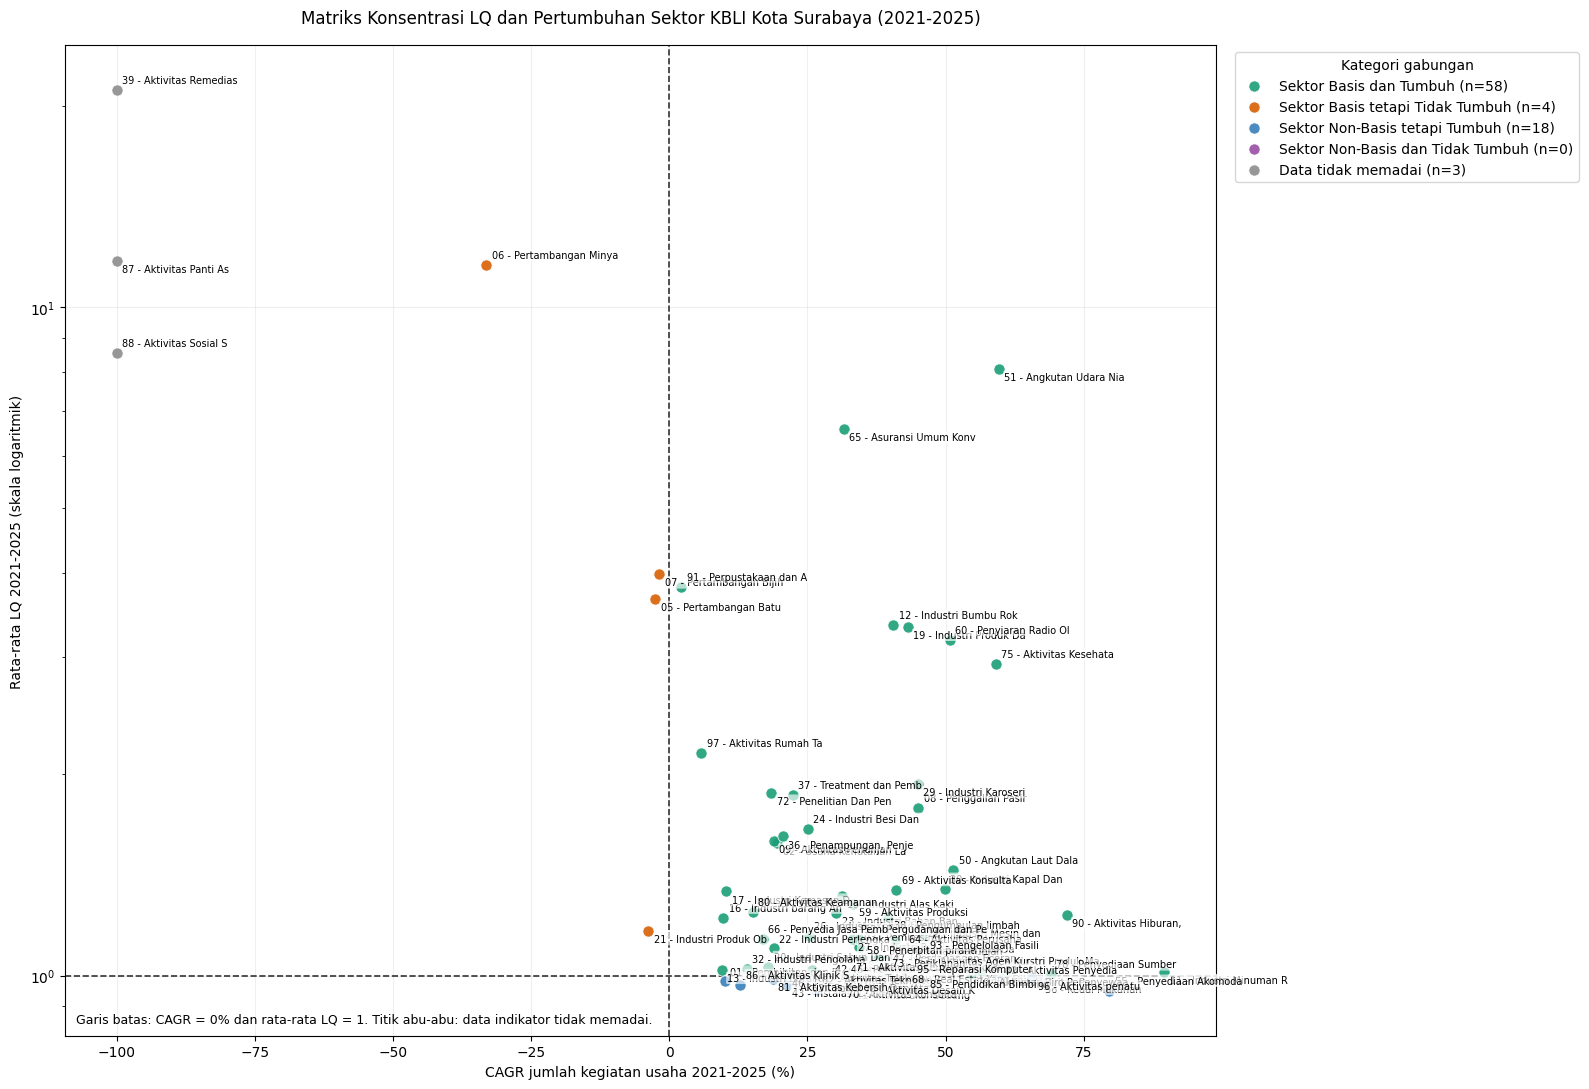

Interpretasi aktual:
Sektor basis dan tumbuh: 58; sektor basis dengan CAGR negatif: 4; sektor non-basis tetapi tumbuh: 18; data tidak memadai: 3.
CAGR tertinggi di kelompok basis-tumbuh adalah KBLI 11 (rata-rata LQ 1.0124; CAGR 89.56%).
Penurunan terdalam di kelompok basis adalah KBLI 06 (CAGR -33.13%).
CAGR tertinggi di kelompok non-basis-tumbuh adalah KBLI 55 (rata-rata LQ 0.9490; CAGR 79.67%).
Validasi lulus: satu baris per sektor, kategori mencakup seluruh sektor, dan CAGR valid.


Scatter plot ditampilkan inline; PNG pendukung disimpan: D:\DPMPTSP\Project_Akhir\output\matriks_lq_pertumbuhan_sektor.png


In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

project_dir = Path.cwd().parent if Path.cwd().name.casefold() == "notebooks" else Path.cwd()
output_dir = project_dir / "output"
if "lq_results" not in globals() or "pertumbuhan_sektor_pivot" not in globals():
    raise RuntimeError("Jalankan analisis LQ dan pertumbuhan sektor sebelum analisis gabungan.")
lq_input = lq_results.copy()
growth_input = pertumbuhan_sektor_pivot.reset_index().rename(
    columns={year: str(year) for year in tahun_analisis}
)
print("Kolom hasil LQ:", lq_input.columns.tolist())
print("Kolom ringkasan pertumbuhan sektor:", growth_input.columns.tolist())
print("Jumlah baris hasil LQ:", len(lq_input))
print("Jumlah baris ringkasan pertumbuhan sektor:", len(growth_input))

required_lq = {"KBLI_2digit", "Tahun", "LQ"}
required_growth = {"KBLI_2digit", "2021", "2025"}
missing_lq = required_lq.difference(lq_input.columns)
missing_growth = required_growth.difference(growth_input.columns)
if missing_lq:
    raise KeyError(f"Kolom wajib hasil LQ tidak ditemukan: {sorted(missing_lq)}")
if missing_growth:
    raise KeyError(f"Kolom wajib ringkasan pertumbuhan tidak ditemukan: {sorted(missing_growth)}")

tahun_gabungan = list(range(2021, 2026))
lq_input["KBLI_2digit"] = lq_input["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
lq_input["Tahun"] = pd.to_numeric(lq_input["Tahun"], errors="raise").astype(int)
lq_input["LQ"] = pd.to_numeric(lq_input["LQ"], errors="coerce")
growth_input["KBLI_2digit"] = growth_input["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
for year in tahun_gabungan:
    growth_input[str(year)] = pd.to_numeric(growth_input[str(year)], errors="coerce")
if lq_input.duplicated(["KBLI_2digit", "Tahun", "kecamatan_usaha"]).any():
    raise ValueError("Terdapat kombinasi KBLI-kecamatan-tahun duplikat pada file hasil LQ.")
if growth_input["KBLI_2digit"].duplicated().any():
    raise ValueError("Terdapat KBLI 2 digit duplikat pada ringkasan pertumbuhan sektor.")

# Rata-ratakan LQ lintas kecamatan dalam setiap tahun, lalu lintas tahun agar tiap tahun berbobot sama.
lq_tahunan = (
    lq_input[lq_input["Tahun"].isin(tahun_gabungan)]
    .groupby(["KBLI_2digit", "Tahun"])["LQ"]
    .mean()
    .unstack("Tahun")
    .reindex(columns=tahun_gabungan)
)
jumlah_tahun_lq = lq_tahunan.notna().sum(axis=1)
rata_rata_lq = lq_tahunan.mean(axis=1, skipna=True)

hasil_gabungan = growth_input.set_index("KBLI_2digit")[["2021", "2025"]].rename(columns={
    "2021": "jumlah_kegiatan_2021",
    "2025": "jumlah_kegiatan_2025",
})
sektor_semua = sorted(set(rata_rata_lq.index).union(hasil_gabungan.index))
hasil_gabungan = hasil_gabungan.reindex(sektor_semua)
hasil_gabungan["rata_rata_lq_2021_2025"] = rata_rata_lq.reindex(sektor_semua)
hasil_gabungan["jumlah_tahun_lq_tersedia"] = jumlah_tahun_lq.reindex(sektor_semua, fill_value=0).astype(int)
hasil_gabungan["cagr_2021_2025_persen"] = np.nan
endpoint_valid = (
    hasil_gabungan["jumlah_kegiatan_2021"].notna()
    & hasil_gabungan["jumlah_kegiatan_2025"].notna()
    & hasil_gabungan["jumlah_kegiatan_2021"].gt(0)
)
hasil_gabungan.loc[endpoint_valid, "cagr_2021_2025_persen"] = (
    (hasil_gabungan.loc[endpoint_valid, "jumlah_kegiatan_2025"] /
     hasil_gabungan.loc[endpoint_valid, "jumlah_kegiatan_2021"]) ** (1 / 4) - 1
) * 100

kategori_basis_tumbuh = "Sektor Basis dan Tumbuh"
kategori_basis_tidak_tumbuh = "Sektor Basis tetapi Tidak Tumbuh"
kategori_nonbasis_tumbuh = "Sektor Non-Basis tetapi Tumbuh"
kategori_nonbasis_tidak_tumbuh = "Sektor Non-Basis dan Tidak Tumbuh"
kategori_tidak_memadai = "Data tidak memadai"
hasil_gabungan["kategori_konsentrasi"] = np.select(
    [hasil_gabungan["rata_rata_lq_2021_2025"].gt(1), hasil_gabungan["rata_rata_lq_2021_2025"].le(1)],
    ["Sektor basis", "Sektor non-basis"], default=kategori_tidak_memadai
)
hasil_gabungan["kategori_pertumbuhan"] = np.select(
    [hasil_gabungan["cagr_2021_2025_persen"].gt(0), hasil_gabungan["cagr_2021_2025_persen"].le(0)],
    ["Tumbuh", "Tidak tumbuh/menurun"], default=kategori_tidak_memadai
)
indikator_lengkap = (
    hasil_gabungan["jumlah_tahun_lq_tersedia"].eq(len(tahun_gabungan))
    & hasil_gabungan["rata_rata_lq_2021_2025"].notna()
    & hasil_gabungan["cagr_2021_2025_persen"].notna()
)
hasil_gabungan["kategori_gabungan"] = np.select(
    [
        indikator_lengkap & hasil_gabungan["rata_rata_lq_2021_2025"].gt(1) & hasil_gabungan["cagr_2021_2025_persen"].gt(0),
        indikator_lengkap & hasil_gabungan["rata_rata_lq_2021_2025"].gt(1) & hasil_gabungan["cagr_2021_2025_persen"].le(0),
        indikator_lengkap & hasil_gabungan["rata_rata_lq_2021_2025"].le(1) & hasil_gabungan["cagr_2021_2025_persen"].gt(0),
        indikator_lengkap & hasil_gabungan["rata_rata_lq_2021_2025"].le(1) & hasil_gabungan["cagr_2021_2025_persen"].le(0),
    ],
    [kategori_basis_tumbuh, kategori_basis_tidak_tumbuh, kategori_nonbasis_tumbuh, kategori_nonbasis_tidak_tumbuh],
    default=kategori_tidak_memadai,
)
hasil_gabungan["status_data"] = np.where(
    indikator_lengkap,
    "Lengkap",
    np.where(hasil_gabungan["jumlah_tahun_lq_tersedia"].lt(len(tahun_gabungan)),
             "LQ tidak tersedia untuk seluruh tahun 2021?2025", "Data CAGR tidak memadai"),
)
hasil_gabungan = hasil_gabungan.reset_index().rename(columns={"index": "KBLI_2digit"})
hasil_gabungan["KBLI_2digit"] = hasil_gabungan["KBLI_2digit"].astype("string").str.zfill(2)
hasil_gabungan = hasil_gabungan.merge(judul_kbli_sektor, on="KBLI_2digit", how="left", validate="one_to_one")
hasil_gabungan["Judul_KBLI_5_digit_terbanyak"] = hasil_gabungan["Judul_KBLI_5_digit_terbanyak"].fillna("Judul KBLI tidak tersedia")
hasil_gabungan["rata_rata_lq_2021_2025"] = hasil_gabungan["rata_rata_lq_2021_2025"].round(4)
hasil_gabungan["cagr_2021_2025_persen"] = hasil_gabungan["cagr_2021_2025_persen"].round(2)

urutan_kategori = [
    kategori_basis_tumbuh,
    kategori_basis_tidak_tumbuh,
    kategori_nonbasis_tumbuh,
    kategori_nonbasis_tidak_tumbuh,
    kategori_tidak_memadai,
]
ringkasan_kategori_gabungan = (
    hasil_gabungan["kategori_gabungan"].value_counts()
    .reindex(urutan_kategori, fill_value=0)
    .rename_axis("kategori_gabungan")
    .reset_index(name="jumlah_sektor")
)
print("Ringkasan kategori gabungan:")
display(ringkasan_kategori_gabungan)
print("Klasifikasi gabungan LQ dan CAGR seluruh KBLI beserta judul KBLI representatif:")
display(hasil_gabungan[[
    "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak", "jumlah_kegiatan_2021",
    "jumlah_kegiatan_2025", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen",
    "kategori_gabungan", "status_data"
]])
print("Sektor dengan indikator tidak memadai:")
display(hasil_gabungan.loc[hasil_gabungan["kategori_gabungan"].eq(kategori_tidak_memadai), [
    "KBLI_2digit", "rata_rata_lq_2021_2025", "jumlah_tahun_lq_tersedia",
    "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "cagr_2021_2025_persen", "status_data"
]])

sektor_basis_tumbuh = hasil_gabungan[hasil_gabungan["kategori_gabungan"].eq(kategori_basis_tumbuh)].sort_values(
    "cagr_2021_2025_persen", ascending=False
)
sektor_basis_menurun = hasil_gabungan[
    hasil_gabungan["kategori_gabungan"].eq(kategori_basis_tidak_tumbuh)
    & hasil_gabungan["cagr_2021_2025_persen"].lt(0)
].sort_values("cagr_2021_2025_persen")
sektor_nonbasis_tumbuh = hasil_gabungan[hasil_gabungan["kategori_gabungan"].eq(kategori_nonbasis_tumbuh)].sort_values(
    "cagr_2021_2025_persen", ascending=False
)
print("Sektor basis dan tumbuh:")
display(sektor_basis_tumbuh[["KBLI_2digit", "rata_rata_lq_2021_2025", "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "cagr_2021_2025_persen"]])
print("Sektor basis dengan CAGR negatif:")
display(sektor_basis_menurun[["KBLI_2digit", "rata_rata_lq_2021_2025", "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "cagr_2021_2025_persen"]])
print("Sektor non-basis tetapi tumbuh:")
display(sektor_nonbasis_tumbuh[["KBLI_2digit", "rata_rata_lq_2021_2025", "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "cagr_2021_2025_persen"]])
baris_unggulan = []
for kategori in urutan_kategori:
    kandidat = hasil_gabungan.loc[hasil_gabungan["kategori_gabungan"].eq(kategori)].dropna(subset=["cagr_2021_2025_persen"])
    if kandidat.empty:
        continue
    idx = kandidat["cagr_2021_2025_persen"].idxmin() if "Tidak Tumbuh" in kategori or "Tidak Tumbuh" in kategori else kandidat["cagr_2021_2025_persen"].idxmax()
    baris_unggulan.append(kandidat.loc[idx])
kandidat_tidak_lengkap = hasil_gabungan.loc[
    hasil_gabungan["kategori_gabungan"].eq(kategori_tidak_memadai)
].sort_values(["jumlah_tahun_lq_tersedia", "jumlah_kegiatan_2025"], ascending=False)
if not kandidat_tidak_lengkap.empty:
    baris_unggulan.append(kandidat_tidak_lengkap.iloc[0])
sektor_menonjol_per_kategori = pd.DataFrame(baris_unggulan)[[
    "kategori_gabungan", "KBLI_2digit", "Judul_KBLI_5_digit_terbanyak",
    "jumlah_kegiatan_2021", "jumlah_kegiatan_2025", "rata_rata_lq_2021_2025",
    "cagr_2021_2025_persen"
]]
print("Sektor paling menonjol pada setiap kategori (ekstrem CAGR dalam kategori; kategori tanpa data valid tidak dipaksakan):")
display(sektor_menonjol_per_kategori)

# Scatter semua sektor; titik abu-abu berstatus data tidak memadai jika cakupan LQ tidak lengkap.
warna_kategori = {
    kategori_basis_tumbuh: "#1b9e77",
    kategori_basis_tidak_tumbuh: "#d95f02",
    kategori_nonbasis_tumbuh: "#377eb8",
    kategori_nonbasis_tidak_tumbuh: "#984ea3",
    kategori_tidak_memadai: "#8c8c8c",
}
fig, ax = plt.subplots(figsize=(16, 11))
for kategori in urutan_kategori:
    subset = hasil_gabungan[hasil_gabungan["kategori_gabungan"].eq(kategori)]
    ax.scatter(
        subset["cagr_2021_2025_persen"], subset["rata_rata_lq_2021_2025"],
        s=65, color=warna_kategori[kategori], edgecolor="white", linewidth=0.6,
        alpha=0.9, label=f"{kategori} (n={len(subset)})", zorder=3,
    )
for index, row in hasil_gabungan.iterrows():
    if pd.notna(row["cagr_2021_2025_persen"]) and pd.notna(row["rata_rata_lq_2021_2025"]):
        offset_y = 5 if index % 2 == 0 else -8
        ax.annotate(
            f"{row['KBLI_2digit']} - {row['Judul_KBLI_5_digit_terbanyak'][:18]}",
            (row["cagr_2021_2025_persen"], row["rata_rata_lq_2021_2025"]),
            xytext=(4, offset_y), textcoords="offset points", fontsize=7,
            bbox={"boxstyle": "round,pad=0.12", "fc": "white", "ec": "none", "alpha": 0.65},
            zorder=4,
        )
ax.axvline(0, color="#333333", linestyle="--", linewidth=1.2, zorder=2)
ax.axhline(1, color="#333333", linestyle="--", linewidth=1.2, zorder=2)
ax.set_title("Matriks Konsentrasi LQ dan Pertumbuhan Sektor KBLI Kota Surabaya (2021-2025)", pad=16)
ax.set_xlabel("CAGR jumlah kegiatan usaha 2021-2025 (%)")
ax.set_ylabel("Rata-rata LQ 2021-2025 (skala logaritmik)")
ax.set_yscale("log")
ax.grid(alpha=0.2, zorder=1)
ax.legend(title="Kategori gabungan", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True)
ax.text(0.01, 0.01, "Garis batas: CAGR = 0% dan rata-rata LQ = 1. Titik abu-abu: data indikator tidak memadai.",
        transform=ax.transAxes, fontsize=9, va="bottom")
fig.tight_layout()
plt.show()

print("Interpretasi aktual:")
print(f"Sektor basis dan tumbuh: {len(sektor_basis_tumbuh)}; sektor basis dengan CAGR negatif: {len(sektor_basis_menurun)}; "
      f"sektor non-basis tetapi tumbuh: {len(sektor_nonbasis_tumbuh)}; data tidak memadai: "
      f"{int(hasil_gabungan['kategori_gabungan'].eq(kategori_tidak_memadai).sum())}.")
if not sektor_basis_tumbuh.empty:
    unggulan = sektor_basis_tumbuh.iloc[0]
    print(f"CAGR tertinggi di kelompok basis-tumbuh adalah KBLI {unggulan['KBLI_2digit']} "
          f"(rata-rata LQ {unggulan['rata_rata_lq_2021_2025']:.4f}; CAGR {unggulan['cagr_2021_2025_persen']:.2f}%).")
if not sektor_basis_menurun.empty:
    terbawah_basis = sektor_basis_menurun.iloc[0]
    print(f"Penurunan terdalam di kelompok basis adalah KBLI {terbawah_basis['KBLI_2digit']} "
          f"(CAGR {terbawah_basis['cagr_2021_2025_persen']:.2f}%).")
if not sektor_nonbasis_tumbuh.empty:
    calon = sektor_nonbasis_tumbuh.iloc[0]
    print(f"CAGR tertinggi di kelompok non-basis-tumbuh adalah KBLI {calon['KBLI_2digit']} "
          f"(rata-rata LQ {calon['rata_rata_lq_2021_2025']:.4f}; CAGR {calon['cagr_2021_2025_persen']:.2f}%).")

if len(hasil_gabungan) != len(sektor_semua):
    raise AssertionError("Jumlah sektor hasil gabungan tidak sesuai dengan gabungan kedua sumber.")
if int(ringkasan_kategori_gabungan["jumlah_sektor"].sum()) != len(hasil_gabungan):
    raise AssertionError("Jumlah sektor pada ringkasan kategori tidak sama dengan tabel hasil.")
if hasil_gabungan["KBLI_2digit"].duplicated().any():
    raise AssertionError("Tabel hasil harus memiliki satu baris per KBLI 2 digit.")
if hasil_gabungan["cagr_2021_2025_persen"].notna().any():
    if not np.isfinite(hasil_gabungan["cagr_2021_2025_persen"].dropna()).all():
        raise AssertionError("Ditemukan nilai CAGR tak hingga atau tidak valid.")
if not hasil_gabungan["kategori_gabungan"].isin(urutan_kategori).all():
    raise AssertionError("Terdapat kategori gabungan yang tidak dikenal.")
print("Validasi lulus: satu baris per sektor, kategori mencakup seluruh sektor, dan CAGR valid.")

figure_path = output_dir / "matriks_lq_pertumbuhan_sektor.png"
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
print("Scatter plot ditampilkan inline; PNG pendukung disimpan:", figure_path.resolve())
plt.show()

**Cara membaca matriks:** sumbu X menunjukkan CAGR 2021-2025; nilai positif menandakan jumlah kegiatan meningkat secara majemuk per tahun. Sumbu Y adalah rata-rata LQ; nilai di atas 1 menunjukkan konsentrasi relatif lebih tinggi dibanding rata-rata kota. Garis putus-putus membagi empat kategori. Titik abu-abu menandai sektor yang tidak memiliki observasi LQ pada seluruh lima tahun; rata-rata LQ parsial tetap dicantumkan sebagai referensi, tetapi tidak dipakai untuk klasifikasi. CAGR tidak dihitung bila nilai awal nol atau endpoint tidak tersedia.

**Interpretasi:** baca tabel klasifikasi dan jumlah sektor per kategori bersama-sama dengan titik pada matriks. Sektor basis-tumbuh memenuhi dua indikator sekaligus, tetapi LQ yang tinggi tetap perlu dibandingkan dengan jumlah kegiatan aktual; label judul KBLI di tabel dan grafik merupakan KBLI 5 digit yang paling sering muncul pada kode dua digit tersebut, bukan nama resmi divisi.

## 11. Interpretasi Hasil dan Rekomendasi

Section ini merangkum hasil dari file analisis yang telah tersedia, termasuk LQ, ranking sektor dan kecamatan, perubahan tahunan, pertumbuhan, klasifikasi gabungan, serta validasi kedua peta choropleth. Tidak ada perhitungan ulang cleaning, LQ, atau pertumbuhan. Kode KBLI digunakan ketika nama sektor tidak tersedia pada tabel ringkasan.

In [32]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
from IPython.display import Markdown, display

project_dir = Path.cwd().parent if Path.cwd().name.casefold() == "notebooks" else Path.cwd()
output_dir = project_dir / "output"
map_files = {
    "LQ": output_dir / "peta_choropleth_lq_surabaya.html",
    "Pertumbuhan": output_dir / "peta_choropleth_pertumbuhan_kecamatan.html",
}
for path in map_files.values():
    if not path.is_file():
        raise FileNotFoundError(f"Peta HTML yang diperlukan tidak ditemukan: {path}")

outputs = {
    "lq": lq_results.copy(),
    "ranking_sektor_kecamatan": top_sektor_per_kecamatan.copy(),
    "ranking_kecamatan_sektor": top_kecamatan_per_sektor.copy(),
    "perbandingan_lq": perbandingan_lq_tahunan.rename(columns={year: str(year) for year in tahun_analisis}),
    "kategori_lq": ringkasan_kategori_lq.copy(),
    "pertumbuhan_sektor_yoy": pertumbuhan_sektor.copy(),
    "pertumbuhan_wilayah_yoy": pertumbuhan_wilayah.copy(),
    "pertumbuhan_tahunan": pertumbuhan_tahunan.copy(),
    "ringkasan_sektor": pertumbuhan_sektor_pivot.reset_index().rename(columns={year: str(year) for year in tahun_analisis}),
    "ringkasan_wilayah": pertumbuhan_wilayah_pivot.reset_index().rename(columns={year: str(year) for year in tahun_analisis}),
    "gabungan": hasil_gabungan.copy(),
    "kategori_gabungan": ringkasan_kategori_gabungan.copy(),
}
print("Kolom file yang digunakan:")
for name, frame in outputs.items():
    print(f"- {name}: {frame.columns.tolist()} ({len(frame)} baris)")

required_columns = {
    "lq": {"kecamatan_usaha", "KBLI_2digit", "Tahun", "LQ", "jumlah_kegiatan_usaha"},
    "ranking_sektor_kecamatan": {"Tahun", "kecamatan_usaha", "ranking", "KBLI_2digit", "LQ"},
    "ranking_kecamatan_sektor": {"Tahun", "KBLI_2digit", "ranking", "kecamatan_usaha", "LQ"},
    "perbandingan_lq": {"kecamatan_usaha", "KBLI_2digit", "2021", "2025", "Perubahan_2021_2025"},
    "kategori_lq": {"Tahun", "Kategori_LQ", "jumlah_kombinasi_kecamatan_sektor"},
    "pertumbuhan_sektor_yoy": {"KBLI_2digit", "Tahun", "jumlah_kegiatan_usaha", "pertumbuhan_yoy_persen"},
    "pertumbuhan_wilayah_yoy": {"kecamatan_usaha", "Tahun", "jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"},
    "pertumbuhan_tahunan": {"Tahun", "jumlah_kegiatan_usaha", "pertumbuhan_yoy_persen"},
    "ringkasan_sektor": {"KBLI_2digit", "2021", "2025", "pertumbuhan_2021_2025_persen", "tren"},
    "ringkasan_wilayah": {"kecamatan_usaha", "2021", "2025", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"},
    "gabungan": {"KBLI_2digit", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen", "kategori_gabungan", "status_data"},
    "kategori_gabungan": {"kategori_gabungan", "jumlah_sektor"},
}
for name, columns in required_columns.items():
    missing = columns.difference(outputs[name].columns)
    if missing:
        raise KeyError(f"Kolom wajib tidak tersedia pada hasil analisis {name}: {sorted(missing)}")

lq = outputs["lq"].copy()
rank_sector = outputs["ranking_sektor_kecamatan"].copy()
rank_district = outputs["ranking_kecamatan_sektor"].copy()
lq_change = outputs["perbandingan_lq"].copy()
lq_categories = outputs["kategori_lq"].copy()
sector_yoy = outputs["pertumbuhan_sektor_yoy"].copy()
district_yoy = outputs["pertumbuhan_wilayah_yoy"].copy()
annual_growth = outputs["pertumbuhan_tahunan"].copy()
sector_summary = outputs["ringkasan_sektor"].copy()
district_summary = outputs["ringkasan_wilayah"].copy()
combined = outputs["gabungan"].copy()
combined_categories = outputs["kategori_gabungan"].copy()

for frame in [lq, rank_sector, rank_district, lq_change, sector_yoy, combined, sector_summary]:
    if "KBLI_2digit" in frame.columns:
        frame["KBLI_2digit"] = frame["KBLI_2digit"].astype("string").str.strip().str.zfill(2)
for frame in [lq, rank_sector, rank_district, lq_categories, sector_yoy, district_yoy, annual_growth]:
    if "Tahun" in frame.columns:
        frame["Tahun"] = pd.to_numeric(frame["Tahun"], errors="raise").astype(int)
for frame, columns in [
    (lq, ["LQ", "jumlah_kegiatan_usaha"]),
    (rank_sector, ["LQ", "jumlah_kegiatan_usaha", "ranking"]),
    (rank_district, ["LQ", "jumlah_kegiatan_usaha", "ranking"]),
    (lq_change, ["2021", "2025", "Perubahan_2021_2025"]),
    (lq_categories, ["jumlah_kombinasi_kecamatan_sektor"]),
    (sector_yoy, ["jumlah_kegiatan_usaha", "pertumbuhan_yoy_persen"]),
    (district_yoy, ["jumlah_kegiatan_usaha", "pertumbuhan_yoy_jumlah", "pertumbuhan_yoy_persen"]),
    (annual_growth, ["jumlah_kegiatan_usaha", "pertumbuhan_yoy_persen"]),
    (sector_summary, ["2021", "2025", "pertumbuhan_2021_2025_persen"]),
    (district_summary, ["2021", "2025", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"]),
    (combined, ["rata_rata_lq_2021_2025", "cagr_2021_2025_persen"]),
]:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

# Verifikasi bahwa peta tersimpan, menggunakan OSM, dan memuat 31 batas kecamatan.
geojson_candidates = [
    project_dir / "data_processed" / "geojson_kecamatan_surabaya_merged.geojson",
    project_dir / "data_raw" / "geojson_kecamatan_surabaya_merged.geojson",
]
geojson_path = next((path for path in geojson_candidates if path.is_file()), None)
if geojson_path is None:
    raise FileNotFoundError("GeoJSON kecamatan untuk validasi peta tidak ditemukan.")
map_validation = []
for map_name, path in map_files.items():
    html = path.read_text(encoding="utf-8")
    has_osm = "tile.openstreetmap.org" in html
    has_carto = "basemaps.cartocdn.com" in html or "API KEY REQUIRED" in html
    has_year_filter = (
        ("lq-filter-" in html and "applySelection" in html and "-year" in html)
        if map_name == "LQ"
        else ("growth-filter-" in html and "applyYear" in html and "-year" in html)
    )
    has_kbli_filter = map_name != "LQ" or (
        "lq-filter-" in html and "-sector" in html and "sectorLabels" in html and "KBLI 2 digit" in html
    )
    has_legend = "lq-legend" in html if map_name == "LQ" else "growth-legend" in html
    has_district_names = "Kecamatan:" in html and "ASEM ROWO" in html.upper()
    feature_count = len(re.findall(r'"K"\s*:\s*"', html))
    map_validation.append({
        "peta": map_name,
        "file": path.name,
        "tile_OSM": has_osm,
        "filter_tahun": has_year_filter,
        "filter_KBLI": "Aktif" if map_name == "LQ" and has_kbli_filter else "Agregat kecamatan" if map_name != "LQ" else "Tidak aktif",
        "legenda": has_legend,
        "nama_kecamatan": has_district_names,
        "referensi_Carto": has_carto,
        "batas_kecamatan": feature_count,
        "valid": has_osm and has_year_filter and has_kbli_filter and has_legend and has_district_names and not has_carto and feature_count == 31,
    })
map_validation = pd.DataFrame(map_validation)
if not map_validation["valid"].all():
    raise ValueError(f"Validasi peta gagal: {map_validation.to_dict(orient='records')}")
print("Properties GeoJSON sebelumnya: K (nama kecamatan); GeoJSON:", geojson_path)
display(map_validation)

# Indikator gabungan sudah tersedia dari hasil analisis dalam memori; tidak dihitung ulang di section ini.
complete_sectors = combined[combined["status_data"].eq("Lengkap")].copy()
basis_grow = complete_sectors[complete_sectors["kategori_gabungan"].eq("Sektor Basis dan Tumbuh")].sort_values(
    "cagr_2021_2025_persen", ascending=False
)
basis_decline = complete_sectors[complete_sectors["kategori_gabungan"].eq("Sektor Basis tetapi Tidak Tumbuh")].sort_values(
    "cagr_2021_2025_persen"
)
nonbasis_grow = complete_sectors[complete_sectors["kategori_gabungan"].eq("Sektor Non-Basis tetapi Tumbuh")].sort_values(
    "cagr_2021_2025_persen", ascending=False
)
data_inadequate = combined[combined["kategori_gabungan"].eq("Data tidak memadai")]
concentration_top = complete_sectors.sort_values("rata_rata_lq_2021_2025", ascending=False).head(5)

category_pivot = lq_categories.pivot_table(
    index="Tahun", columns="Kategori_LQ", values="jumlah_kombinasi_kecamatan_sektor", aggfunc="sum", fill_value=0
).sort_index()
basis_category = "Basis (Konsentrasi Tinggi)"
nonbasis_category = "Non-Basis (Konsentrasi Rendah)"
category_pivot["jumlah_terklasifikasi"] = category_pivot.sum(axis=1)
category_pivot["proporsi_basis_persen"] = (
    category_pivot[basis_category] / category_pivot["jumlah_terklasifikasi"] * 100
)
basis_share_start = float(category_pivot.loc[2021, "proporsi_basis_persen"])
basis_share_end = float(category_pivot.loc[2025, "proporsi_basis_persen"])
basis_count_start = int(category_pivot.loc[2021, basis_category])
basis_count_end = int(category_pivot.loc[2025, basis_category])

paired_lq = lq_change.dropna(subset=["2021", "2025"]).copy()
paired_lq["Perubahan_2021_2025"] = pd.to_numeric(paired_lq["Perubahan_2021_2025"], errors="coerce")
paired_lq = paired_lq.dropna(subset=["Perubahan_2021_2025"])
lq_increased = int(paired_lq["Perubahan_2021_2025"].gt(0).sum())
lq_decreased = int(paired_lq["Perubahan_2021_2025"].lt(0).sum())
lq_unchanged = int(paired_lq["Perubahan_2021_2025"].eq(0).sum())
lq_missing_pairs = int(len(lq_change) - len(paired_lq))

annual_growth = annual_growth.sort_values("Tahun")
sector_yoy_2025 = sector_yoy[sector_yoy["Tahun"].eq(2025)].copy()
sector_yoy_2025_valid = sector_yoy_2025.dropna(subset=["pertumbuhan_yoy_persen"])
sector_yoy_2025_up = int(sector_yoy_2025_valid["pertumbuhan_yoy_persen"].gt(0).sum())
sector_yoy_2025_down = int(sector_yoy_2025_valid["pertumbuhan_yoy_persen"].lt(0).sum())
sector_yoy_2025_zero = int(sector_yoy_2025_valid["pertumbuhan_yoy_persen"].eq(0).sum())
sector_yoy_2025_missing = int(sector_yoy_2025["pertumbuhan_yoy_persen"].isna().sum())
sector_yoy_2025_top = sector_yoy_2025_valid.nlargest(3, "pertumbuhan_yoy_persen")
sector_trend_counts = sector_summary["tren"].value_counts()
city_start = int(annual_growth.loc[annual_growth["Tahun"].eq(2021), "jumlah_kegiatan_usaha"].iloc[0])
city_end = int(annual_growth.loc[annual_growth["Tahun"].eq(2025), "jumlah_kegiatan_usaha"].iloc[0])
city_2025_yoy = float(annual_growth.loc[annual_growth["Tahun"].eq(2025), "pertumbuhan_yoy_persen"].iloc[0])
district_top_growth = district_summary.nlargest(3, "pertumbuhan_2021_2025_persen")
district_low_growth = district_summary.nsmallest(3, "pertumbuhan_2021_2025_persen")
district_2025 = district_yoy[district_yoy["Tahun"].eq(2025)].copy()
district_2025_positive = district_2025[district_2025["pertumbuhan_yoy_persen"].gt(0)].sort_values(
    "pertumbuhan_yoy_persen", ascending=False
)
district_2025_negative = district_2025[district_2025["pertumbuhan_yoy_persen"].lt(0)]

regional_year_rows = []
for year, frame in district_yoy[district_yoy["Tahun"].between(2022, 2025)].groupby("Tahun"):
    rate = frame["pertumbuhan_yoy_persen"].dropna()
    regional_year_rows.append({
        "Tahun": int(year),
        "Kecamatan_tumbuh": int(rate.gt(0).sum()),
        "Kecamatan_menurun": int(rate.lt(0).sum()),
        "Median_YoY_persen": round(float(rate.median()), 2) if len(rate) else np.nan,
        "Tertinggi": frame.loc[frame["pertumbuhan_yoy_persen"].idxmax(), "kecamatan_usaha"],
        "Tertinggi_YoY_persen": float(frame["pertumbuhan_yoy_persen"].max()),
        "Terendah": frame.loc[frame["pertumbuhan_yoy_persen"].idxmin(), "kecamatan_usaha"],
        "Terendah_YoY_persen": float(frame["pertumbuhan_yoy_persen"].min()),
    })
regional_year_summary = pd.DataFrame(regional_year_rows)

latest_top_concentration = rank_district[
    (rank_district["Tahun"].eq(2025)) & (rank_district["ranking"].eq(1))
].nlargest(5, "LQ")
district_top_sector = rank_sector[
    (rank_sector["Tahun"].eq(2025)) & (rank_sector["ranking"].eq(1))
].nlargest(5, "LQ")

basis_code = basis_grow.iloc[0]
basis_decline_main = basis_decline.iloc[0]
nonbasis_code = nonbasis_grow.iloc[0]
high_concentration_code = concentration_top.iloc[0]
fastest_district = district_top_growth.iloc[0]
slowest_district = district_low_growth.iloc[0]
worst_2025 = district_2025.loc[district_2025["pertumbuhan_yoy_persen"].idxmin()]

print("Jumlah sektor gabungan per kategori:")
display(combined_categories)
print("Sektor dengan rata-rata LQ tertinggi yang memiliki cakupan lengkap:")
display(concentration_top[["KBLI_2digit", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen", "kategori_gabungan"]])
print("Ringkasan perubahan LQ per tahun:")
display(category_pivot.reset_index()[["Tahun", basis_category, nonbasis_category, "jumlah_terklasifikasi", "proporsi_basis_persen"]])
print("Kecamatan dengan pertumbuhan kumulatif tertinggi/terendah 2021-2025:")
display(pd.concat([district_top_growth, district_low_growth]).loc[:, [
    "kecamatan_usaha", "2021", "2025", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"
]])
print("Perubahan YoY kecamatan per tahun:")
display(regional_year_summary)
print("Konsentrasi tertinggi per sektor pada 2025:")
display(latest_top_concentration[["KBLI_2digit", "kecamatan_usaha", "jumlah_kegiatan_usaha", "LQ"]])
print("Sektor dengan konsentrasi tertinggi per kecamatan pada 2025:")
display(district_top_sector[["kecamatan_usaha", "KBLI_2digit", "jumlah_kegiatan_usaha", "LQ"]])


def format_code_list(frame, value_column, limit=8):
    return ", ".join(str(value) for value in frame[value_column].head(limit).tolist()) if not frame.empty else "tidak ada"

def fmt_percent(value):
    return f"{value:+.2f}%"

def fmt_number(value):
    return f"{int(value):,}".replace(",", ".")

def markdown_table(frame):
    if frame.empty:
        return "_(Tidak ada baris untuk ditampilkan.)_"
    columns = [str(column) for column in frame.columns]
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in frame.itertuples(index=False, name=None):
        values = ["" if pd.isna(value) else str(value).replace("|", "\\|").replace("\n", " ") for value in row]
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)

concentration_table = concentration_top[["KBLI_2digit", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen"]].copy()
concentration_table.columns = ["KBLI 2 digit", "Rata-rata LQ", "CAGR (%)"]
concentration_table["Rata-rata LQ"] = concentration_table["Rata-rata LQ"].map(lambda v: f"{v:.4f}")
concentration_table["CAGR (%)"] = concentration_table["CAGR (%)"].map(lambda v: f"{v:+.2f}")
basis_grow_table = basis_grow.head(5)[["KBLI_2digit", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen"]].copy()
basis_grow_table.columns = ["KBLI 2 digit", "Rata-rata LQ", "CAGR (%)"]
basis_grow_table["Rata-rata LQ"] = basis_grow_table["Rata-rata LQ"].map(lambda v: f"{v:.4f}")
basis_grow_table["CAGR (%)"] = basis_grow_table["CAGR (%)"].map(lambda v: f"{v:+.2f}")
basis_decline_table = basis_decline[["KBLI_2digit", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen"]].copy()
basis_decline_table.columns = ["KBLI 2 digit", "Rata-rata LQ", "CAGR (%)"]
basis_decline_table["Rata-rata LQ"] = basis_decline_table["Rata-rata LQ"].map(lambda v: f"{v:.4f}")
basis_decline_table["CAGR (%)"] = basis_decline_table["CAGR (%)"].map(lambda v: f"{v:+.2f}")
nonbasis_table = nonbasis_grow.head(5)[["KBLI_2digit", "rata_rata_lq_2021_2025", "cagr_2021_2025_persen"]].copy()
nonbasis_table.columns = ["KBLI 2 digit", "Rata-rata LQ", "CAGR (%)"]
nonbasis_table["Rata-rata LQ"] = nonbasis_table["Rata-rata LQ"].map(lambda v: f"{v:.4f}")
nonbasis_table["CAGR (%)"] = nonbasis_table["CAGR (%)"].map(lambda v: f"{v:+.2f}")
latest_concentration_table = latest_top_concentration[["KBLI_2digit", "kecamatan_usaha", "jumlah_kegiatan_usaha", "LQ"]].copy()
latest_concentration_table.columns = ["KBLI 2 digit", "Kecamatan", "Jumlah kegiatan", "LQ 2025"]
latest_concentration_table["LQ 2025"] = latest_concentration_table["LQ 2025"].map(lambda v: f"{v:.4f}")
district_growth_table = pd.concat([district_top_growth, district_low_growth]).drop_duplicates("kecamatan_usaha")[[
    "kecamatan_usaha", "perubahan_2021_2025_jumlah", "pertumbuhan_2021_2025_persen"
]].copy()
district_growth_table.columns = ["Kecamatan", "Perubahan jumlah", "Pertumbuhan 2021-2025 (%)"]
district_growth_table["Pertumbuhan 2021-2025 (%)"] = district_growth_table["Pertumbuhan 2021-2025 (%)"].map(lambda v: f"{v:+.2f}")

category_table = combined_categories.copy()
category_table.columns = ["Kategori gabungan", "Jumlah sektor"]

report_lines = [
    "# Section 11. Interpretasi Hasil dan Rekomendasi",
    "",
    "## Dasar interpretasi",
    "",
    "Semua angka di bawah dibaca dari file hasil analisis yang sudah tersedia. Nama sektor tidak terdapat pada tabel ringkasan yang digunakan; karena itu identifikasi dilakukan dengan kode KBLI 2 digit, tanpa menebak nama sektor. Untuk rata-rata LQ, nilai yang dipakai adalah indikator pada CSV analisis gabungan (rata-rata LQ kecamatan-tahun yang tersedia); klasifikasi tetap mengikuti status kelengkapan data pada file tersebut.",
    "",
    "## Interpretasi sektor",
    "",
    f"- Di antara sektor dengan LQ lengkap untuk lima tahun, rata-rata LQ tertinggi adalah KBLI {high_concentration_code['KBLI_2digit']} ({high_concentration_code['rata_rata_lq_2021_2025']:.4f}); berikutnya KBLI {concentration_top.iloc[1]['KBLI_2digit']} ({concentration_top.iloc[1]['rata_rata_lq_2021_2025']:.4f}) dan KBLI {concentration_top.iloc[2]['KBLI_2digit']} ({concentration_top.iloc[2]['rata_rata_lq_2021_2025']:.4f}). Nilai ini merangkum LQ tingkat kecamatan, bukan ukuran nilai investasi atau output ekonomi.",
    f"- Analisis gabungan mengidentifikasi {len(basis_grow)} sektor basis dan tumbuh. CAGR tertinggi di kelompok ini adalah KBLI {basis_code['KBLI_2digit']} ({fmt_percent(basis_code['cagr_2021_2025_persen'])}; rata-rata LQ {basis_code['rata_rata_lq_2021_2025']:.4f}). Lima teratas ditampilkan pada tabel berikut.",
    "",
    markdown_table(basis_grow_table),
    "",
    f"- Terdapat {len(basis_decline)} sektor basis dengan CAGR negatif: KBLI {format_code_list(basis_decline, 'KBLI_2digit', 20)}. Penurunan terdalam terjadi pada KBLI {basis_decline_main['KBLI_2digit']} ({fmt_percent(basis_decline_main['cagr_2021_2025_persen'])}); jumlah kegiatan dari {fmt_number(basis_decline_main['jumlah_kegiatan_2021'])} pada 2021 menjadi {fmt_number(basis_decline_main['jumlah_kegiatan_2025'])} pada 2025.",
    "",
    markdown_table(basis_decline_table),
    "",
    f"- Kelompok non-basis tetapi tumbuh berisi {len(nonbasis_grow)} sektor. CAGR tertinggi ada pada KBLI {nonbasis_code['KBLI_2digit']} ({fmt_percent(nonbasis_code['cagr_2021_2025_persen'])}; rata-rata LQ {nonbasis_code['rata_rata_lq_2021_2025']:.4f}); kode lain dengan pertumbuhan tinggi tercantum di bawah.",
    "",
    markdown_table(nonbasis_table),
    "",
    f"- Selama 2021-2025, proporsi kombinasi kecamatan-sektor yang terkategori basis berubah dari {basis_share_start:.1f}% ({basis_count_start:,} kombinasi) menjadi {basis_share_end:.1f}% ({basis_count_end:,} kombinasi). Pada pasangan LQ yang tersedia untuk kedua endpoint, {lq_increased:,} kombinasi naik dan {lq_decreased:,} turun; {lq_missing_pairs:,} dari {len(lq_change):,} pasangan tidak memiliki nilai untuk dibandingkan. Ini menunjukkan perubahan konsentrasi tidak seragam dan cakupan observasi perlu diperhatikan.",
    f"- File YoY sektor menunjukkan pada 2025 ada {sector_yoy_2025_up} sektor dengan pertumbuhan positif, {sector_yoy_2025_down} negatif, {sector_yoy_2025_zero} tetap, dan {sector_yoy_2025_missing} tidak dapat dihitung. Kode dengan YoY tertinggi adalah {format_code_list(sector_yoy_2025_top, 'KBLI_2digit', 3)}. Pada seluruh periode, {int(sector_trend_counts.get('Meningkat konsisten', 0))} sektor meningkat konsisten, sedangkan {int(sector_trend_counts.get('Fluktuatif/tidak konsisten', 0))} berfluktuasi; tidak ada sektor yang menurun konsisten.",
    "",
    "## Interpretasi wilayah dan peta",
    "",
    f"- Pada 2025, contoh konsentrasi lokal yang menonjol antara lain KBLI {latest_top_concentration.iloc[0]['KBLI_2digit']} di {latest_top_concentration.iloc[0]['kecamatan_usaha']} (LQ {latest_top_concentration.iloc[0]['LQ']:.4f}; {fmt_number(latest_top_concentration.iloc[0]['jumlah_kegiatan_usaha'])} kegiatan), KBLI {latest_top_concentration.iloc[1]['KBLI_2digit']} di {latest_top_concentration.iloc[1]['kecamatan_usaha']} (LQ {latest_top_concentration.iloc[1]['LQ']:.4f}), serta KBLI {latest_top_concentration.iloc[2]['KBLI_2digit']} di {latest_top_concentration.iloc[2]['kecamatan_usaha']} (LQ {latest_top_concentration.iloc[2]['LQ']:.4f}). LQ tinggi dengan jumlah kegiatan kecil perlu ditafsirkan hati-hati.",
    "",
    markdown_table(latest_concentration_table),
    "",
    f"- Dari 2021 ke 2025, pertumbuhan kumulatif kecamatan tertinggi tercatat di {fastest_district['kecamatan_usaha']} ({fmt_percent(fastest_district['pertumbuhan_2021_2025_persen'])}; bertambah {fmt_number(fastest_district['perubahan_2021_2025_jumlah'])} kegiatan), sedangkan terendah di {slowest_district['kecamatan_usaha']} ({fmt_percent(slowest_district['pertumbuhan_2021_2025_persen'])}; tetap meningkat {fmt_number(slowest_district['perubahan_2021_2025_jumlah'])} kegiatan).",
    "",
    markdown_table(district_growth_table),
    "",
    f"- Pertumbuhan Kota Surabaya mencapai {city_start:,} kegiatan unik pada 2021 dan {city_end:,} pada 2025; YoY kota pada 2025 adalah {fmt_percent(city_2025_yoy)}. Pertumbuhan awal 2022 terjadi luas (31 kecamatan positif), sedangkan pada 2025 hanya {len(district_2025_positive)} kecamatan yang masih positif dan {len(district_2025_negative)} menurun. Kecamatan dengan YoY terendah pada 2025 adalah {worst_2025['kecamatan_usaha']} ({fmt_percent(worst_2025['pertumbuhan_yoy_persen'])}).",
    "- Peta LQ memperlihatkan konsentrasi sektoral yang berbeda antar-kecamatan; peta pertumbuhan menggambarkan perubahan YoY yang juga berbeda menurut wilayah dan tahun. Peta valid menggunakan OpenStreetMap serta memuat seluruh 31 batas kecamatan. Pola visual ini bersifat deskriptif; analisis ini tidak menguji autokorelasi spasial maupun penyebab perbedaan antarwilayah.",
    "",
    "## Interpretasi gabungan LQ dan pertumbuhan",
    "",
    markdown_table(category_table),
    "",
    f"- **Sektor Basis dan Tumbuh ({len(basis_grow)} sektor):** konsentrasi relatif dan jumlah kegiatan meningkat menurut indikator yang digunakan. KBLI {basis_code['KBLI_2digit']} menjadi sektor dengan CAGR tertinggi pada kelompok ini.",
    f"- **Sektor Basis tetapi Tidak Tumbuh ({len(basis_decline)} sektor):** memiliki rata-rata LQ di atas 1, tetapi jumlah kegiatan tidak tumbuh; seluruh sektor pada kelompok ini memiliki CAGR negatif.",
    f"- **Sektor Non-Basis tetapi Tumbuh ({len(nonbasis_grow)} sektor):** belum melampaui rata-rata konsentrasi, namun tumbuh; KBLI {nonbasis_code['KBLI_2digit']} mencatat CAGR tertinggi di kelompok ini.",
    f"- **Sektor Non-Basis dan Tidak Tumbuh ({int(combined_categories.loc[combined_categories['kategori_gabungan'].eq('Sektor Non-Basis dan Tidak Tumbuh'), 'jumlah_sektor'].sum())} sektor):** tidak ada sektor yang masuk kategori ini pada hasil saat ini.",
    f"- **Data Tidak Memadai ({len(data_inadequate)} sektor):** KBLI {format_code_list(data_inadequate, 'KBLI_2digit', 20)} memiliki LQ yang tidak lengkap pada periode 2021-2025, sehingga tidak dipaksa masuk ke empat kategori utama.",
    "",
    "## Ringkasan temuan utama",
    "",
    f"1. Pertumbuhan jumlah kegiatan kota tidak berlangsung merata: setelah naik ke {fmt_number(city_end if city_2025_yoy >= 0 else annual_growth.loc[annual_growth['Tahun'].eq(2024), 'jumlah_kegiatan_usaha'].iloc[0])} pada 2024, jumlah tercatat {fmt_number(city_end)} pada 2025 (YoY {fmt_percent(city_2025_yoy)}).",
    f"2. Matriks gabungan menempatkan {len(basis_grow)} dari {len(combined)} sektor pada kategori basis-tumbuh; tiga sektor dikecualikan karena data LQ tidak lengkap.",
    f"3. Perbedaan wilayah cukup lebar: pertumbuhan kumulatif tertinggi {fastest_district['kecamatan_usaha']} ({fmt_percent(fastest_district['pertumbuhan_2021_2025_persen'])}) dan terendah {slowest_district['kecamatan_usaha']} ({fmt_percent(slowest_district['pertumbuhan_2021_2025_persen'])}).",
    f"4. Proporsi kombinasi yang basis turun dari {basis_share_start:.1f}% menjadi {basis_share_end:.1f}% pada klasifikasi tahunan, walaupun jumlah kombinasi basis meningkat dari {basis_count_start:,} menjadi {basis_count_end:,}; komposisi dan jumlah observasi tiap tahun berbeda.",
    "",
    "## Rekomendasi strategis",
    "",
    f"1. **Arahkan pendalaman promosi pada sektor basis-tumbuh**, dimulai dari KBLI {basis_code['KBLI_2digit']} dan sektor lain pada tabel basis-tumbuh. Sebelum menetapkan target investasi, sandingkan LQ/CAGR dengan nilai investasi, realisasi proyek, serapan tenaga kerja, kesiapan lahan, dan nama resmi sektor KBLI.",
    f"2. **Tinjau sektor basis yang menyusut**, terutama KBLI {basis_decline_main['KBLI_2digit']} (diikuti KBLI {format_code_list(basis_decline[basis_decline['KBLI_2digit'].ne(basis_decline_main['KBLI_2digit'])], 'KBLI_2digit')}). Disarankan memeriksa pipeline dan realisasi proyek, hambatan perizinan, serta konsistensi pencatatan sebelum menentukan intervensi; analisis ini sendiri tidak menjelaskan penyebab penurunan.",
    f"3. **Pantau sektor non-basis yang tumbuh** seperti KBLI {format_code_list(nonbasis_grow, 'KBLI_2digit', 5)}. DPMPTSP dapat menguji peluang promosi atau fasilitasi secara bertahap dan memantau apakah pertumbuhan berlanjut serta apakah konsentrasinya meningkat.",
    f"4. **Gunakan pendekatan wilayah yang berbeda.** Perubahan kumulatif tinggi di {fastest_district['kecamatan_usaha']}, {district_top_growth.iloc[1]['kecamatan_usaha']}, dan {district_top_growth.iloc[2]['kecamatan_usaha']} dapat menjadi dasar eksplorasi kebutuhan layanan dan kesiapan investasi; wilayah dengan laju lebih rendah tetap perlu dibandingkan dengan nilai absolut, infrastruktur, dan karakteristik sektornya.",
    "5. **Manfaatkan peta sebagai alat penyaringan awal**, bukan dasar tunggal alokasi. Gabungkan peta LQ dan pertumbuhan dengan data tata ruang, infrastruktur, lahan, dan nilai investasi, lalu verifikasi temuan bersama perangkat daerah serta pelaku usaha.",
    "6. **Lengkapi metadata sektor dan kualitas data.** Tambahkan label/nama resmi KBLI dan tindak lanjuti tiga kode dengan LQ tidak lengkap agar bahan promosi dan evaluasi lebih mudah ditafsirkan.",
    "",
    "## Keterbatasan analisis",
    "",
    "- File ringkasan yang digunakan tidak memuat nama sektor; hasil disajikan menggunakan kode KBLI 2 digit. Kode sektor tidak diartikan dengan menebak label.",
    "- Tiga sektor (KBLI 39, 87, 88) tidak memiliki LQ lengkap untuk kelima tahun; rata-rata parsial tidak digunakan untuk klasifikasi gabungan.",
    "- Rata-rata LQ merupakan ringkasan LQ kecamatan-tahun yang tersedia dan tidak berbobot jumlah kegiatan. Nilai dapat tinggi pada kombinasi dengan jumlah proyek kecil; LQ bukan ukuran absolut skala ekonomi.",
    "- CAGR menggunakan jumlah awal dan akhir 2021-2025; hasil sensitif pada basis kecil dan tidak menggambarkan lintasan tahunan. Kegiatan dengan beberapa KBLI dapat muncul pada lebih dari satu sektor.",
    "- Data kegiatan/proyek dan LQ tidak mengukur nilai investasi, kualitas pekerjaan, produktivitas, keberlangsungan proyek, atau kondisi seluruh perekonomian. Perubahan deskriptif tidak membuktikan hubungan sebab-akibat.",
    "- Perbandingan LQ pasangan 2021-2025 hanya mencakup observasi yang tersedia di kedua endpoint; perubahan jumlah kombinasi tahunan juga memengaruhi persentase kategori basis.",
    "- Peta menunjukkan distribusi pada batas kecamatan yang tersedia; tidak dilakukan uji statistik ketergantungan spasial atau analisis faktor penyebab.",
    "",
    "## Kesimpulan sementara project",
    "",
    f"Secara deskriptif, hasil 2021-2025 menunjukkan kelompok sektor basis-tumbuh cukup besar ({len(basis_grow)} sektor), tetapi disertai {len(basis_decline)} sektor basis dengan penurunan dan perbedaan pertumbuhan antar-kecamatan. KBLI {basis_code['KBLI_2digit']} menonjol pada kategori basis-tumbuh, sementara KBLI {basis_decline_main['KBLI_2digit']} menjadi perhatian pada kategori basis-menurun. Temuan ini dapat menjadi bahan awal pemetaan promosi investasi DPMPTSP, dengan tindak lanjut berupa verifikasi label KBLI, kelengkapan data, dan pengayaan indikator investasi serta wilayah sebelum menjadi rekomendasi kebijakan.",
]
report_markdown = "\n".join(report_lines)

findings = pd.DataFrame([
    {"aspek": "Pertumbuhan kota", "temuan_aktual": f"{city_start} proyek unik (2021) menjadi {city_end} (2025); YoY 2025 {city_2025_yoy:.2f}%", "catatan_rekomendasi": "Gunakan sebagai konteks tren; telusuri data realisasi dan pipeline sebelum menyimpulkan penyebab."},
    {"aspek": "Proporsi kombinasi LQ basis", "temuan_aktual": f"{basis_share_start:.2f}% (2021) menjadi {basis_share_end:.2f}% (2025); kombinasi basis {basis_count_start} menjadi {basis_count_end}", "catatan_rekomendasi": "Perhatikan perubahan jumlah observasi yang dapat diklasifikasi per tahun."},
    {"aspek": "Pasangan perubahan LQ", "temuan_aktual": f"{lq_increased} naik; {lq_decreased} turun; {lq_unchanged} tetap; {lq_missing_pairs} pasangan tidak lengkap", "catatan_rekomendasi": "Bandingkan hanya pasangan dengan nilai pada kedua endpoint."},
    {"aspek": "YoY sektor 2025", "temuan_aktual": f"{sector_yoy_2025_up} positif; {sector_yoy_2025_down} negatif; {sector_yoy_2025_zero} tetap; {sector_yoy_2025_missing} tidak tersedia", "catatan_rekomendasi": "Periksa tren tahunan, tidak hanya perbandingan endpoint."},
    {"aspek": "Tren tahunan sektor", "temuan_aktual": f"{int(sector_trend_counts.get('Meningkat konsisten', 0))} meningkat konsisten; {int(sector_trend_counts.get('Fluktuatif/tidak konsisten', 0))} fluktuatif; {int(sector_trend_counts.get('Menurun konsisten', 0))} menurun konsisten", "catatan_rekomendasi": "Prioritaskan pendalaman bagi sektor basis-tumbuh dan basis-menurun."},
    {"aspek": "Basis dan tumbuh", "temuan_aktual": f"{len(basis_grow)} sektor; CAGR tertinggi KBLI {basis_code['KBLI_2digit']} {basis_code['cagr_2021_2025_persen']:.2f}%", "catatan_rekomendasi": "Pertimbangkan untuk pendalaman promosi setelah verifikasi indikator investasi dan nama resmi sektor."},
    {"aspek": "Basis tetapi menurun", "temuan_aktual": f"{len(basis_decline)} sektor; penurunan terdalam KBLI {basis_decline_main['KBLI_2digit']} {basis_decline_main['cagr_2021_2025_persen']:.2f}%", "catatan_rekomendasi": "Tinjau data proyek, pipeline, dan hambatan layanan; hasil ini tidak menguji penyebab."},
    {"aspek": "Non-basis tetapi tumbuh", "temuan_aktual": f"{len(nonbasis_grow)} sektor; CAGR tertinggi KBLI {nonbasis_code['KBLI_2digit']} {nonbasis_code['cagr_2021_2025_persen']:.2f}%", "catatan_rekomendasi": "Pantau pertumbuhan dan perubahan konsentrasi sebelum mengarahkan fasilitasi."},
    {"aspek": "Data gabungan tidak memadai", "temuan_aktual": f"{len(data_inadequate)} sektor: KBLI {format_code_list(data_inadequate, 'KBLI_2digit')}", "catatan_rekomendasi": "Lengkapi observasi LQ tahunan sebelum klasifikasi."},
    {"aspek": "Pertumbuhan kecamatan tertinggi", "temuan_aktual": f"{fastest_district['kecamatan_usaha']} {fastest_district['pertumbuhan_2021_2025_persen']:.2f}% (2021-2025)", "catatan_rekomendasi": "Eksplorasi kebutuhan layanan dan kesiapan wilayah; verifikasi dengan data pendukung."},
    {"aspek": "Pertumbuhan kecamatan terendah", "temuan_aktual": f"{slowest_district['kecamatan_usaha']} {slowest_district['pertumbuhan_2021_2025_persen']:.2f}% (2021-2025)", "catatan_rekomendasi": "Bandingkan nilai absolut, struktur sektor, dan faktor wilayah sebelum menetapkan tindak lanjut."},
    {"aspek": "Validasi peta", "temuan_aktual": "Kedua peta memakai tile OpenStreetMap dan memuat 31 batas kecamatan.", "catatan_rekomendasi": "Gunakan peta sebagai alat penyaringan awal, bukan bukti sebab-akibat atau dasar tunggal keputusan."},
])

print("Ringkasan hasil dan rekomendasi ditampilkan langsung di notebook:")
display(Markdown(report_markdown))
display(findings)


Kolom file yang digunakan:
- lq: ['kecamatan_usaha', 'KBLI_2digit', 'Tahun', 'jumlah_kegiatan_usaha', 'total_kegiatan_kecamatan_tahun', 'total_kegiatan_sektor_kota_tahun', 'total_kegiatan_kota_tahun', 'proporsi_kecamatan', 'proporsi_kota', 'LQ', 'Kategori_LQ', 'Judul_KBLI_5_digit_terbanyak'] (10280 baris)
- ranking_sektor_kecamatan: ['Tahun', 'kecamatan_usaha', 'ranking', 'KBLI_2digit', 'jumlah_kegiatan_usaha', 'LQ', 'Kategori_LQ', 'Judul_KBLI_5_digit_terbanyak'] (775 baris)
- ranking_kecamatan_sektor: ['Tahun', 'KBLI_2digit', 'ranking', 'kecamatan_usaha', 'jumlah_kegiatan_usaha', 'LQ', 'Kategori_LQ', 'Judul_KBLI_5_digit_terbanyak'] (2008 baris)
- perbandingan_lq: ['kecamatan_usaha', 'KBLI_2digit', '2021', '2022', '2023', '2024', '2025', 'Perubahan_2021_2025'] (2400 baris)
- kategori_lq: ['Tahun', 'Kategori_LQ', 'jumlah_kombinasi_kecamatan_sektor', 'jumlah_kegiatan_usaha'] (11 baris)
- pertumbuhan_sektor_yoy: ['KBLI_2digit', 'Tahun', 'jumlah_kegiatan_usaha', 'pertumbuhan_yoy_jumlah', '

Properties GeoJSON sebelumnya: K (nama kecamatan); GeoJSON: D:\DPMPTSP\Project_Akhir\data_raw\geojson_kecamatan_surabaya_merged.geojson


,peta,file,tile_OSM,filter_tahun,filter_KBLI,legenda,nama_kecamatan,referensi_Carto,batas_kecamatan,valid
0,LQ,peta_choropleth_lq_surabaya.html,True,True,Aktif,True,True,False,31,True
1,Pertumbuhan,peta_choropleth_pertumbuhan_kecamatan.html,True,True,Agregat kecamatan,True,True,False,31,True


Jumlah sektor gabungan per kategori:


,kategori_gabungan,jumlah_sektor
0,Sektor Basis dan Tumbuh,58
1,Sektor Basis tetapi Tidak Tumbuh,4
2,Sektor Non-Basis tetapi Tumbuh,18
3,Sektor Non-Basis dan Tidak Tumbuh,0
4,Data tidak memadai,3


Sektor dengan rata-rata LQ tertinggi yang memiliki cakupan lengkap:


... (10 outputs left out)

,kecamatan_usaha,KBLI_2digit,jumlah_kegiatan_usaha,LQ
765,Wonocolo,06,1,25.2916
625,Benowo,65,2,13.2070
745,Tandes,91,3,8.5917
695,Pabean Cantian,50,47,8.3866
620,Asem Rowo,52,269,7.5526


Ringkasan hasil dan rekomendasi ditampilkan langsung di notebook:


# Section 11. Interpretasi Hasil dan Rekomendasi

## Dasar interpretasi

Semua angka di bawah dibaca dari file hasil analisis yang sudah tersedia. Nama sektor tidak terdapat pada tabel ringkasan yang digunakan; karena itu identifikasi dilakukan dengan kode KBLI 2 digit, tanpa menebak nama sektor. Untuk rata-rata LQ, nilai yang dipakai adalah indikator pada CSV analisis gabungan (rata-rata LQ kecamatan-tahun yang tersedia); klasifikasi tetap mengikuti status kelengkapan data pada file tersebut.

## Interpretasi sektor

- Di antara sektor dengan LQ lengkap untuk lima tahun, rata-rata LQ tertinggi adalah KBLI 06 (11.5762); berikutnya KBLI 51 (8.0941) dan KBLI 65 (6.5723). Nilai ini merangkum LQ tingkat kecamatan, bukan ukuran nilai investasi atau output ekonomi.
- Analisis gabungan mengidentifikasi 58 sektor basis dan tumbuh. CAGR tertinggi di kelompok ini adalah KBLI 11 (+89.56%; rata-rata LQ 1.0124). Lima teratas ditampilkan pada tabel berikut.

| KBLI 2 digit | Rata-rata LQ | CAGR (%) |
| --- | --- | --- |
| 11 | 1.0124 | +89.56 |
| 90 | 1.2318 | +71.95 |
| 78 | 1.0040 | +69.08 |
| 77 | 1.0042 | +60.90 |
| 51 | 8.0941 | +59.67 |

- Terdapat 4 sektor basis dengan CAGR negatif: KBLI 06, 21, 05, 07. Penurunan terdalam terjadi pada KBLI 06 (-33.13%); jumlah kegiatan dari 5 pada 2021 menjadi 1 pada 2025.

| KBLI 2 digit | Rata-rata LQ | CAGR (%) |
| --- | --- | --- |
| 06 | 11.5762 | -33.13 |
| 21 | 1.1657 | -3.78 |
| 05 | 3.6626 | -2.60 |
| 07 | 3.9846 | -1.84 |

- Kelompok non-basis tetapi tumbuh berisi 18 sektor. CAGR tertinggi ada pada KBLI 55 (+79.67%; rata-rata LQ 0.9490); kode lain dengan pertumbuhan tinggi tercantum di bawah.

| KBLI 2 digit | Rata-rata LQ | CAGR (%) |
| --- | --- | --- |
| 55 | 0.9490 | +79.67 |
| 56 | 0.9821 | +67.03 |
| 96 | 0.9914 | +65.73 |
| 82 | 0.9843 | +59.82 |
| 85 | 0.9993 | +46.19 |

- Selama 2021-2025, proporsi kombinasi kecamatan-sektor yang terkategori basis berubah dari 52.7% (916 kombinasi) menjadi 45.7% (968 kombinasi). Pada pasangan LQ yang tersedia untuk kedua endpoint, 759 kombinasi naik dan 885 turun; 756 dari 2,400 pasangan tidak memiliki nilai untuk dibandingkan. Ini menunjukkan perubahan konsentrasi tidak seragam dan cakupan observasi perlu diperhatikan.
- File YoY sektor menunjukkan pada 2025 ada 28 sektor dengan pertumbuhan positif, 51 negatif, 2 tetap, dan 2 tidak dapat dihitung. Kode dengan YoY tertinggi adalah 12, 82, 93. Pada seluruh periode, 6 sektor meningkat konsisten, sedangkan 77 berfluktuasi; tidak ada sektor yang menurun konsisten.

## Interpretasi wilayah dan peta

- Pada 2025, contoh konsentrasi lokal yang menonjol antara lain KBLI 06 di Wonocolo (LQ 25.2916; 1 kegiatan), KBLI 65 di Benowo (LQ 13.2070), serta KBLI 51 di Benowo (LQ 12.1911). LQ tinggi dengan jumlah kegiatan kecil perlu ditafsirkan hati-hati.

| KBLI 2 digit | Kecamatan | Jumlah kegiatan | LQ 2025 |
| --- | --- | --- | --- |
| 06 | Wonocolo | 1 | 25.2916 |
| 65 | Benowo | 2 | 13.2070 |
| 51 | Benowo | 4 | 12.1911 |
| 91 | Tandes | 3 | 8.5917 |
| 50 | Pabean Cantian | 47 | 8.3866 |

- Dari 2021 ke 2025, pertumbuhan kumulatif kecamatan tertinggi tercatat di Semampir (+728.84%; bertambah 2.704 kegiatan), sedangkan terendah di Gunung Anyar (+162.57%; tetap meningkat 1.733 kegiatan).

| Kecamatan | Perubahan jumlah | Pertumbuhan 2021-2025 (%) |
| --- | --- | --- |
| Semampir | 2704 | +728.84 |
| Kenjeran | 3619 | +569.92 |
| Bulak | 1137 | +479.75 |
| Gunung Anyar | 1733 | +162.57 |
| Sukolilo | 3462 | +165.49 |
| Lakarsantri | 1622 | +172.19 |

- Pertumbuhan Kota Surabaya mencapai 30,252 kegiatan unik pada 2021 dan 108,324 pada 2025; YoY kota pada 2025 adalah -21.19%. Pertumbuhan awal 2022 terjadi luas (31 kecamatan positif), sedangkan pada 2025 hanya 2 kecamatan yang masih positif dan 29 menurun. Kecamatan dengan YoY terendah pada 2025 adalah Semampir (-45.25%).
- Peta LQ memperlihatkan konsentrasi sektoral yang berbeda antar-kecamatan; peta pertumbuhan menggambarkan perubahan YoY yang juga berbeda menurut wilayah dan tahun. Peta valid menggunakan OpenStreetMap serta memuat seluruh 31 batas kecamatan. Pola visual ini bersifat deskriptif; analisis ini tidak menguji autokorelasi spasial maupun penyebab perbedaan antarwilayah.

## Interpretasi gabungan LQ dan pertumbuhan

| Kategori gabungan | Jumlah sektor |
| --- | --- |
| Sektor Basis dan Tumbuh | 58 |
| Sektor Basis tetapi Tidak Tumbuh | 4 |
| Sektor Non-Basis tetapi Tumbuh | 18 |
| Sektor Non-Basis dan Tidak Tumbuh | 0 |
| Data tidak memadai | 3 |

- **Sektor Basis dan Tumbuh (58 sektor):** konsentrasi relatif dan jumlah kegiatan meningkat menurut indikator yang digunakan. KBLI 11 menjadi sektor dengan CAGR tertinggi pada kelompok ini.
- **Sektor Basis tetapi Tidak Tumbuh (4 sektor):** memiliki rata-rata LQ di atas 1, tetapi jumlah kegiatan tidak tumbuh; seluruh sektor pada kelompok ini memiliki CAGR negatif.
- **Sektor Non-Basis tetapi Tumbuh (18 sektor):** belum melampaui rata-rata konsentrasi, namun tumbuh; KBLI 55 mencatat CAGR tertinggi di kelompok ini.
- **Sektor Non-Basis dan Tidak Tumbuh (0 sektor):** tidak ada sektor yang masuk kategori ini pada hasil saat ini.
- **Data Tidak Memadai (3 sektor):** KBLI 39, 87, 88 memiliki LQ yang tidak lengkap pada periode 2021-2025, sehingga tidak dipaksa masuk ke empat kategori utama.

## Ringkasan temuan utama

1. Pertumbuhan jumlah kegiatan kota tidak berlangsung merata: setelah naik ke 137.449 pada 2024, jumlah tercatat 108.324 pada 2025 (YoY -21.19%).
2. Matriks gabungan menempatkan 58 dari 83 sektor pada kategori basis-tumbuh; tiga sektor dikecualikan karena data LQ tidak lengkap.
3. Perbedaan wilayah cukup lebar: pertumbuhan kumulatif tertinggi Semampir (+728.84%) dan terendah Gunung Anyar (+162.57%).
4. Proporsi kombinasi yang basis turun dari 52.7% menjadi 45.7% pada klasifikasi tahunan, walaupun jumlah kombinasi basis meningkat dari 916 menjadi 968; komposisi dan jumlah observasi tiap tahun berbeda.

## Rekomendasi strategis

1. **Arahkan pendalaman promosi pada sektor basis-tumbuh**, dimulai dari KBLI 11 dan sektor lain pada tabel basis-tumbuh. Sebelum menetapkan target investasi, sandingkan LQ/CAGR dengan nilai investasi, realisasi proyek, serapan tenaga kerja, kesiapan lahan, dan nama resmi sektor KBLI.
2. **Tinjau sektor basis yang menyusut**, terutama KBLI 06 (diikuti KBLI 21, 05, 07). Disarankan memeriksa pipeline dan realisasi proyek, hambatan perizinan, serta konsistensi pencatatan sebelum menentukan intervensi; analisis ini sendiri tidak menjelaskan penyebab penurunan.
3. **Pantau sektor non-basis yang tumbuh** seperti KBLI 55, 56, 96, 82, 85. DPMPTSP dapat menguji peluang promosi atau fasilitasi secara bertahap dan memantau apakah pertumbuhan berlanjut serta apakah konsentrasinya meningkat.
4. **Gunakan pendekatan wilayah yang berbeda.** Perubahan kumulatif tinggi di Semampir, Kenjeran, dan Bulak dapat menjadi dasar eksplorasi kebutuhan layanan dan kesiapan investasi; wilayah dengan laju lebih rendah tetap perlu dibandingkan dengan nilai absolut, infrastruktur, dan karakteristik sektornya.
5. **Manfaatkan peta sebagai alat penyaringan awal**, bukan dasar tunggal alokasi. Gabungkan peta LQ dan pertumbuhan dengan data tata ruang, infrastruktur, lahan, dan nilai investasi, lalu verifikasi temuan bersama perangkat daerah serta pelaku usaha.
6. **Lengkapi metadata sektor dan kualitas data.** Tambahkan label/nama resmi KBLI dan tindak lanjuti tiga kode dengan LQ tidak lengkap agar bahan promosi dan evaluasi lebih mudah ditafsirkan.

## Keterbatasan analisis

- File ringkasan yang digunakan tidak memuat nama sektor; hasil disajikan menggunakan kode KBLI 2 digit. Kode sektor tidak diartikan dengan menebak label.
- Tiga sektor (KBLI 39, 87, 88) tidak memiliki LQ lengkap untuk kelima tahun; rata-rata parsial tidak digunakan untuk klasifikasi gabungan.
- Rata-rata LQ merupakan ringkasan LQ kecamatan-tahun yang tersedia dan tidak berbobot jumlah kegiatan. Nilai dapat tinggi pada kombinasi dengan jumlah proyek kecil; LQ bukan ukuran absolut skala ekonomi.
- CAGR menggunakan jumlah awal dan akhir 2021-2025; hasil sensitif pada basis kecil dan tidak menggambarkan lintasan tahunan. Kegiatan dengan beberapa KBLI dapat muncul pada lebih dari satu sektor.
- Data kegiatan/proyek dan LQ tidak mengukur nilai investasi, kualitas pekerjaan, produktivitas, keberlangsungan proyek, atau kondisi seluruh perekonomian. Perubahan deskriptif tidak membuktikan hubungan sebab-akibat.
- Perbandingan LQ pasangan 2021-2025 hanya mencakup observasi yang tersedia di kedua endpoint; perubahan jumlah kombinasi tahunan juga memengaruhi persentase kategori basis.
- Peta menunjukkan distribusi pada batas kecamatan yang tersedia; tidak dilakukan uji statistik ketergantungan spasial atau analisis faktor penyebab.

## Kesimpulan sementara project

Secara deskriptif, hasil 2021-2025 menunjukkan kelompok sektor basis-tumbuh cukup besar (58 sektor), tetapi disertai 4 sektor basis dengan penurunan dan perbedaan pertumbuhan antar-kecamatan. KBLI 11 menonjol pada kategori basis-tumbuh, sementara KBLI 06 menjadi perhatian pada kategori basis-menurun. Temuan ini dapat menjadi bahan awal pemetaan promosi investasi DPMPTSP, dengan tindak lanjut berupa verifikasi label KBLI, kelengkapan data, dan pengayaan indikator investasi serta wilayah sebelum menjadi rekomendasi kebijakan.

,aspek,temuan_aktual,catatan_rekomendasi
0,Pertumbuhan kota,30252 proyek unik (2021) menjadi 108324 (2025)...,Gunakan sebagai konteks tren; telusuri data re...
1,Proporsi kombinasi LQ basis,52.70% (2021) menjadi 45.70% (2025); kombinasi...,Perhatikan perubahan jumlah observasi yang dap...
2,Pasangan perubahan LQ,759 naik; 885 turun; 0 tetap; 756 pasangan tid...,Bandingkan hanya pasangan dengan nilai pada ke...
3,YoY sektor 2025,28 positif; 51 negatif; 2 tetap; 2 tidak tersedia,"Periksa tren tahunan, tidak hanya perbandingan..."
4,Tren tahunan sektor,6 meningkat konsisten; 77 fluktuatif; 0 menuru...,Prioritaskan pendalaman bagi sektor basis-tumb...
5,Basis dan tumbuh,58 sektor; CAGR tertinggi KBLI 11 89.56%,Pertimbangkan untuk pendalaman promosi setelah...
6,Basis tetapi menurun,4 sektor; penurunan terdalam KBLI 06 -33.13%,"Tinjau data proyek, pipeline, dan hambatan lay..."
7,Non-basis tetapi tumbuh,18 sektor; CAGR tertinggi KBLI 55 79.67%,Pantau pertumbuhan dan perubahan konsentrasi s...
8,Data gabungan tidak memadai,"3 sektor: KBLI 39, 87, 88",Lengkapi observasi LQ tahunan sebelum klasifik...
9,Pertumbuhan kecamatan tertinggi,Semampir 728.84% (2021-2025),Eksplorasi kebutuhan layanan dan kesiapan wila...
